# Data preparation, EDA, and research design for hard turning of 51CrV4

**Scientific goal.** Determine whether the official DaKS experiment supports leakage-safe prediction of surface roughness `Ra` and post-process Vickers hardness `HV30` from initial hardness and cutting conditions.

**Input from the previous stage.** None; this is the evidence foundation. **Allowed data.** Only the preserved official DaKS 51CrV4 file. **Methods.** Scientific data audit, distribution analysis, dependence analysis, mutual information, and grouped experimental-design assessment. **Output to Notebook 02.** A clean primary dataset, allowed/forbidden feature rules, target definitions, and a leakage-safe validation design.

No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain.


## Research frame

- **Topic:** hard-turning surface-quality prediction for quenched and tempered 51CrV4 steel.
- **Question:** how accurately can `Ra` and post-process `HV30` be predicted inside the observed factorial process domain?
- **Hypothesis:** the four controlled inputs contain reproducible nonlinear information for both targets, while the two target surfaces require target-wise evaluation because their physical scales and mechanisms differ.
- **Object and subject:** hard-turned 51CrV4 specimens and the relationship between initial hardness/cutting conditions and the measured surface-layer state.
- **Design:** balanced hierarchical split-plot factorial experiment: initial hardness, feed, and cutting speed are between-specimen factors; depth of cut is the three-level within-specimen section factor.
- **Prediction and inferential units:** one machined section is the prediction row; one physical specimen is the grouping, resampling, and primary inferential unit.
- **Inclusion/exclusion:** retain all 81 valid rows; exclude `Rz` from the stated two-target task and never use measured outcomes as predictors.
- **Practical scenario:** prediction within the observed factor levels for process analysis, not universal deployment.
- **Metrics:** target-wise MAE, RMSE, R², and NRMSE; mean target-wise NRMSE only for dimensionless overall ordering.
- **Independent validation:** not performed because no methodologically compatible dataset with the required process structure and paired `Ra`/`HV30` outcomes was identified.


## 1. Reproducible environment and official local input


In [1]:
from pathlib import Path
import hashlib
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
SEED = 20260820
RUN_ID = "FA_ATF_DaKS69_Exploratory_20260820"

ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").exists() and (ROOT.parent / "dataset").exists():
    ROOT = ROOT.parent

RAW_PATH = ROOT / "dataset" / "raw" / "hardness_roughness_hard_turning.csv"
UNIFIED_DIR = ROOT / "dataset" / "unified"
RUN_ROOT = ROOT / "artifacts" / RUN_ID
FIGURE_PNG_DIR = RUN_ROOT / "Figures" / "PNG"
FIGURE_PDF_DIR = RUN_ROOT / "Figures" / "PDF"
FIGURE_SOURCE_DIR = RUN_ROOT / "Tables" / "Figure_Source_Data"
AUDIT_DIR = RUN_ROOT / "Tables" / "Audit"

for directory in (UNIFIED_DIR, FIGURE_PNG_DIR, FIGURE_PDF_DIR, FIGURE_SOURCE_DIR, AUDIT_DIR):
    directory.mkdir(parents=True, exist_ok=True)



# Publication-table presentation helper. It changes display only; values are untouched.
def display_grouped_table(
    frame,
    title=None,
    identifier_columns=None,
    column_groups=None,
    row_group_columns=None,
    max_rows_per_block=12,
):
    table = frame.copy()

    def _identifier_columns(columns):
        priorities = [
            "model", "model_family", "rank", "target", "Target", "variant", "Variant",
            "ablation", "comparison", "Comparison", "comparator", "Comparator",
            "class", "Class", "factor", "factor_label", "level", "condition",
            "distance_band", "metric", "Metric", "component",
            "candidate", "expert", "outer_fold", "inner_fold", "fold",
            "Feature", "feature", "Predictor", "predictor", "Variable",
            "variable", "Field", "Decision", "Analysis item", "Scientific conclusion",
            "Scientific property", "Quantity", "Scaler", "Contract item", "criterion",
            "Column", "item", "sample_id", "specimen_id", "section_id",
        ]
        selected = [column for column in priorities if column in columns]
        return selected[:4]

    def _column_groups(columns, identifiers):
        remaining = [column for column in columns if column not in identifiers]
        if len(columns) <= 7:
            return [("Complete table", remaining)]
        rules = [
            ("Predictors and design variables", (
                "hv_init", "feed", "cutting_speed", "depth_of_cut", "uncut_chip",
                "material_removal", "theoretical_roughness", "predictor", "factor",
                "formula", "unit", "level", "role", "definition", "available",
            )),
            ("Measured responses", (
                "surface_roughness", "post_process_hardness", "y_true", "y_pred",
                "lower_90", "upper_90",
            )),
            ("Predictive performance", (
                "mae", "rmse", "nrmse", "r2", "macro", "bias", "error",
                "rank", "score",
            )),
            ("Uncertainty and statistical evidence", (
                "ci_", "_ci", "confidence", "bootstrap", "coverage", "interval",
                "wilcoxon", "holm", "p_value", "_p", "probability", "effect",
                "delta", "median_fold", "sign_flip", "quantile",
            )),
            ("Computational efficiency", (
                "time", "latency", "parameter", "memory", "byte", "epoch",
                "inference", "fit_seconds", "complexity",
            )),
            ("Sample, fold, and provenance", (
                "observation", "specimen", "sample", "section", "fold", "seed",
                "rows", "columns", "matrix_rank", "condition_number", "replicate",
                "minimum", "maximum", "median", "mean", "std", "sd", "skew",
                "count", "n_", "status", "retained", "selected", "interpretation",
                "requirement", "evidence", "value",
            )),
        ]
        assigned = set()
        grouped = []
        for label, tokens in rules:
            members = [
                column for column in remaining
                if column not in assigned
                and any(token in str(column).lower() for token in tokens)
            ]
            if members:
                grouped.append((label, members))
                assigned.update(members)
        leftovers = [column for column in remaining if column not in assigned]
        if leftovers:
            grouped.append(("Additional reported attributes", leftovers))
        return grouped or [("Complete table", remaining)]

    def _split_wide_groups(groups):
        split_groups = []
        for label, columns in groups:
            if len(columns) <= 5:
                split_groups.append((label, columns))
                continue
            part_count = (len(columns) + 4) // 5
            for part_index in range(part_count):
                start = part_index * 5
                split_groups.append((
                    f"{label} (part {part_index + 1}/{part_count})",
                    columns[start:start + 5],
                ))
        return split_groups

    identifiers = (
        [column for column in identifier_columns if column in table.columns]
        if identifier_columns is not None
        else _identifier_columns(list(table.columns))
    )
    groups = (
        [(label, [column for column in columns if column in table.columns])
         for label, columns in column_groups]
        if column_groups is not None
        else _column_groups(list(table.columns), identifiers)
    )
    groups = _split_wide_groups([(label, columns) for label, columns in groups if columns])

    represented = set(identifiers)
    for _, columns in groups:
        represented.update(columns)
    missing = [column for column in table.columns if column not in represented]
    if missing:
        groups.extend(_split_wide_groups([("Additional reported attributes", missing)]))
    assert represented.union(missing) == set(table.columns)

    if row_group_columns is None and len(table) > max_rows_per_block:
        candidates = [
            "model_family", "target", "factor", "condition", "distance_band",
            "Role", "role", "component", "outer_fold", "variant", "comparator",
        ]
        row_group_columns = []
        for column in candidates:
            if column not in table.columns or column in row_group_columns:
                continue
            unique_count = table[column].nunique(dropna=False)
            if 1 < unique_count <= 10:
                row_group_columns.append(column)
                largest = table.groupby(row_group_columns, dropna=False, sort=False).size().max()
                if largest <= max_rows_per_block:
                    break
    row_group_columns = [
        column for column in (row_group_columns or []) if column in table.columns
    ]
    if row_group_columns:
        row_groups = list(table.groupby(row_group_columns, dropna=False, sort=False))
    elif len(table) > max_rows_per_block:
        row_groups = []
        for start in range(0, len(table), max_rows_per_block):
            stop = min(start + max_rows_per_block, len(table))
            noun = "models" if "model" in table.columns else "records"
            row_groups.append((
                f"{noun} {start + 1}-{stop} in displayed order",
                table.iloc[start:stop],
            ))
    else:
        row_groups = [(None, table)]

    for row_key, row_part in row_groups:
        if row_group_columns:
            values = row_key if isinstance(row_key, tuple) else (row_key,)
            row_label = "; ".join(
                f"{column}={value}" for column, value in zip(row_group_columns, values)
            )
        else:
            row_label = row_key
        for group_label, columns in groups:
            selected_columns = list(dict.fromkeys(identifiers + columns))
            heading = " — ".join(
                item for item in (title, row_label, group_label) if item
            )
            display(Markdown(f"**{heading or 'Complete table'}**"))
            with pd.option_context(
                "display.max_rows", len(row_part),
                "display.max_columns", len(selected_columns),
                "display.max_colwidth", None,
                "display.width", None,
            ):
                display(row_part[selected_columns].style.hide(axis="index"))


def display_complete_table(frame, title=None):
    """Backward-compatible alias for table cells colocated with unchanged figures."""
    return display_grouped_table(frame, title=title)


In [2]:
REQUIRED_FONT = "Times New Roman"
if REQUIRED_FONT not in {font.name for font in font_manager.fontManager.ttflist}:
    raise RuntimeError("Times New Roman is required for publication figures.")

mpl.rcParams.update({
    "font.family": REQUIRED_FONT,
    "font.serif": [REQUIRED_FONT],
    "mathtext.fontset": "custom",
    "mathtext.rm": REQUIRED_FONT,
    "mathtext.it": REQUIRED_FONT + ":italic",
    "mathtext.bf": REQUIRED_FONT + ":bold",
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.titlesize": 18,
    "figure.dpi": 350,
    "savefig.dpi": 350,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "text.color": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "axes.grid": True,
    "axes.unicode_minus": True,
    "grid.color": "#D9DDE1",
    "grid.alpha": 0.65,
    "lines.linewidth": 2.0,
    "lines.markersize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

PALETTE = {
    "blue": "#2F6B8F", "orange": "#C77C2B", "green": "#4F7F3A",
    "purple": "#6D5A8D", "red": "#B45A55", "gray": "#6E7378",
    "teal": "#4A8C8A", "gold": "#C9A227", "black": "#222222",
}


def format_scientific_number(value, decimals=2, show_plus=False):
    """Format signed values with U+2212 and suppress rounded negative zero."""
    rounded_value = round(float(value), decimals)
    if rounded_value == 0.0:
        return f"{0.0:.{decimals}f}"
    format_specifier = f"+.{decimals}f" if show_plus else f".{decimals}f"
    return format(rounded_value, format_specifier).replace("-", "−")


def save_scientific_figure(fig, stem, source_frame):
    source_frame.to_csv(FIGURE_SOURCE_DIR / f"{stem}.csv", index=False)
    fig.savefig(
        FIGURE_PNG_DIR / f"{stem}.png", dpi=350, bbox_inches="tight",
        pad_inches=0.08, facecolor="white",
    )
    return FIGURE_PNG_DIR / f"{stem}.png"


In [3]:
EXPECTED_SHA256 = "04dbebf049fc94e6208688580e2376c7b4c2ee92f69dd37a2ab3126572a706b7"
if not RAW_PATH.exists():
    raise FileNotFoundError(
        "The required official DaKS file is missing: " + str(RAW_PATH)
    )
raw_digest = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
assert raw_digest == EXPECTED_SHA256, "The preserved raw DaKS file changed unexpectedly."

header_rows = pd.read_csv(RAW_PATH, sep=";", header=None, nrows=3, dtype=str)
observed_symbols = header_rows.iloc[1].fillna("").tolist()
assert observed_symbols == ["", "", "HV_init", "v_c", "f", "a_p", "HV", "Ra", "Rz"]

raw_columns = [
    "specimen_id", "section_id", "HV_init_HV30", "cutting_speed_m_min",
    "feed_mm_rev", "depth_of_cut_mm", "post_process_hardness_HV30",
    "surface_roughness_Ra_um", "surface_roughness_Rz_um",
]
data = pd.read_csv(RAW_PATH, sep=";", skiprows=3, names=raw_columns)
assert data.shape == (81, 9)

source_metadata = pd.DataFrame([
    {"Field": "Dataset", "Verified value": "Surface layer state after hard turning of 51CrV4"},
    {"Field": "Repository / DOI", "Verified value": "DaKS, University of Kassel / 10.48662/daks-69"},
    {"Field": "Authors", "Verified value": "Felix Wittich; Thomas Wegener; Alexander Liehr; Wolfgang Zinn; Thomas Niendorf; Andreas Kroll"},
    {"Field": "License", "Verified value": "CC BY-SA 4.0"},
    {"Field": "Experimental origin", "Verified value": "Hard turning of Q&T 51CrV4 using a Weiler C30 lathe and PCBN insert"},
    {"Field": "Fixed tool parameter", "Verified value": "PCBN corner radius = 0.8 mm; not a varying predictor"},
    {"Field": "Experimental design", "Verified value": "Balanced hierarchical split-plot factorial design"},
    {"Field": "Prediction / inferential unit", "Verified value": "Machined section / physical specimen"},
])
display_grouped_table(source_metadata, "Official dataset metadata")
display_grouped_table(data.head(6), "Parsed observations")


**Official dataset metadata — Complete table**

Field,Verified value
Dataset,Surface layer state after hard turning of 51CrV4
Repository / DOI,"DaKS, University of Kassel / 10.48662/daks-69"
Authors,Felix Wittich; Thomas Wegener; Alexander Liehr; Wolfgang Zinn; Thomas Niendorf; Andreas Kroll
License,CC BY-SA 4.0
Experimental origin,Hard turning of Q&T 51CrV4 using a Weiler C30 lathe and PCBN insert
Fixed tool parameter,PCBN corner radius = 0.8 mm; not a varying predictor
Experimental design,Balanced hierarchical split-plot factorial design
Prediction / inferential unit,Machined section / physical specimen


**Parsed observations — Predictors and design variables**

specimen_id,section_id,HV_init_HV30,cutting_speed_m_min,feed_mm_rev,depth_of_cut_mm
03-008,3,400,100,0.050000,0.050000
03-008,2,400,100,0.050000,0.250000
03-008,1,400,100,0.050000,0.500000
03-007,3,400,100,0.250000,0.050000
03-007,2,400,100,0.250000,0.250000
03-007,1,400,100,0.250000,0.500000


**Parsed observations — Measured responses**

specimen_id,section_id,post_process_hardness_HV30,surface_roughness_Ra_um,surface_roughness_Rz_um
03-008,3,490,0.147000,0.961000
03-008,2,498,0.144000,0.938000
03-008,1,482,0.226000,1.678000
03-007,3,487,0.654000,2.890000
03-007,2,505,0.746000,3.143000
03-007,1,496,0.796000,3.473000


The official file contains 81 measurements and its saved byte-level digest matches the expected DaKS bitstream. Column parsing preserves `HV30` explicitly and treats the 0.8 mm PCBN corner radius as fixed metadata. The raw CSV is read-only; all subsequent English names exist only in memory or processed outputs.


## 2. Scientific audit of completeness, duplication, grouping, and coverage


In [4]:
PREDICTORS = ["HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min", "depth_of_cut_mm"]
TARGETS = ["surface_roughness_Ra_um", "post_process_hardness_HV30"]

rows_per_specimen = data.groupby("specimen_id").size()
audit_summary = pd.DataFrame([
    {"Scientific property": "Observations", "Value": len(data), "Interpretation": "Complete section-level experiment"},
    {"Scientific property": "Physical specimens", "Value": data.specimen_id.nunique(), "Interpretation": "Grouping unit for validation"},
    {"Scientific property": "Sections per specimen", "Value": f"{rows_per_specimen.min()}–{rows_per_specimen.max()}", "Interpretation": "Three-section profile for every specimen"},
    {"Scientific property": "Missing cells", "Value": int(data.isna().sum().sum()), "Interpretation": "No imputation required"},
    {"Scientific property": "Exact duplicate rows", "Value": int(data.duplicated().sum()), "Interpretation": "No repeated measurements"},
    {"Scientific property": "Repeated four-factor combinations", "Value": int(data.duplicated(PREDICTORS).sum()), "Interpretation": "Each factorial point occurs once"},
    {"Scientific property": "Unique four-factor combinations", "Value": data[PREDICTORS].drop_duplicates().shape[0], "Interpretation": "Complete 3⁴ factorial coverage"},
    {"Scientific property": "Non-finite numeric values", "Value": int((~np.isfinite(data.select_dtypes("number"))).sum().sum()), "Interpretation": "All measurements are finite"},
])
display_grouped_table(audit_summary, "Scientific dataset audit")


**Scientific dataset audit — Complete table**

Scientific property,Value,Interpretation
Observations,81,Complete section-level experiment
Physical specimens,27,Grouping unit for validation
Sections per specimen,3–3,Three-section profile for every specimen
Missing cells,0,No imputation required
Exact duplicate rows,0,No repeated measurements
Repeated four-factor combinations,0,Each factorial point occurs once
Unique four-factor combinations,81,Complete 3⁴ factorial coverage
Non-finite numeric values,0,All measurements are finite


All 81 combinations of the four three-level factors occur exactly once, with no missing, duplicate, or non-finite measurements. However, 81 rows correspond to only 27 independent specimens because each specimen contributes three depth sections. Therefore, row-wise random splitting would leak specimen-specific information and is prohibited.


In [5]:
units = {
    "HV_init_HV30": "HV30", "feed_mm_rev": "mm/rev",
    "cutting_speed_m_min": "m/min", "depth_of_cut_mm": "mm",
}
factor_rows = []
for feature in PREDICTORS:
    levels = np.sort(data[feature].unique())
    counts = data[feature].value_counts().sort_index()
    factor_rows.append({
        "Predictor": feature, "Unit": units[feature], "Levels": ", ".join(map(str, levels)),
        "Number of levels": len(levels), "Observations per level": ", ".join(map(str, counts.to_numpy())),
        "Available before prediction": "Yes",
    })
factor_table = pd.DataFrame(factor_rows)
display_grouped_table(factor_table, "Experimental factor levels")


**Experimental factor levels — Complete table**

Predictor,Unit,Levels,Number of levels,Observations per level,Available before prediction
HV_init_HV30,HV30,"400, 500, 600",3,"27, 27, 27",Yes
feed_mm_rev,mm/rev,"0.05, 0.25, 0.5",3,"27, 27, 27",Yes
cutting_speed_m_min,m/min,"100, 175, 250",3,"27, 27, 27",Yes
depth_of_cut_mm,mm,"0.05, 0.25, 0.5",3,"27, 27, 27",Yes


Each predictor has three balanced levels, and every level contributes 27 observations. The controlled factorial coverage is a strength for within-domain response-surface analysis. It does not provide evidence for interpolation between arbitrary settings or extrapolation beyond the recorded levels.


## 3. Numeric ranges and anomalous-observation review


In [6]:
numeric_columns = PREDICTORS + TARGETS + ["surface_roughness_Rz_um"]
range_table = data[numeric_columns].agg(["min", "median", "mean", "std", "max"]).T.reset_index()
range_table.columns = ["Variable", "Minimum", "Median", "Mean", "SD", "Maximum"]

anomaly_parts = []
for target in TARGETS:
    median = data[target].median()
    mad = np.median(np.abs(data[target] - median))
    robust_z = 0.6745 * (data[target] - median) / max(mad, 1e-12)
    part = data.loc[robust_z.abs().nlargest(3).index, ["specimen_id", "section_id"] + PREDICTORS + [target]].copy()
    part.insert(2, "Target", target)
    part["Robust absolute z"] = robust_z.loc[part.index].abs().to_numpy()
    part["Review decision"] = "Retain: valid factorial setting"
    anomaly_parts.append(part)
anomaly_review = pd.concat(anomaly_parts, ignore_index=True)
range_table.to_csv(AUDIT_DIR / "numeric_range_summary.csv", index=False)
anomaly_review.to_csv(AUDIT_DIR / "anomaly_review.csv", index=False)
display_grouped_table(range_table.round(4), "Observed numeric ranges")
display_grouped_table(anomaly_review.round(4), "Most distributionally extreme target observations")


**Observed numeric ranges — Complete table**

Variable,Minimum,Median,Mean,SD,Maximum
HV_init_HV30,400.000000,500.000000,500.000000,82.158400,600.000000
feed_mm_rev,0.050000,0.250000,0.266700,0.185200,0.500000
cutting_speed_m_min,100.000000,175.000000,175.000000,61.618800,250.000000
depth_of_cut_mm,0.050000,0.250000,0.266700,0.185200,0.500000
surface_roughness_Ra_um,0.122000,0.851000,1.050900,0.852600,3.614000
post_process_hardness_HV30,480.000000,521.000000,539.802500,45.624900,639.000000
surface_roughness_Rz_um,0.797000,3.652000,4.726800,3.533200,14.393000


**Most distributionally extreme target observations — Predictors and design variables**

Target,specimen_id,section_id,HV_init_HV30,feed_mm_rev,cutting_speed_m_min,depth_of_cut_mm
surface_roughness_Ra_um,01-006,3,500,0.500000,100,0.050000
surface_roughness_Ra_um,01-006,2,500,0.500000,100,0.250000
surface_roughness_Ra_um,01-006,1,500,0.500000,100,0.500000
post_process_hardness_HV30,02-008,2,600,0.500000,175,0.250000
post_process_hardness_HV30,02-008,1,600,0.500000,175,0.500000
post_process_hardness_HV30,02-010,3,600,0.250000,175,0.050000


**Most distributionally extreme target observations — Measured responses**

Target,specimen_id,section_id,surface_roughness_Ra_um,post_process_hardness_HV30
surface_roughness_Ra_um,01-006,3,3.614000,nan
surface_roughness_Ra_um,01-006,2,3.411000,nan
surface_roughness_Ra_um,01-006,1,3.341000,nan
post_process_hardness_HV30,02-008,2,nan,639.000000
post_process_hardness_HV30,02-008,1,nan,628.000000
post_process_hardness_HV30,02-010,3,nan,617.000000


**Most distributionally extreme target observations — Additional reported attributes**

Target,specimen_id,section_id,Robust absolute z,Review decision
surface_roughness_Ra_um,01-006,3,2.981800,Retain: valid factorial setting
surface_roughness_Ra_um,01-006,2,2.762800,Retain: valid factorial setting
surface_roughness_Ra_um,01-006,1,2.687200,Retain: valid factorial setting
post_process_hardness_HV30,02-008,2,2.842500,Retain: valid factorial setting
post_process_hardness_HV30,02-008,1,2.577600,Retain: valid factorial setting
post_process_hardness_HV30,02-010,3,2.312600,Retain: valid factorial setting


The extreme target values occur at valid, documented factorial settings and are not removed. With one observation per four-factor combination, automatic outlier deletion would erase genuine corners of the response surface. Robustness must instead be assessed through grouped held-out errors and sensitivity analysis.


## 4. Publication-useful distributions


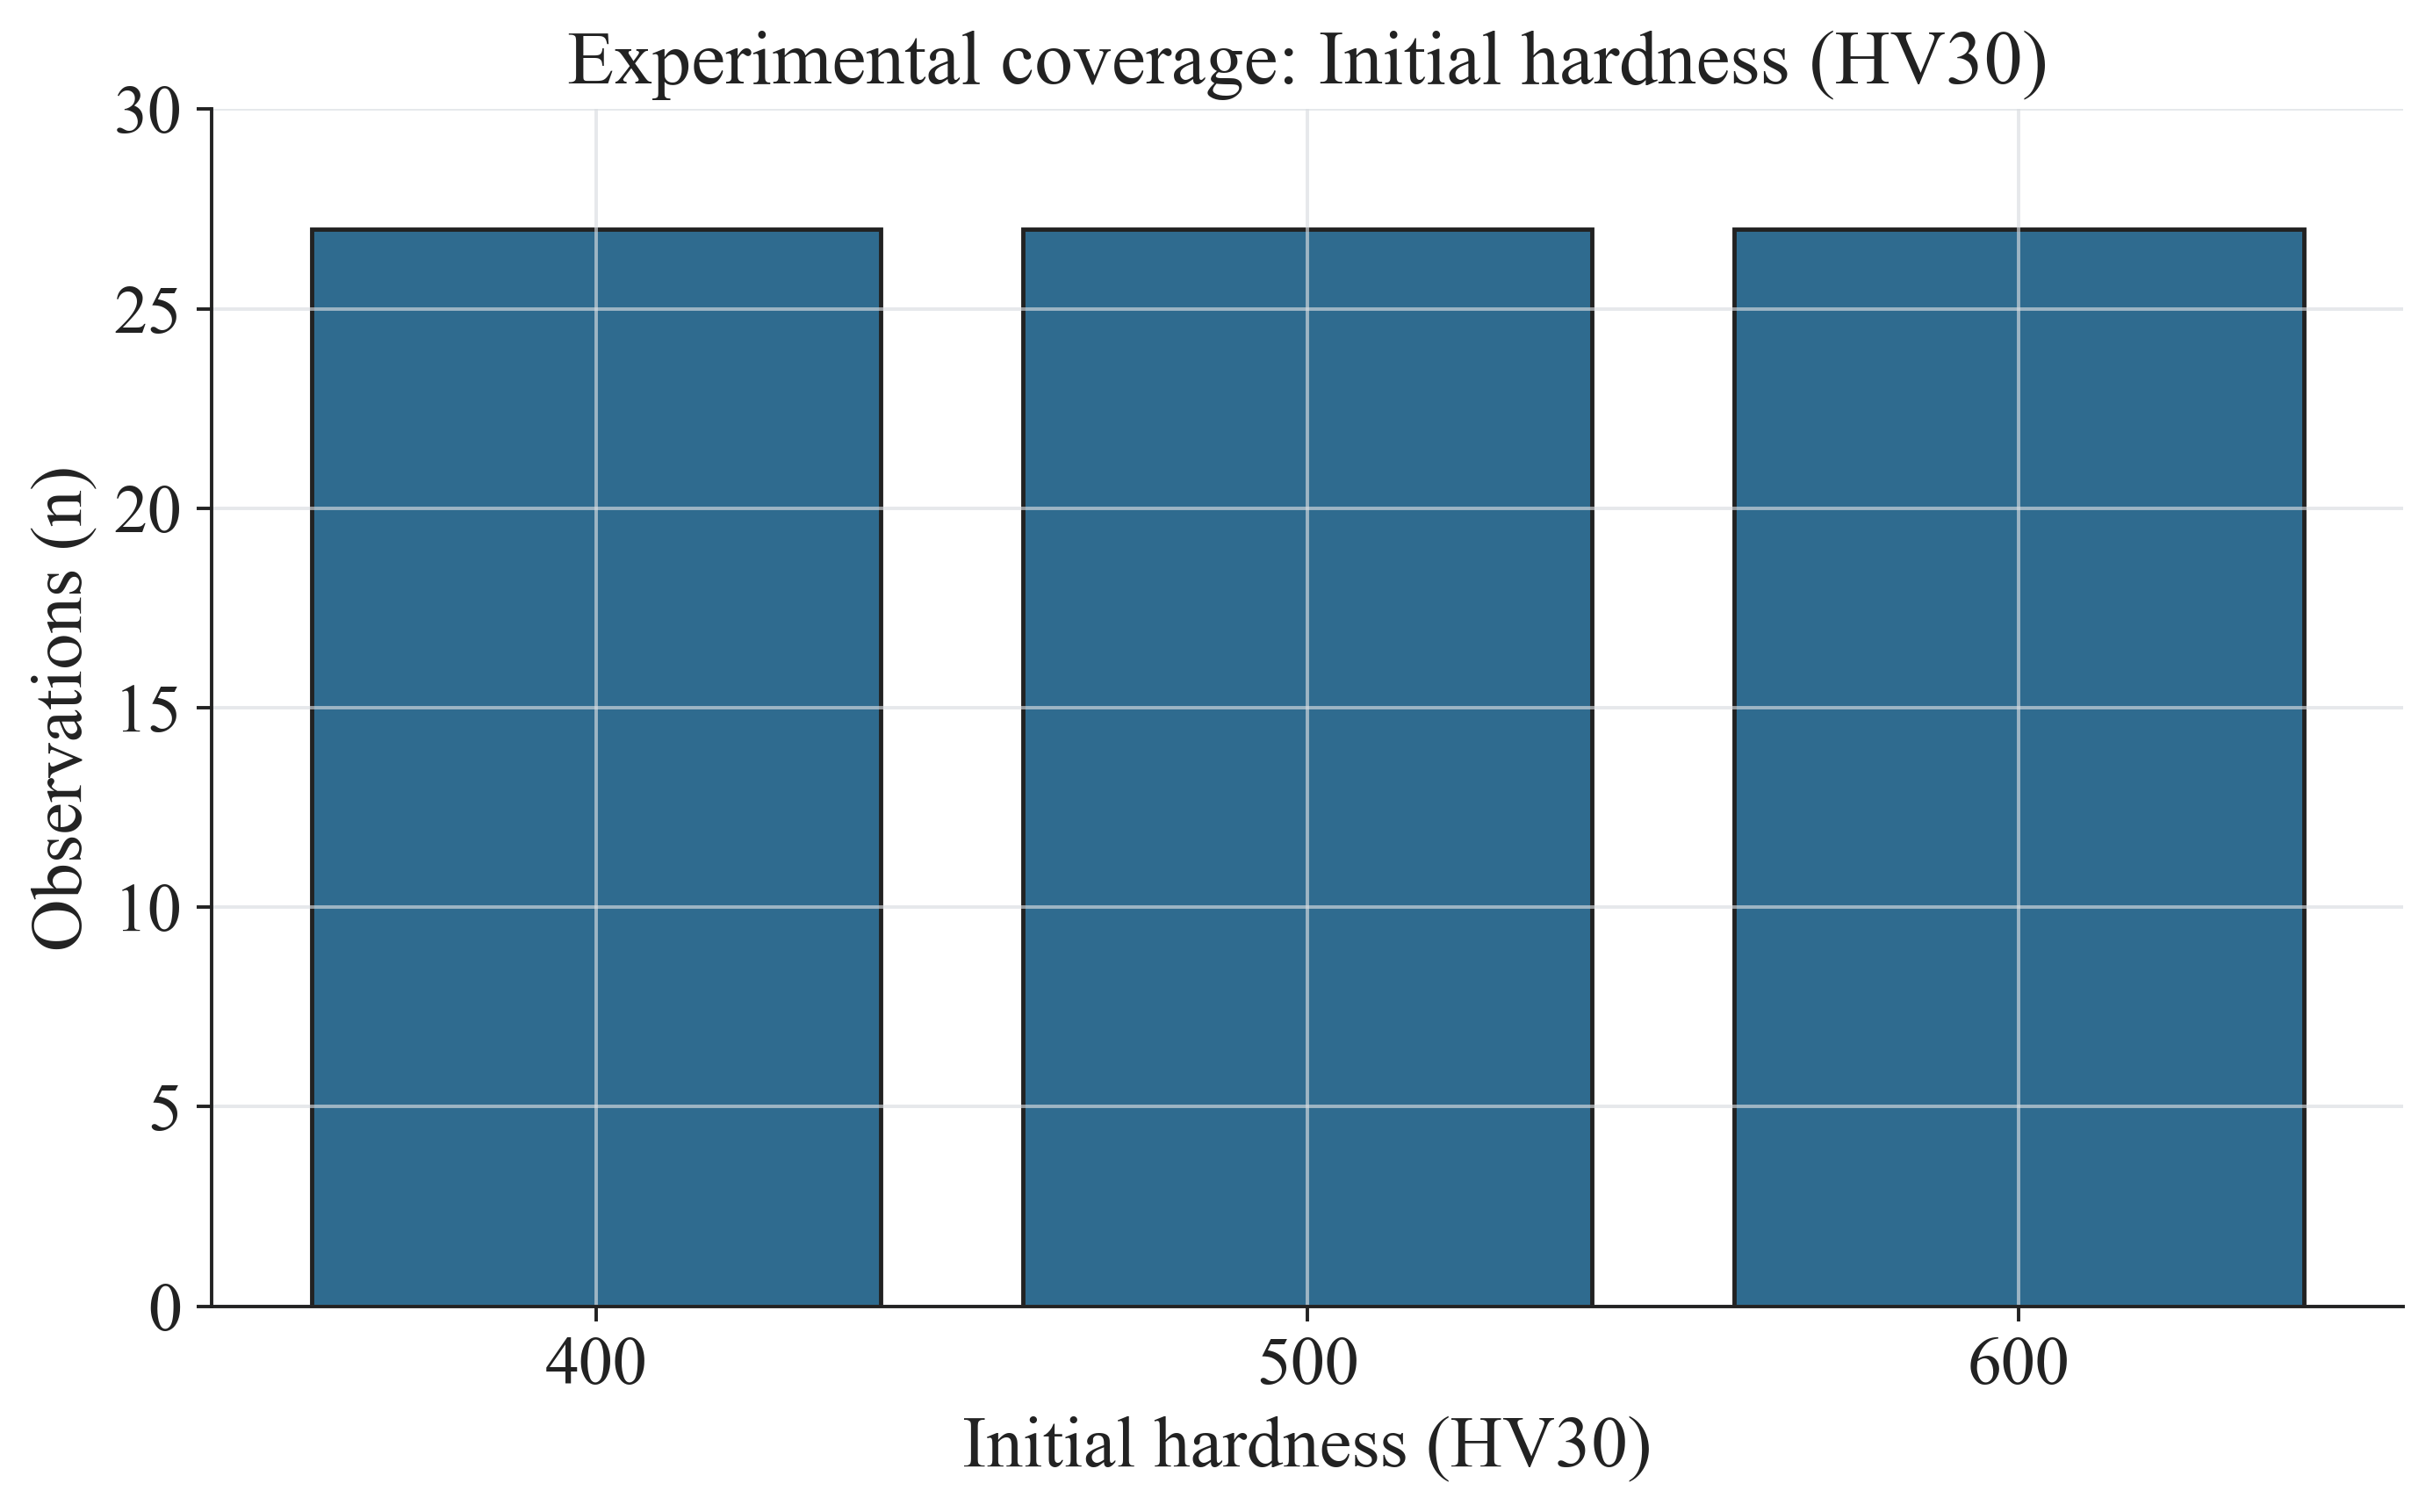

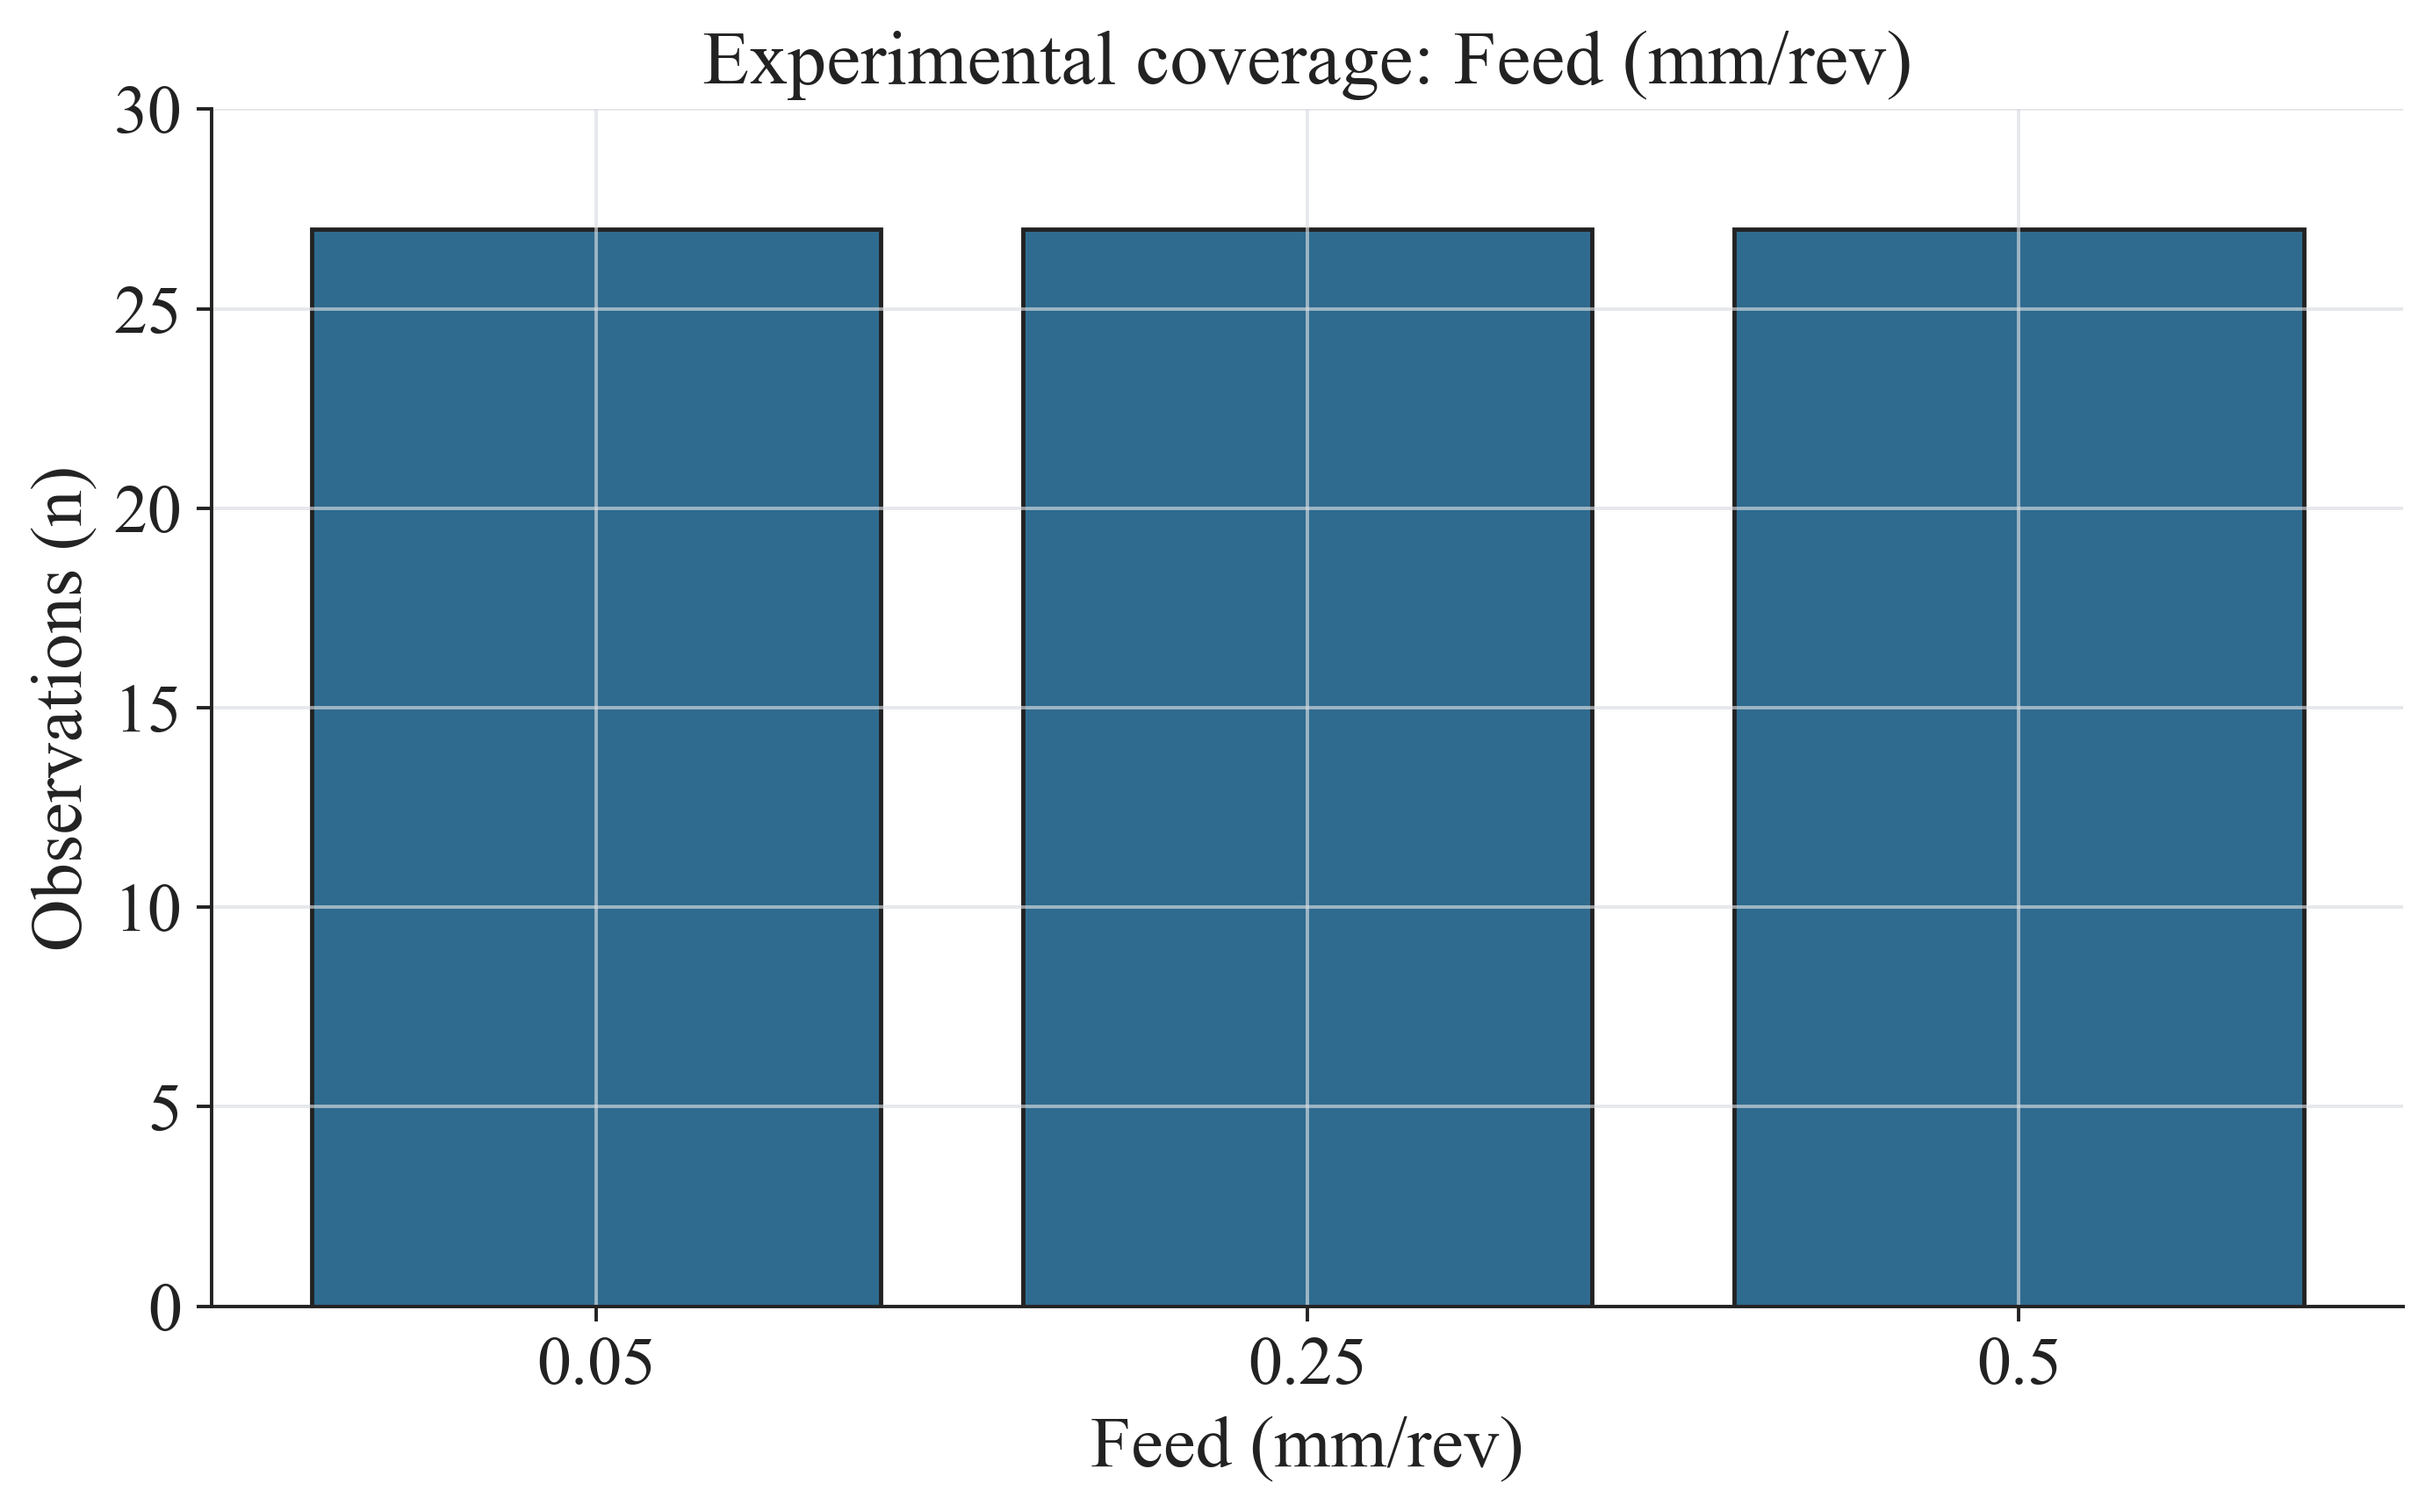

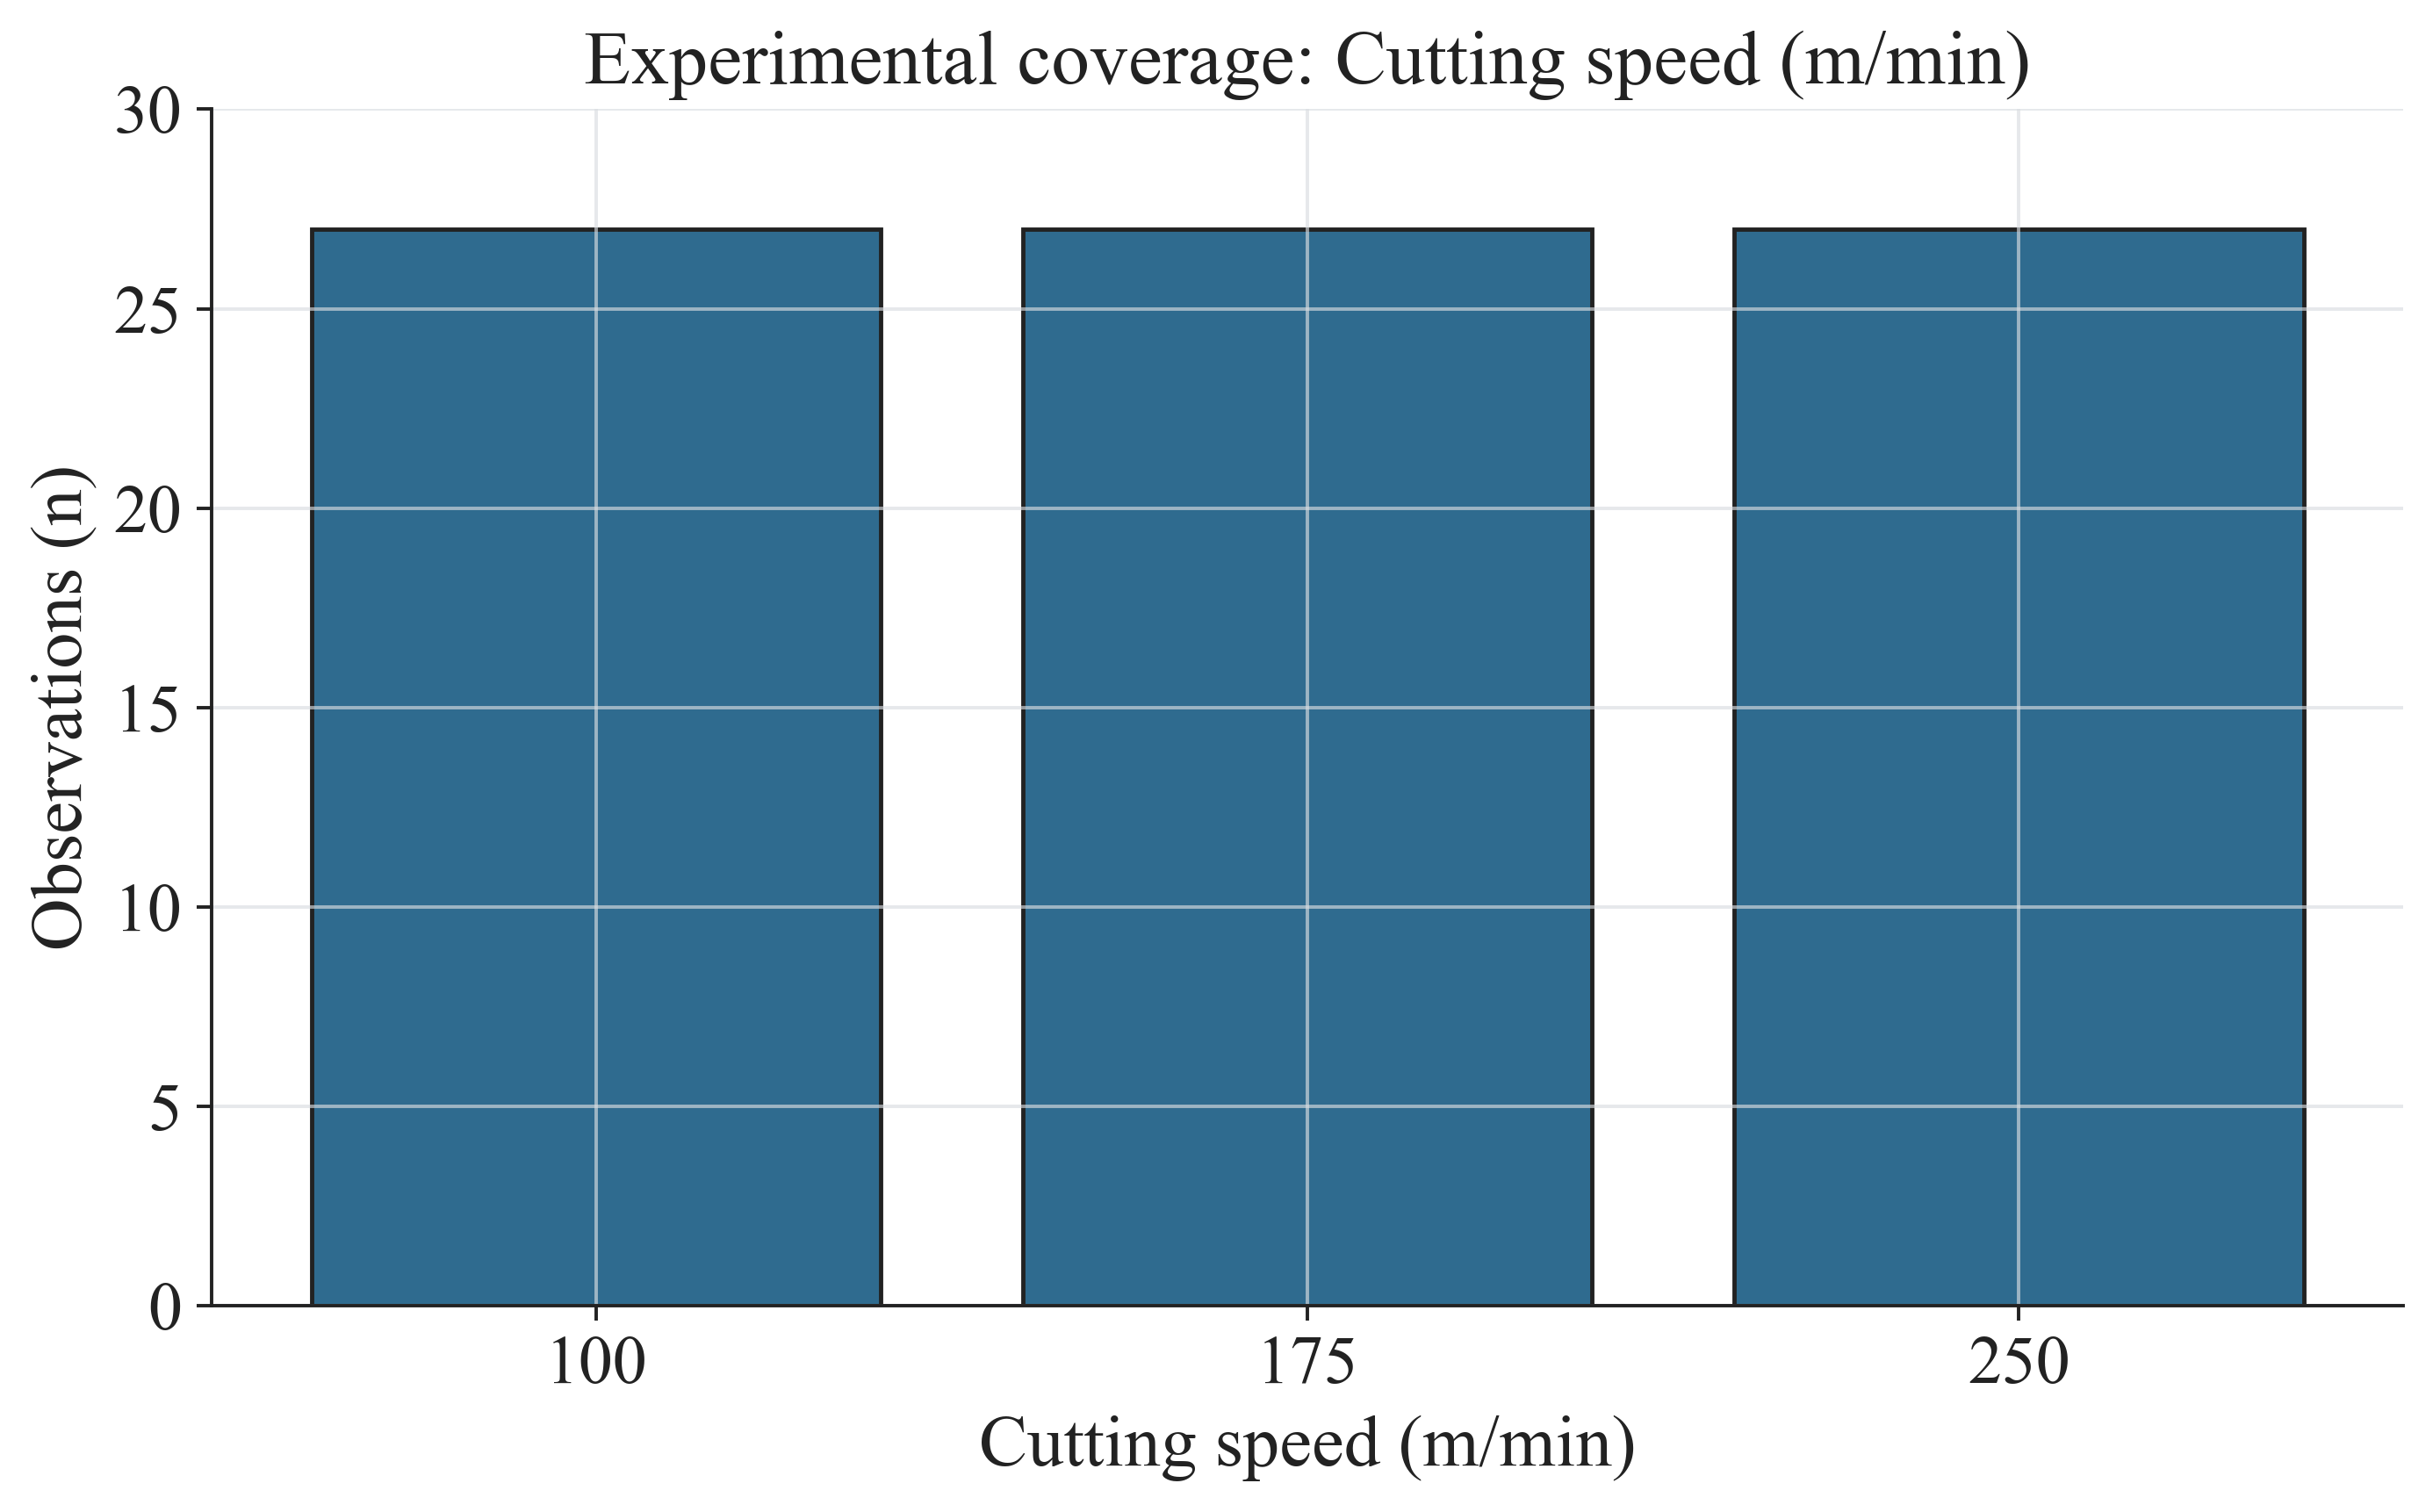

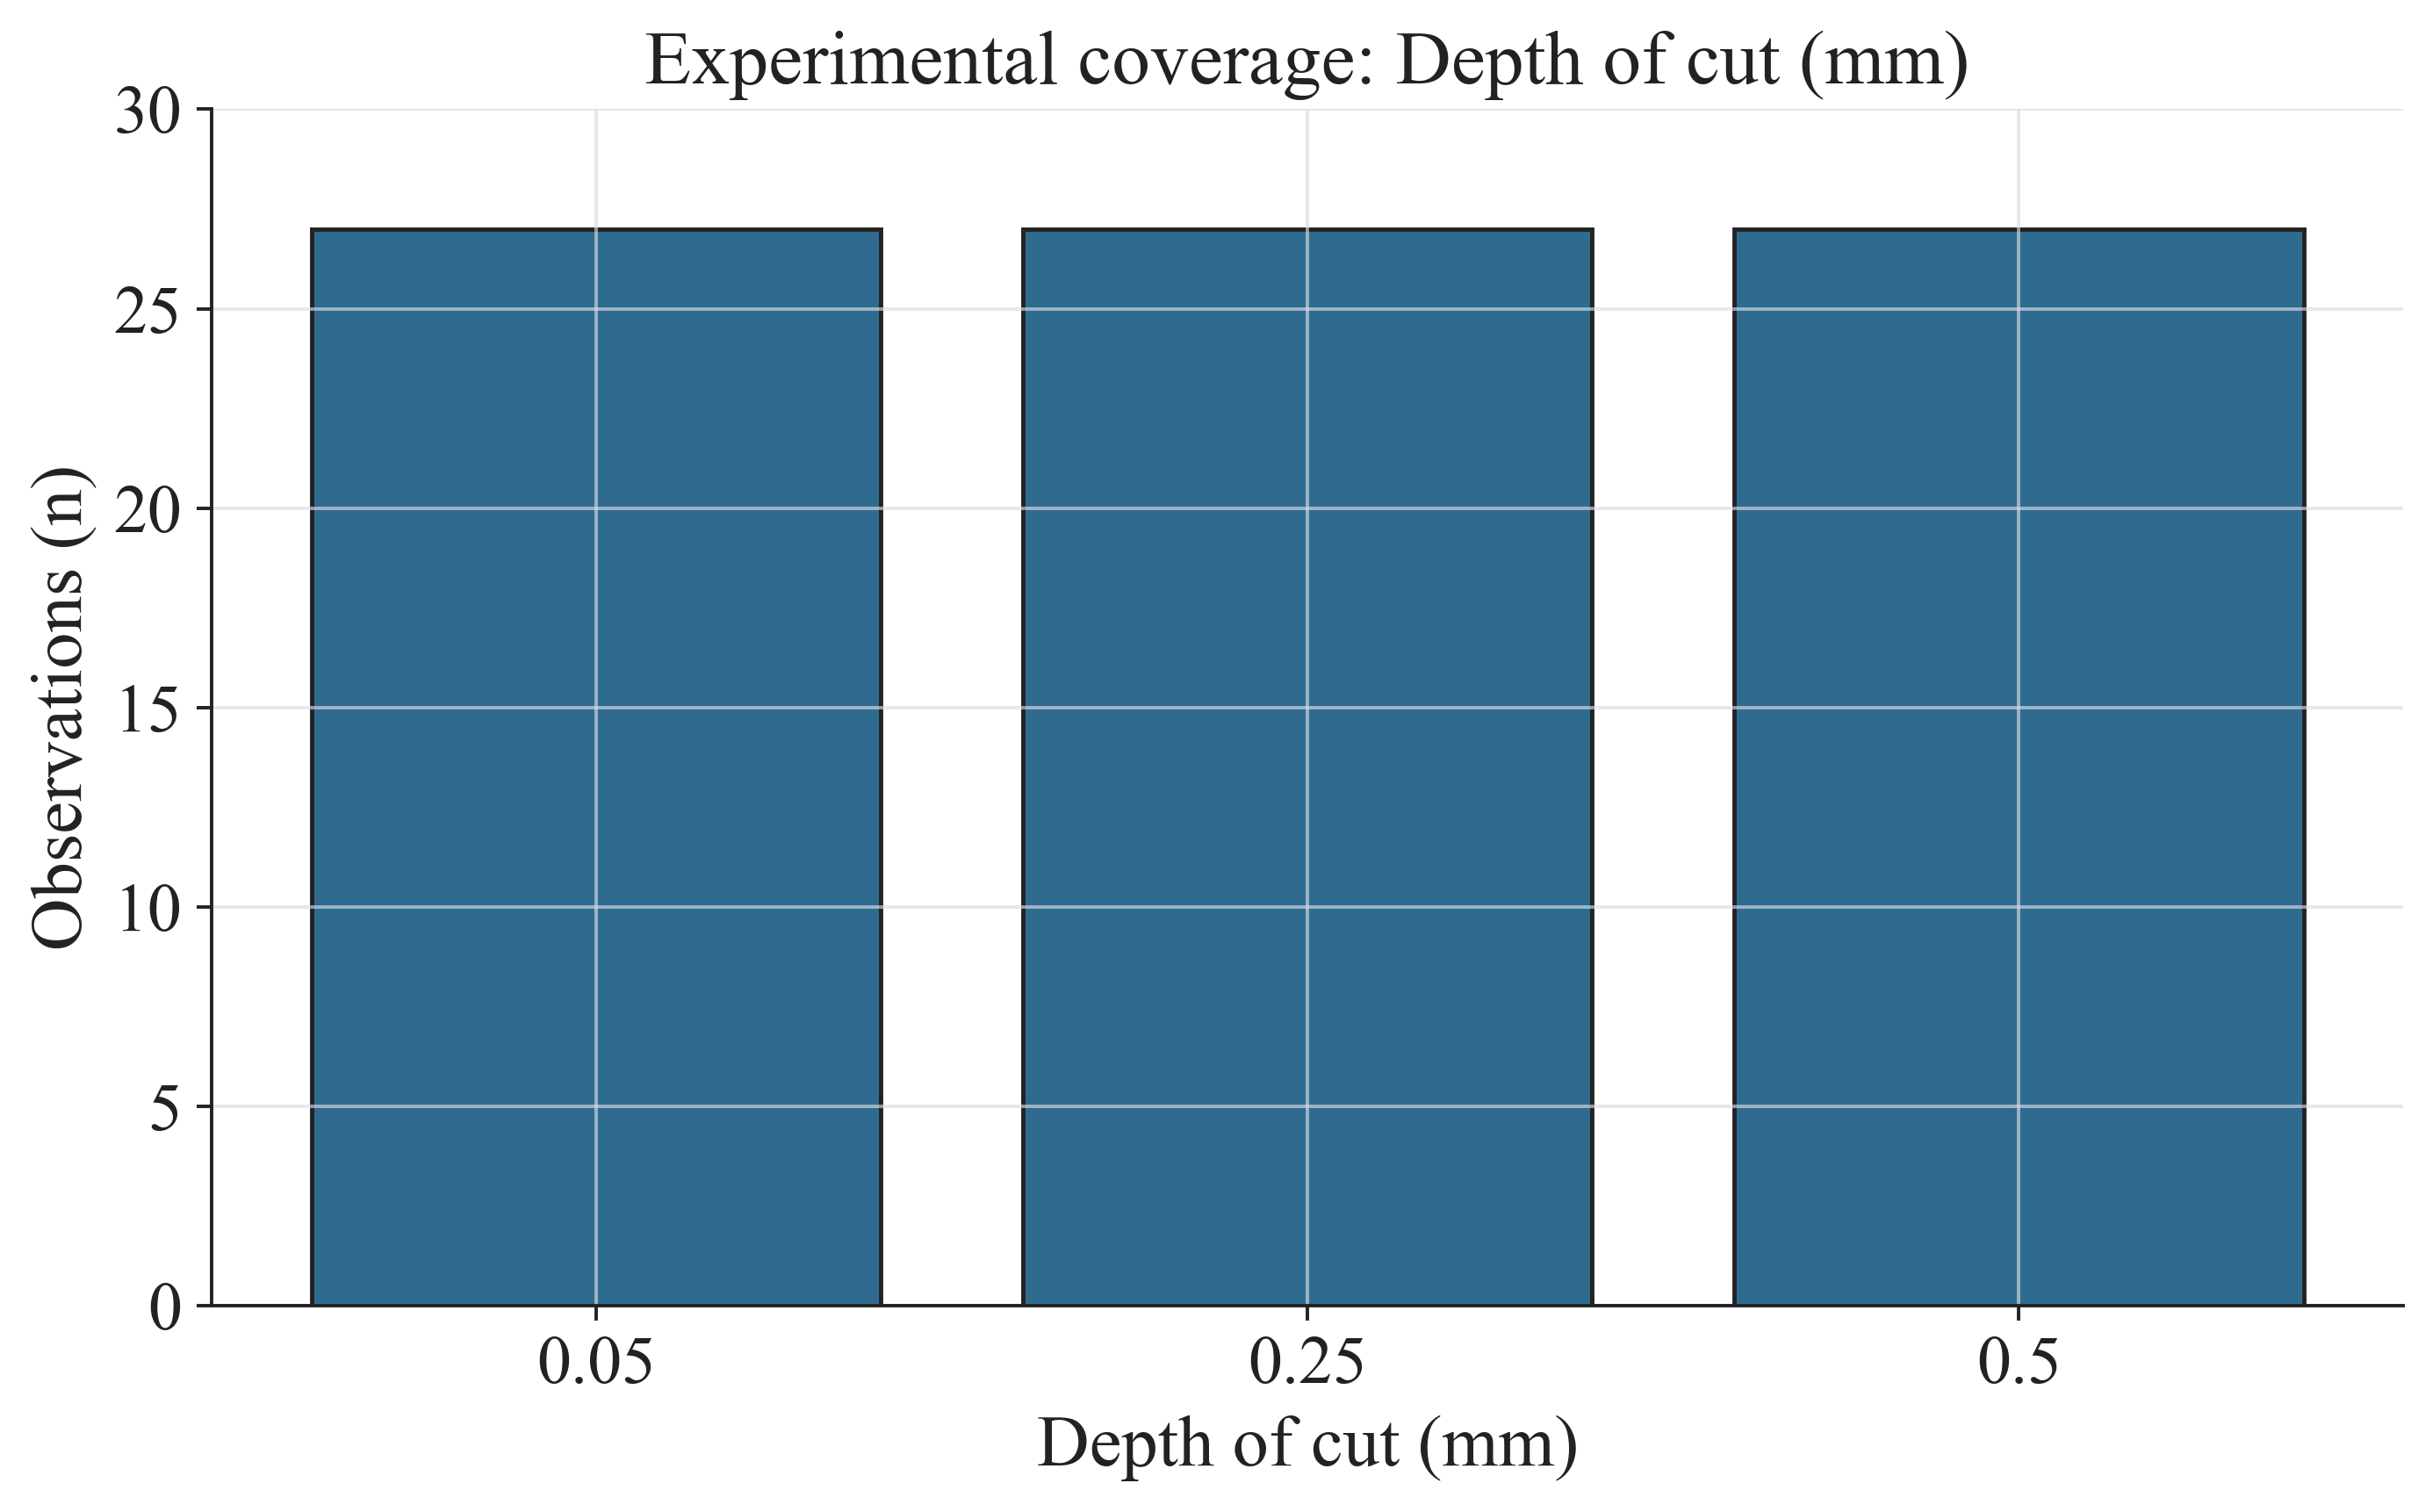

In [7]:
coverage_source = pd.concat([
    pd.DataFrame({"factor": feature, "level": data[feature].astype(str), "count": 1})
    for feature in PREDICTORS
]).groupby(["factor", "level"], as_index=False).size().rename(columns={"size": "observations"})

factor_specs = {
    "HV_init_HV30": ("Initial hardness (HV30)", "initial_hardness"),
    "feed_mm_rev": ("Feed (mm/rev)", "feed"),
    "cutting_speed_m_min": ("Cutting speed (m/min)", "cutting_speed"),
    "depth_of_cut_mm": ("Depth of cut (mm)", "depth_of_cut"),
}
for feature in PREDICTORS:
    label, slug = factor_specs[feature]
    part = coverage_source[coverage_source.factor.eq(feature)]
    fig, axis = plt.subplots(figsize=(8.2, 5.2))
    axis.bar(part.level, part.observations, color=PALETTE["blue"], edgecolor=PALETTE["black"])
    axis.set_title(f"Experimental coverage: {label}")
    axis.set_xlabel(label)
    axis.set_ylabel("Observations (n)")
    axis.set_ylim(0, 30)
    fig.tight_layout()
    save_scientific_figure(fig, f"dataset_factor_coverage_{slug}", part)
    display(fig)
    plt.close(fig)

Every factor level contains exactly 27 rows, confirming balanced marginal coverage. The balance follows from the complete 3⁴ design rather than from observational sampling. The next stage can therefore retain all four measured inputs without class- or level-balancing operations.


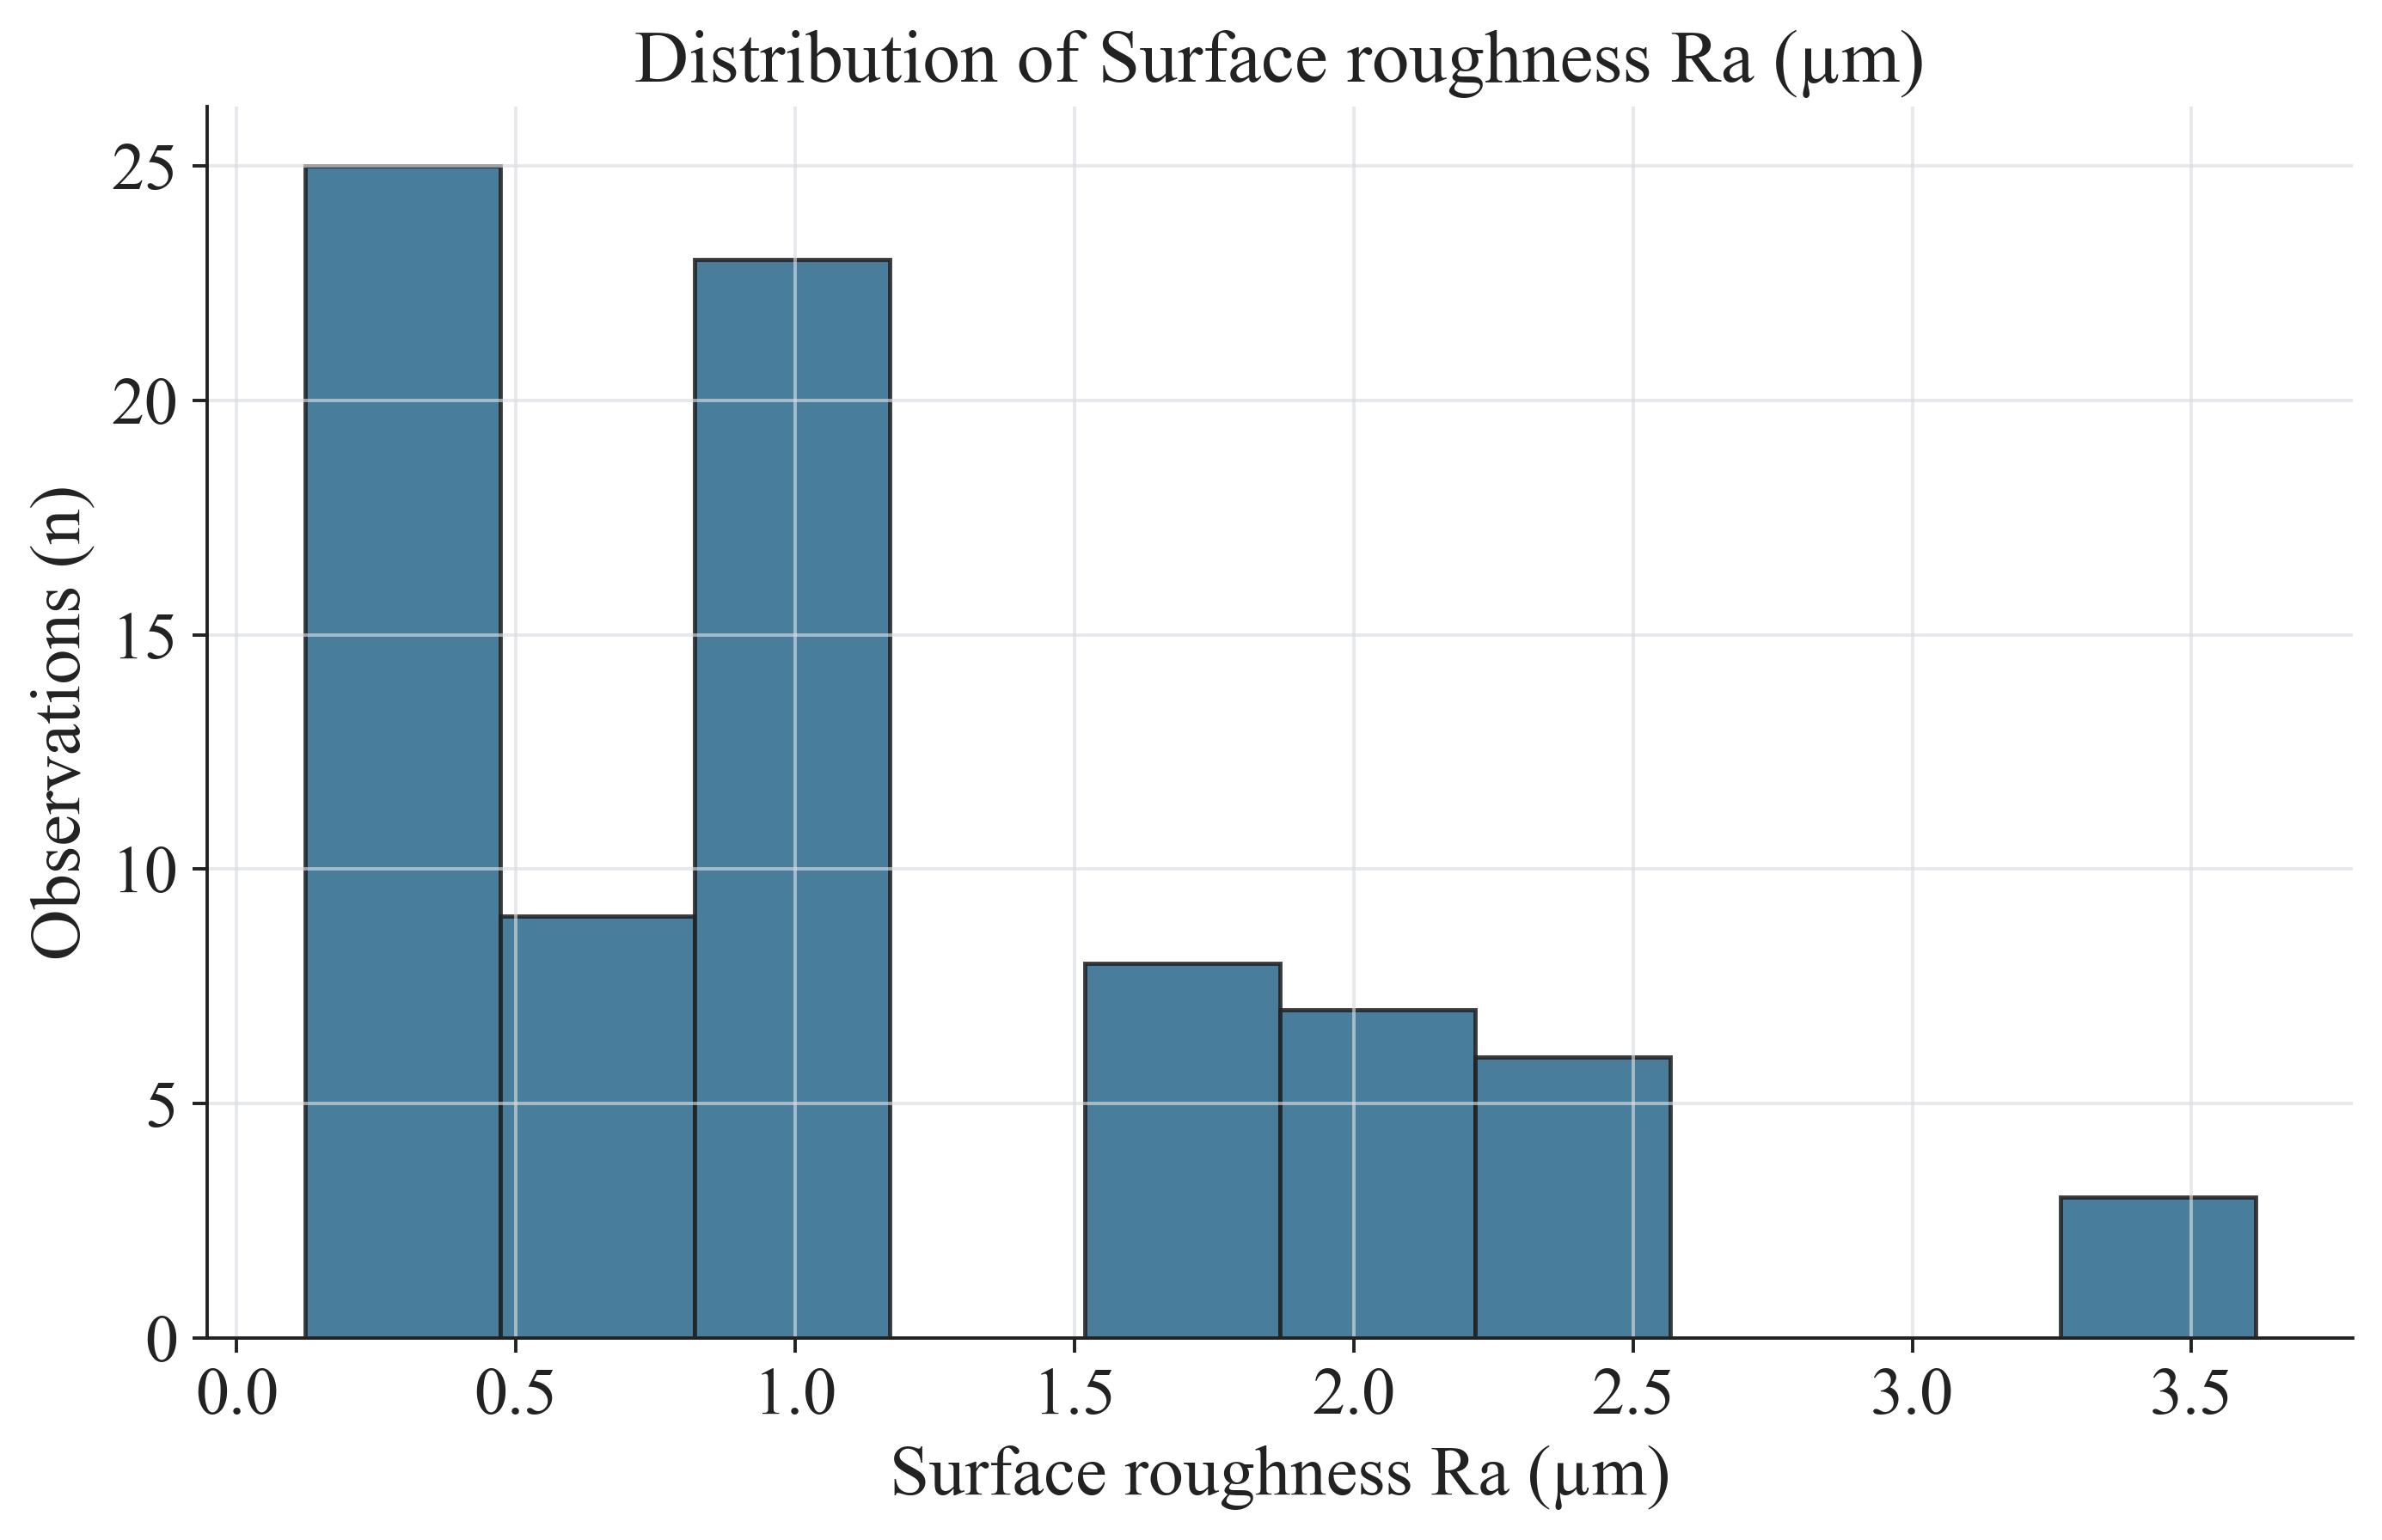

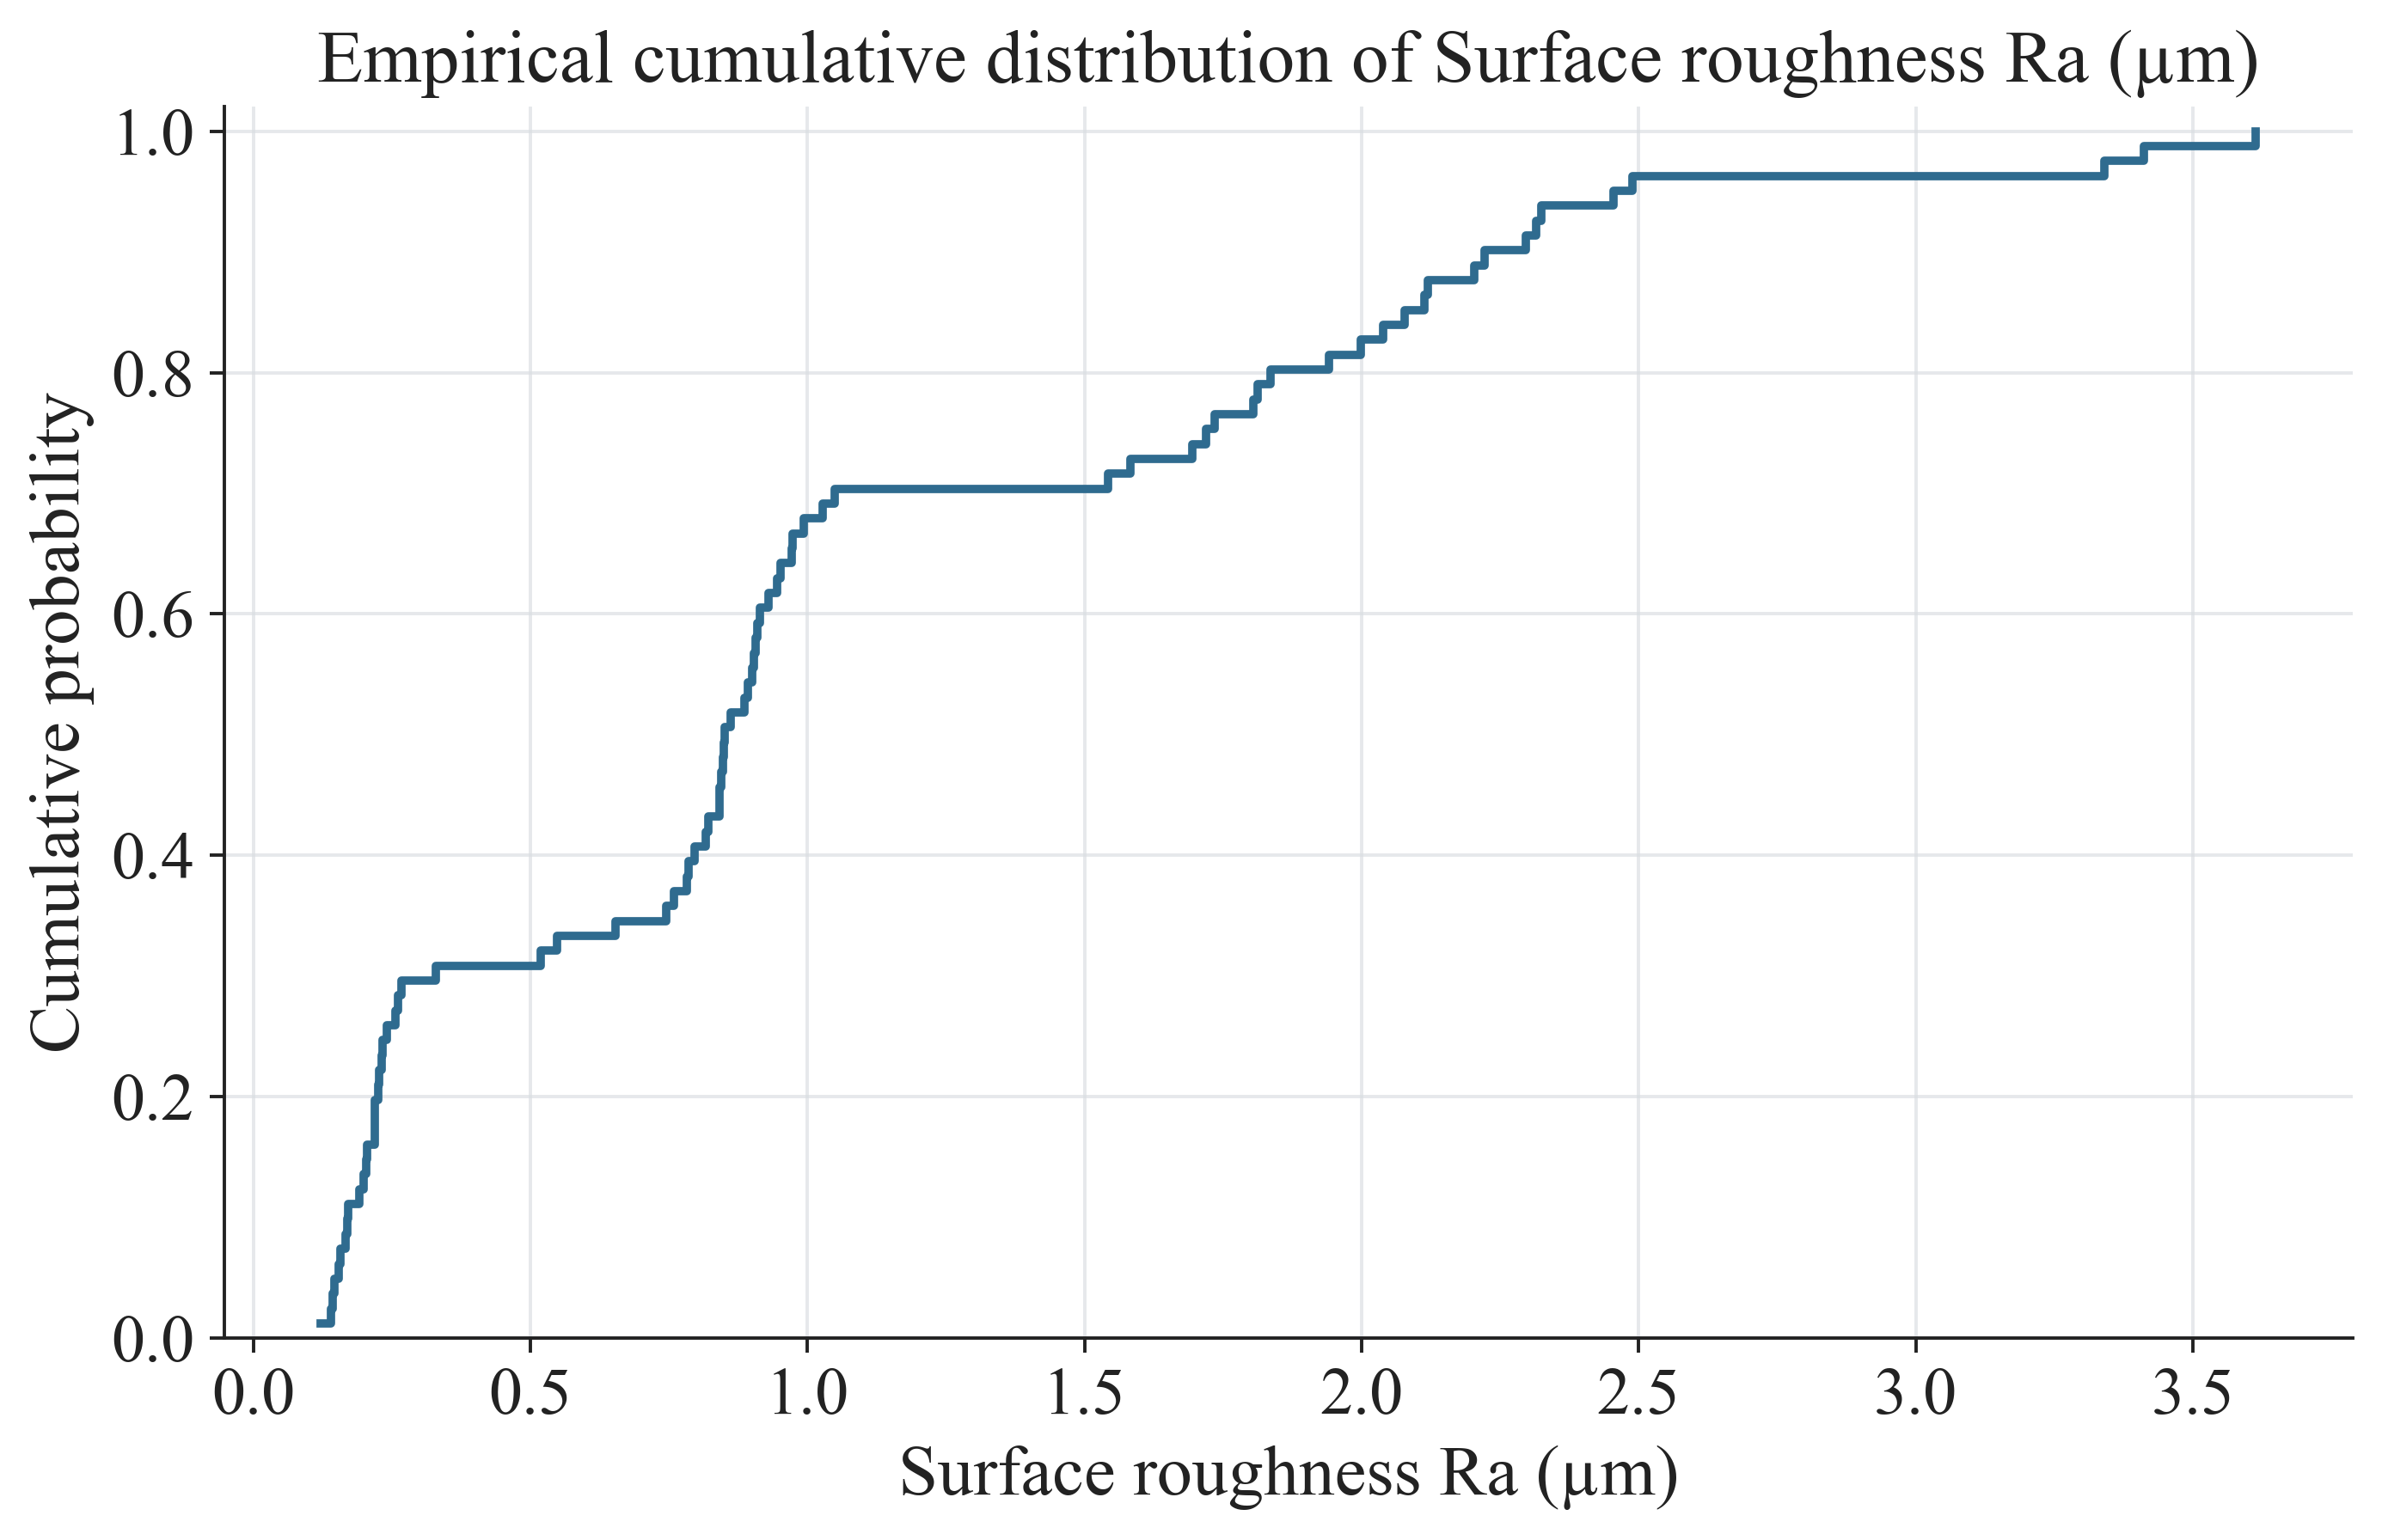

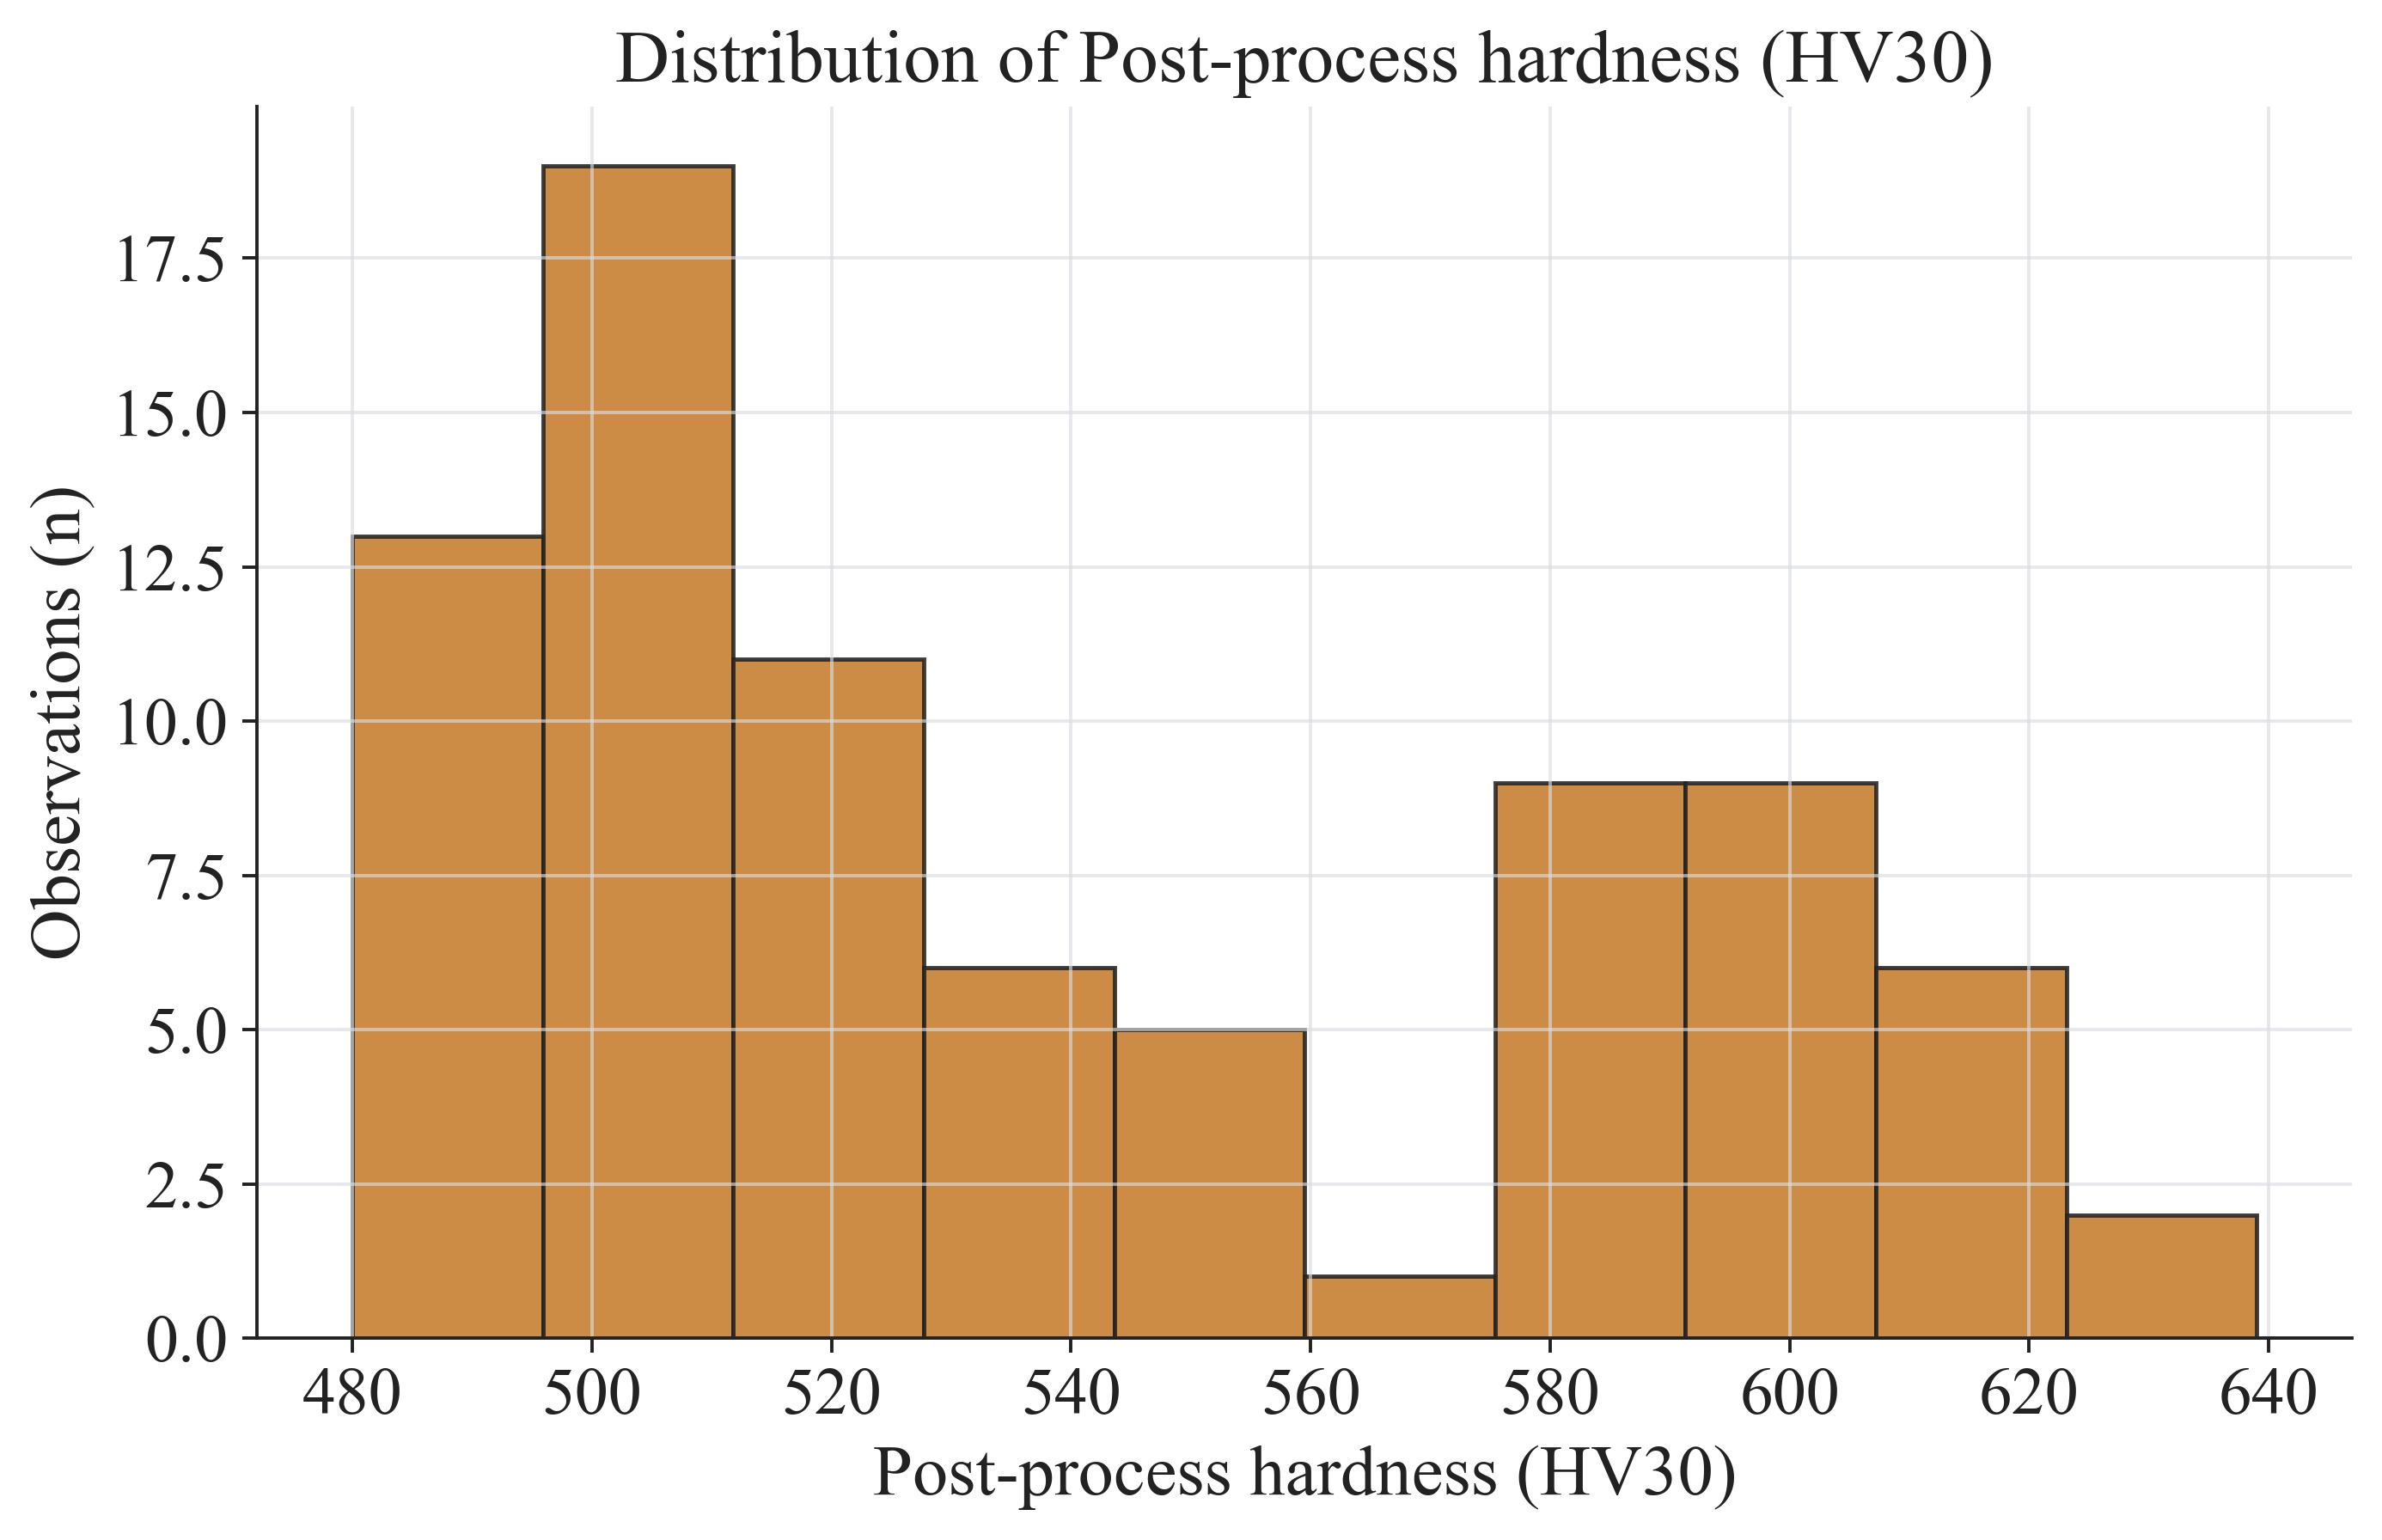

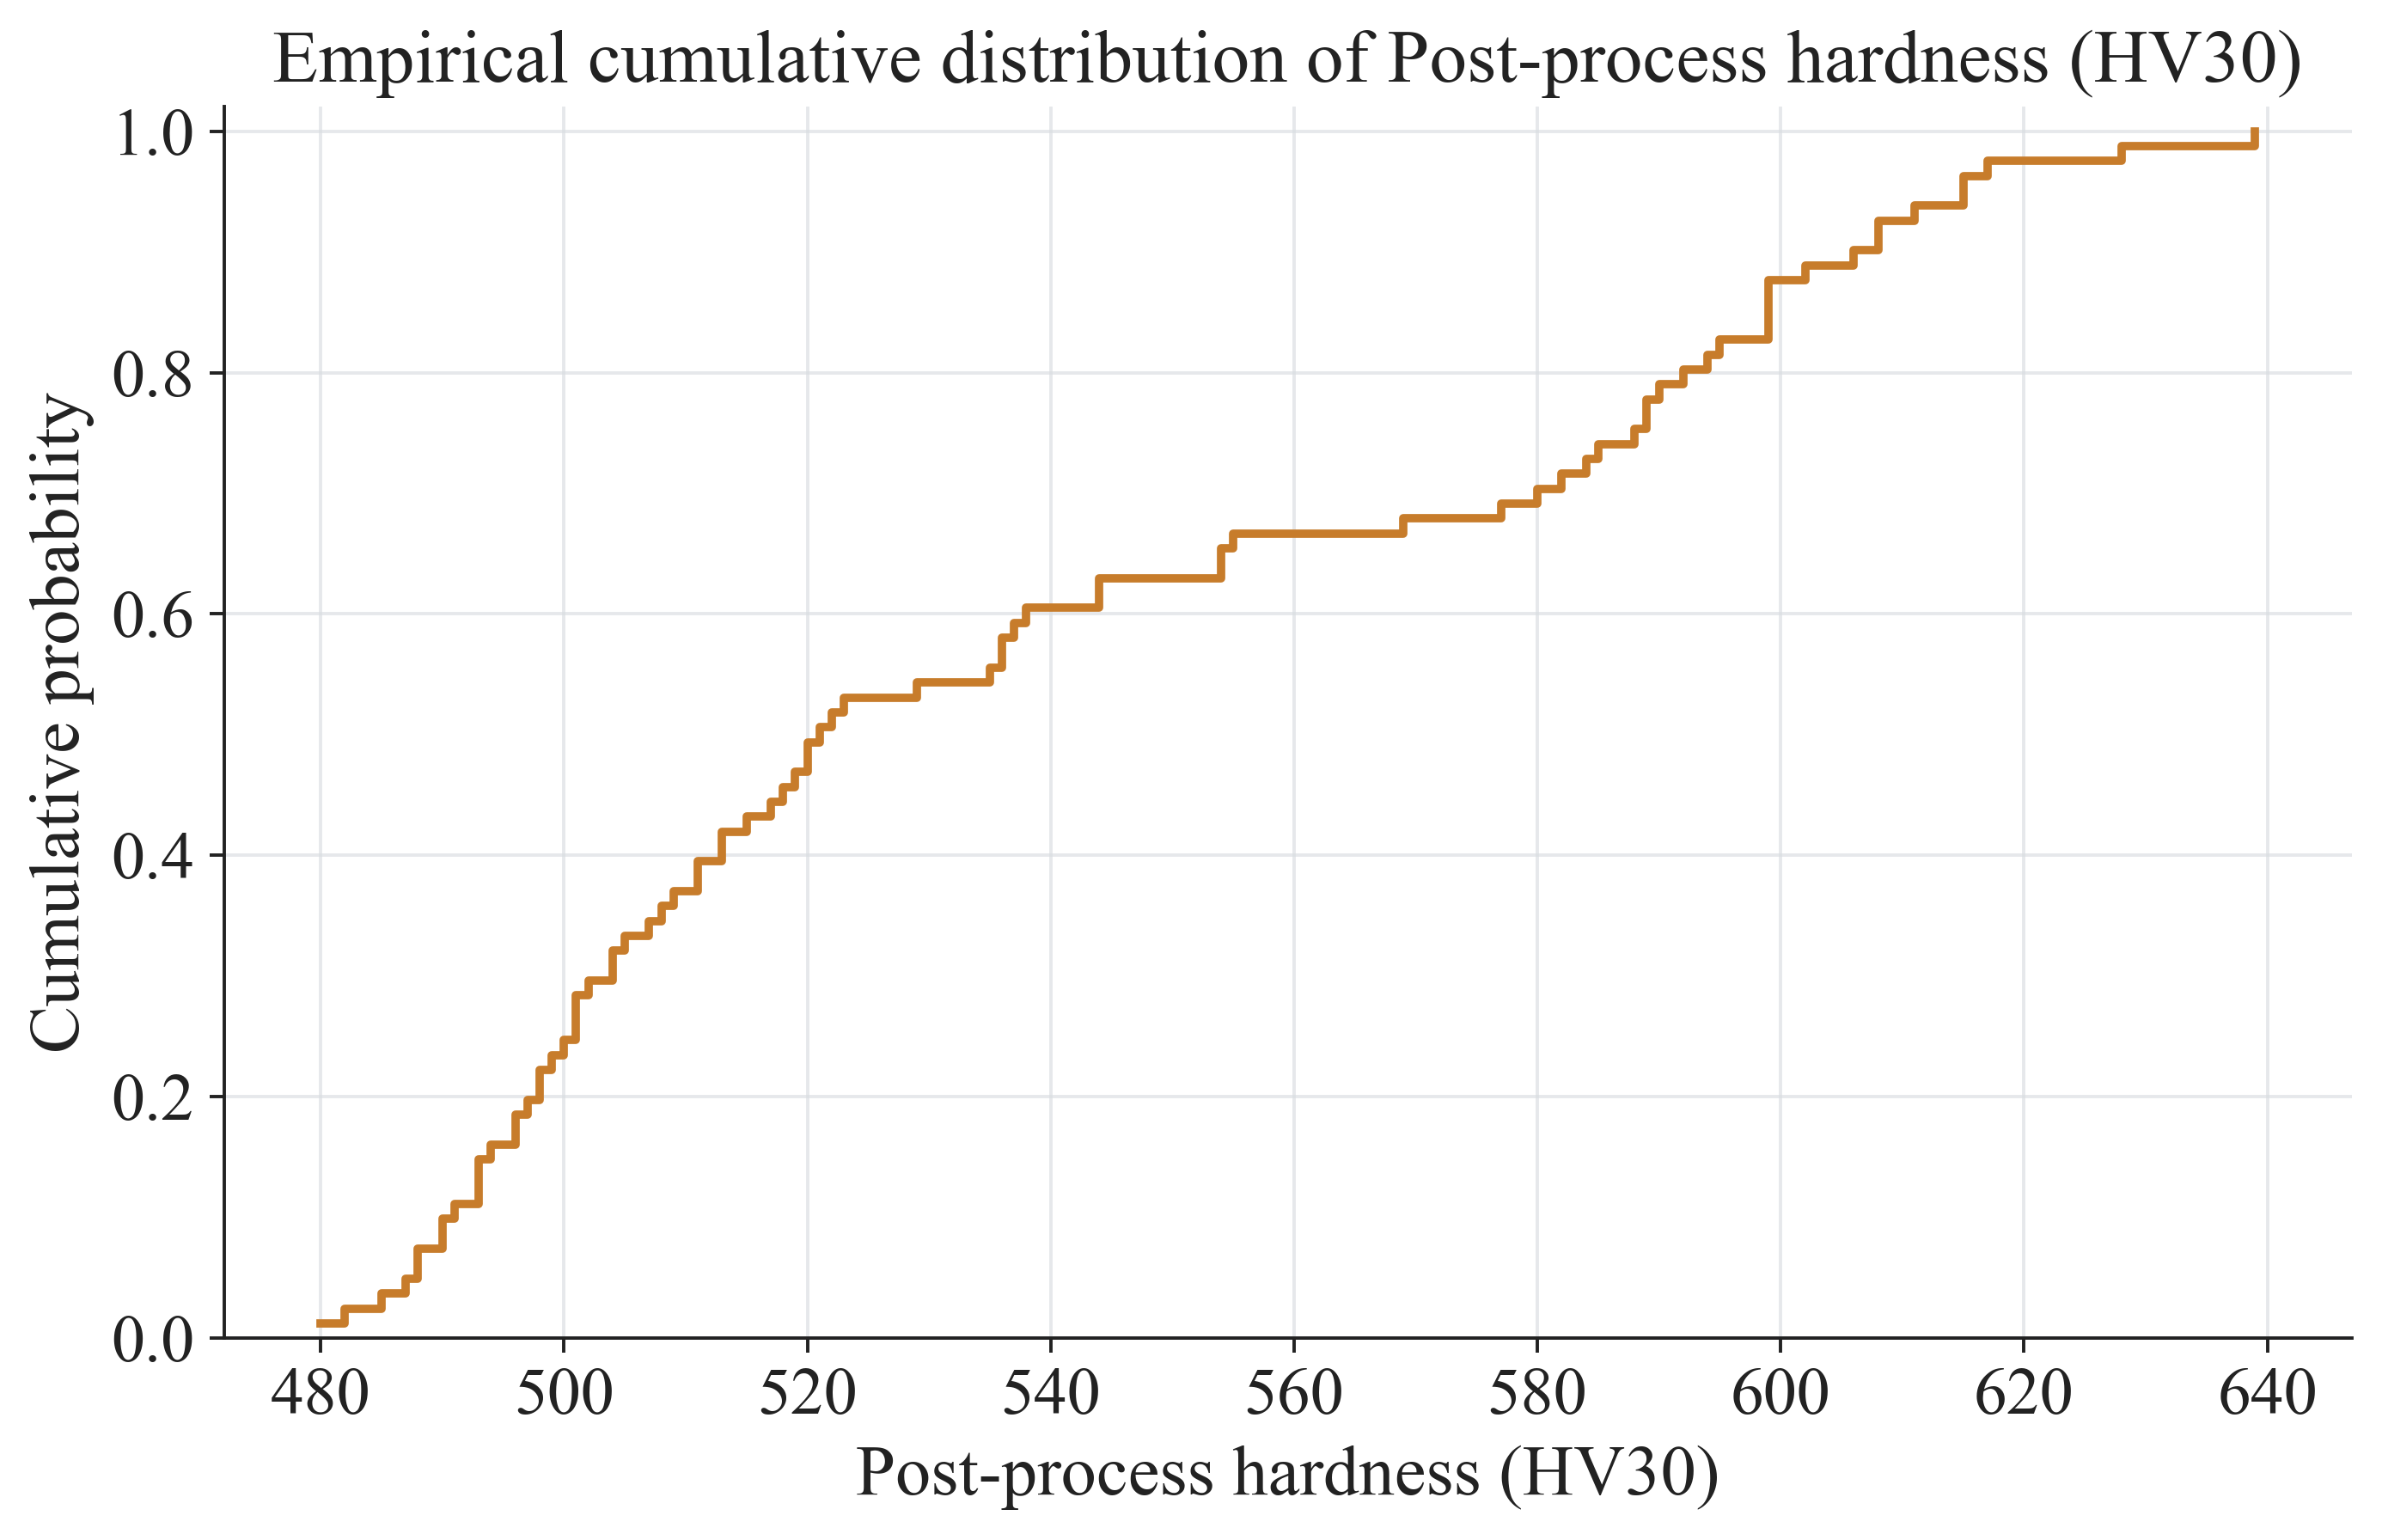

In [8]:
target_source = data[TARGETS].copy()
target_specs = [
    (TARGETS[0], "Surface roughness Ra (µm)", "ra", PALETTE["blue"]),
    (TARGETS[1], "Post-process hardness (HV30)", "hv30", PALETTE["orange"]),
]
for target, label, slug, color in target_specs:
    values = data[target].to_numpy()

    fig, axis = plt.subplots(figsize=(8.2, 5.4))
    axis.hist(values, bins=10, color=color, edgecolor=PALETTE["black"], alpha=0.88)
    axis.set_title(f"Distribution of {label}")
    axis.set_xlabel(label)
    axis.set_ylabel("Observations (n)")
    fig.tight_layout()
    save_scientific_figure(fig, f"target_histogram_{slug}", target_source[[target]])
    display(fig)
    plt.close(fig)

    sorted_values = np.sort(values)
    ecdf = np.arange(1, len(values) + 1) / len(values)
    ecdf_source = pd.DataFrame({target: sorted_values, "cumulative_probability": ecdf})
    fig, axis = plt.subplots(figsize=(8.2, 5.4))
    axis.step(sorted_values, ecdf, where="post", color=color)
    axis.set_title(f"Empirical cumulative distribution of {label}")
    axis.set_xlabel(label)
    axis.set_ylabel("Cumulative probability")
    axis.set_ylim(0, 1.02)
    fig.tight_layout()
    save_scientific_figure(fig, f"target_ecdf_{slug}", ecdf_source)
    display(fig)
    plt.close(fig)

In [9]:
target_stats = data[TARGETS].agg(["min", "median", "mean", "std", "max", "skew"]).T
target_stats.index = ["Surface roughness Ra (µm)", "Post-process hardness (HV30)"]
display_grouped_table(target_stats.reset_index(names="Target").round(4), "Target distribution statistics")


**Target distribution statistics — Complete table (part 1/2)**

Target,min,median,mean,std,max
Surface roughness Ra (µm),0.122000,0.851000,1.050900,0.852600,3.614000
Post-process hardness (HV30),480.000000,521.000000,539.802500,45.624900,639.000000


**Target distribution statistics — Complete table (part 2/2)**

Target,skew
Surface roughness Ra (µm),1.024700
Post-process hardness (HV30),0.508100


`Ra` and post-process `HV30` occupy distinct physical scales and exhibit different distributional shapes. Consequently, MAE and RMSE will remain target-specific and will never be averaged in raw units. Dimensionless NRMSE is reserved for joint ordering, while R² is a secondary scale-free summary.


## 5. Dependence, mutual information, and response relationships


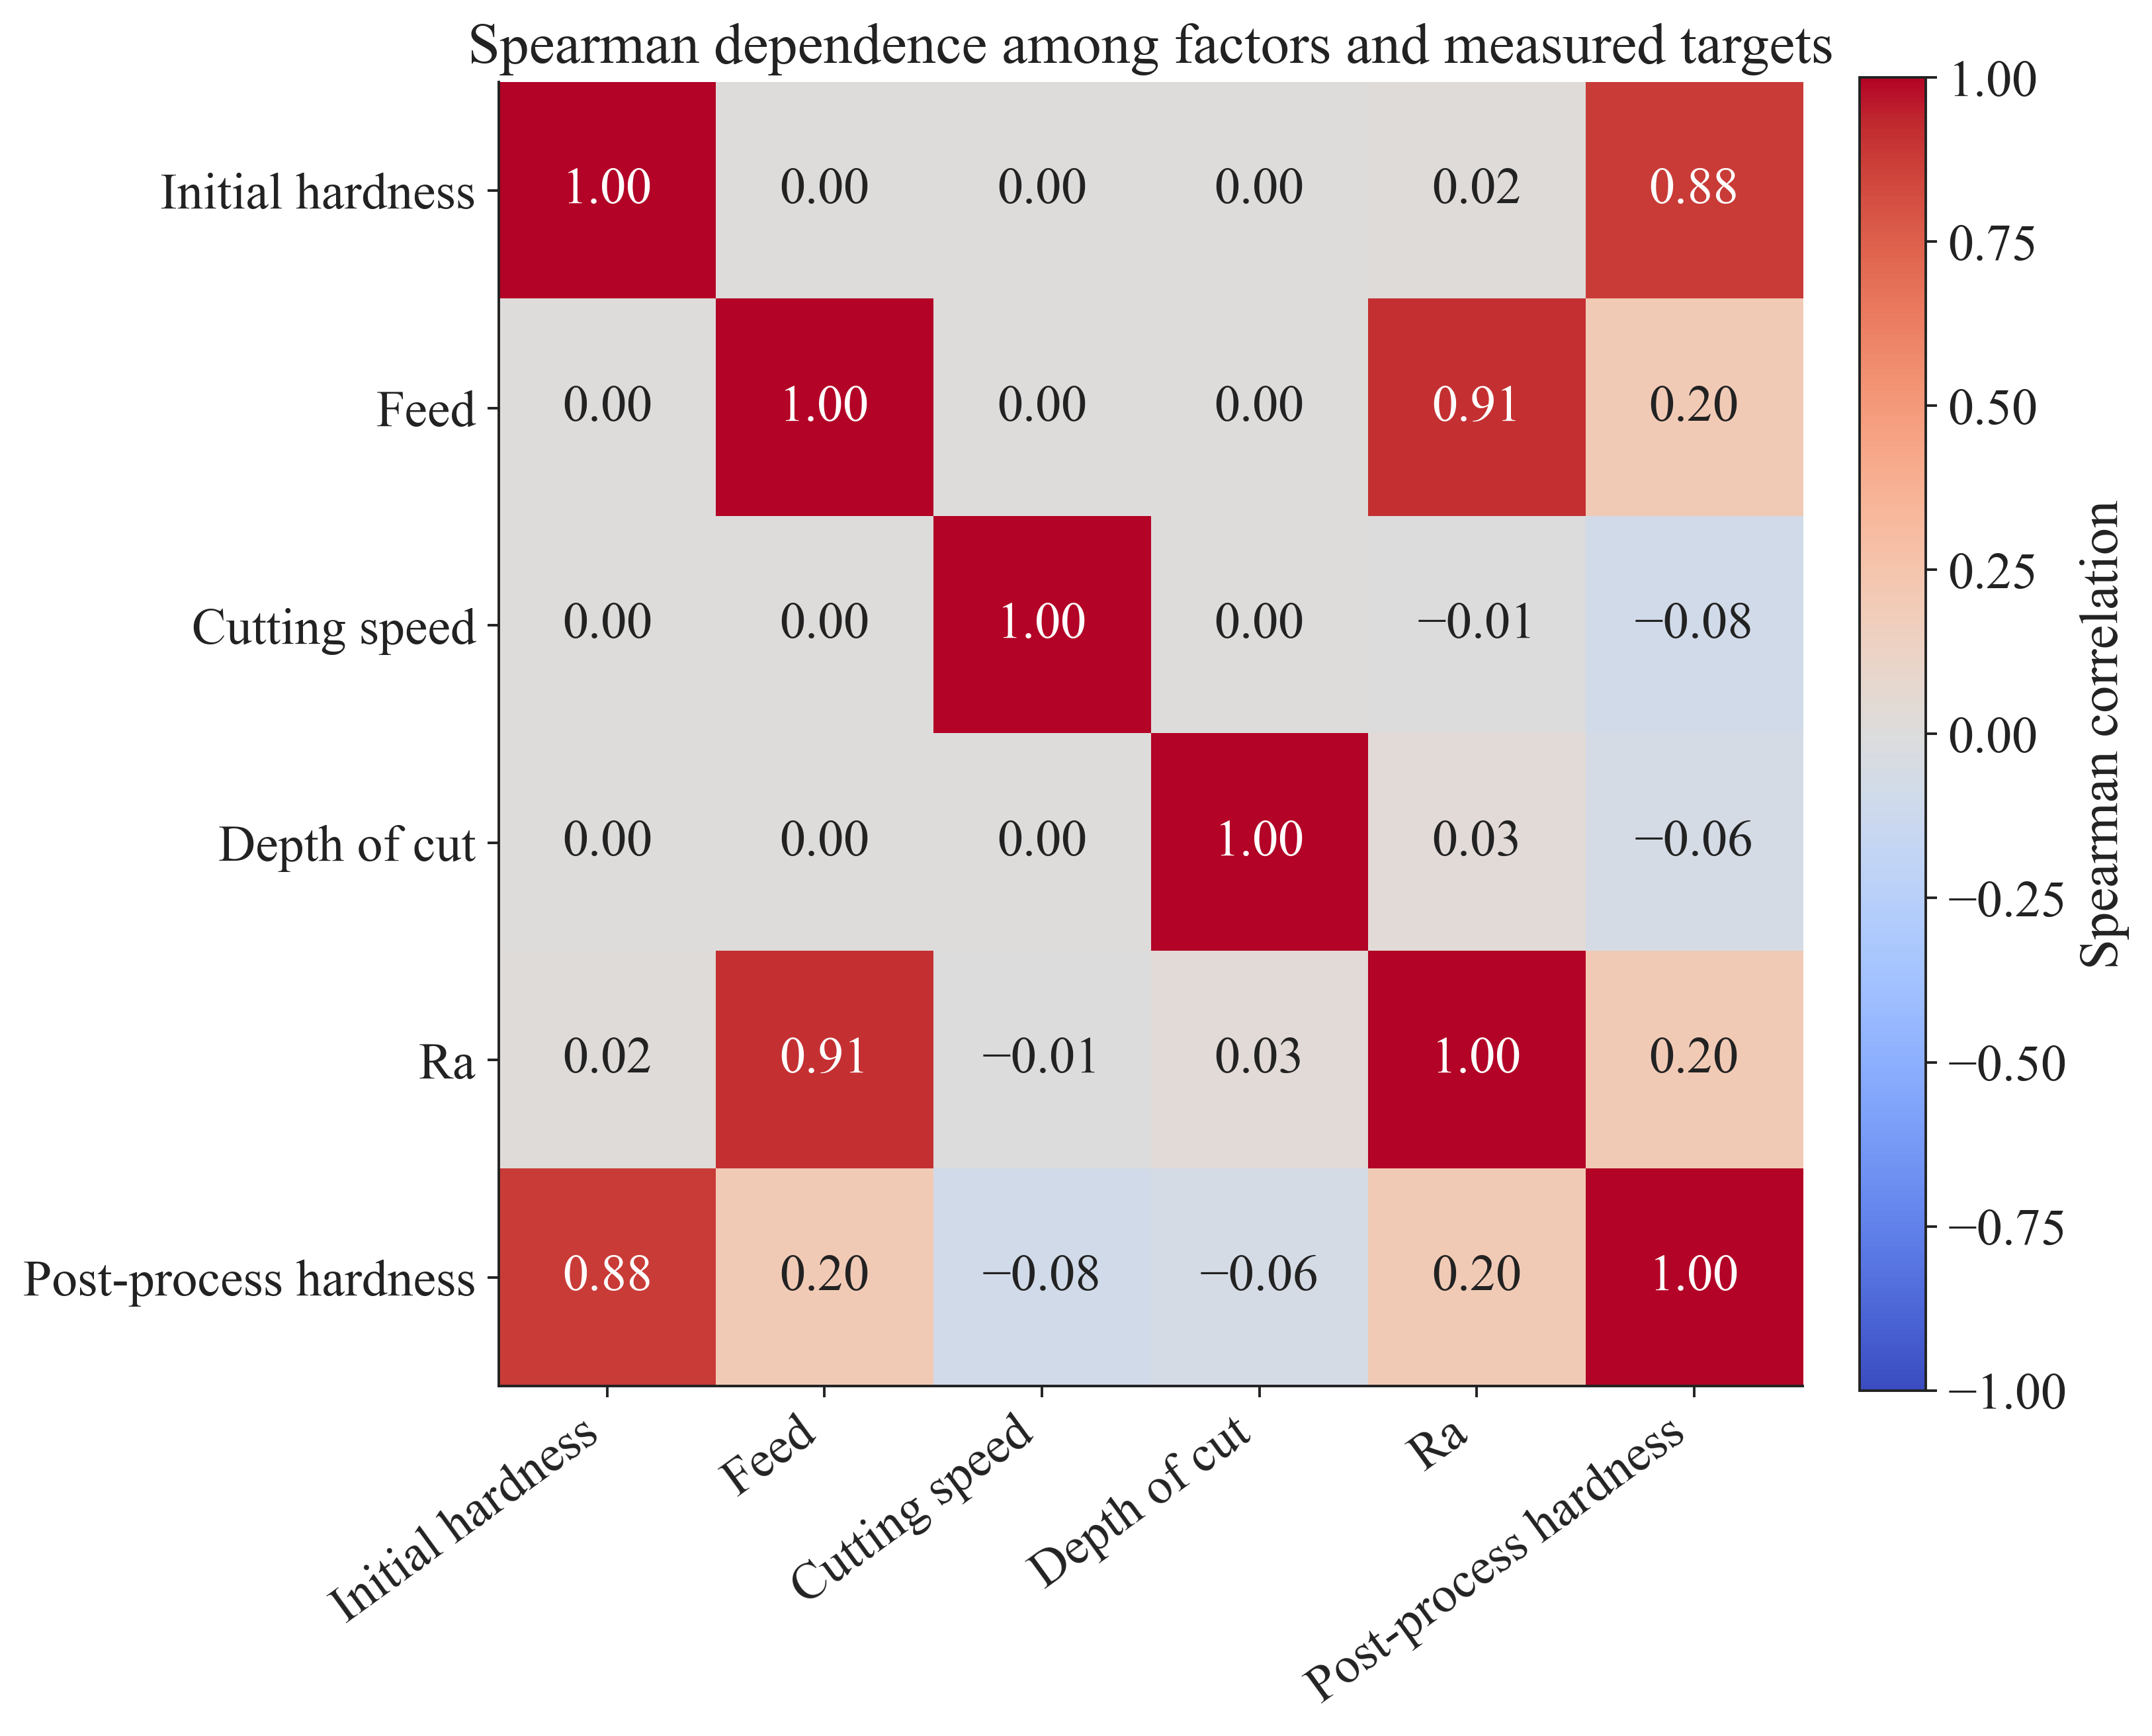

In [10]:
correlation_columns = PREDICTORS + TARGETS
correlation = data[correlation_columns].corr(method="spearman")
short_labels = ["Initial hardness", "Feed", "Cutting speed", "Depth of cut", "Ra", "Post-process hardness"]
fig, axis = plt.subplots(figsize=(9.2, 8.0))
image = axis.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm", aspect="equal")
axis.set_xticks(range(len(short_labels)), labels=short_labels, rotation=36, ha="right")
axis.set_yticks(range(len(short_labels)), labels=short_labels)
axis.set_title("Spearman dependence among factors and measured targets")
axis.grid(False)
for row in range(len(short_labels)):
    for column in range(len(short_labels)):
        value = correlation.iloc[row, column]
        axis.text(column, row, format_scientific_number(value, decimals=2),
                  ha="center", va="center", fontsize=16,
                  color="white" if abs(value) > 0.55 else PALETTE["black"])
colorbar = fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
colorbar.set_label("Spearman correlation")
colorbar.ax.tick_params(labelsize=16)
fig.tight_layout()
save_scientific_figure(fig, "eda_spearman_correlation", correlation.reset_index())
display(fig)
plt.close(fig)

The matrix is descriptive: it identifies monotonic association, not causality. Balanced orthogonal factor levels can yield weak marginal correlations even when interactions are important. Model selection must therefore remain inside grouped training folds and include nonlinear comparators.


In [11]:
from sklearn.feature_selection import mutual_info_regression

mi_rows = []
for target in TARGETS:
    values = mutual_info_regression(
        data[PREDICTORS], data[target], discrete_features=True, random_state=SEED
    )
    for feature, value in zip(PREDICTORS, values):
        mi_rows.append({"Target": target, "Predictor": feature, "Mutual information": value})
mutual_information = pd.DataFrame(mi_rows).sort_values(
    ["Target", "Mutual information"], ascending=[True, False]
)
mutual_information.to_csv(AUDIT_DIR / "mutual_information.csv", index=False)
display_grouped_table(mutual_information.round(4), "Predictor–target mutual information")


**Predictor–target mutual information — Complete table**

Target,Predictor,Mutual information
post_process_hardness_HV30,HV_init_HV30,0.781000
post_process_hardness_HV30,cutting_speed_m_min,0.095600
post_process_hardness_HV30,feed_mm_rev,0.006100
post_process_hardness_HV30,depth_of_cut_mm,0.000000
surface_roughness_Ra_um,feed_mm_rev,0.938400
surface_roughness_Ra_um,cutting_speed_m_min,0.114700
surface_roughness_Ra_um,HV_init_HV30,0.072700
surface_roughness_Ra_um,depth_of_cut_mm,0.000000


Mutual information provides a nonlinear, univariate relevance screen and is not used to select features globally. All four experimental factors remain scientifically required because the design is factorial and interaction effects may be invisible to marginal scores. The small sample makes the absolute MI magnitudes uncertain.


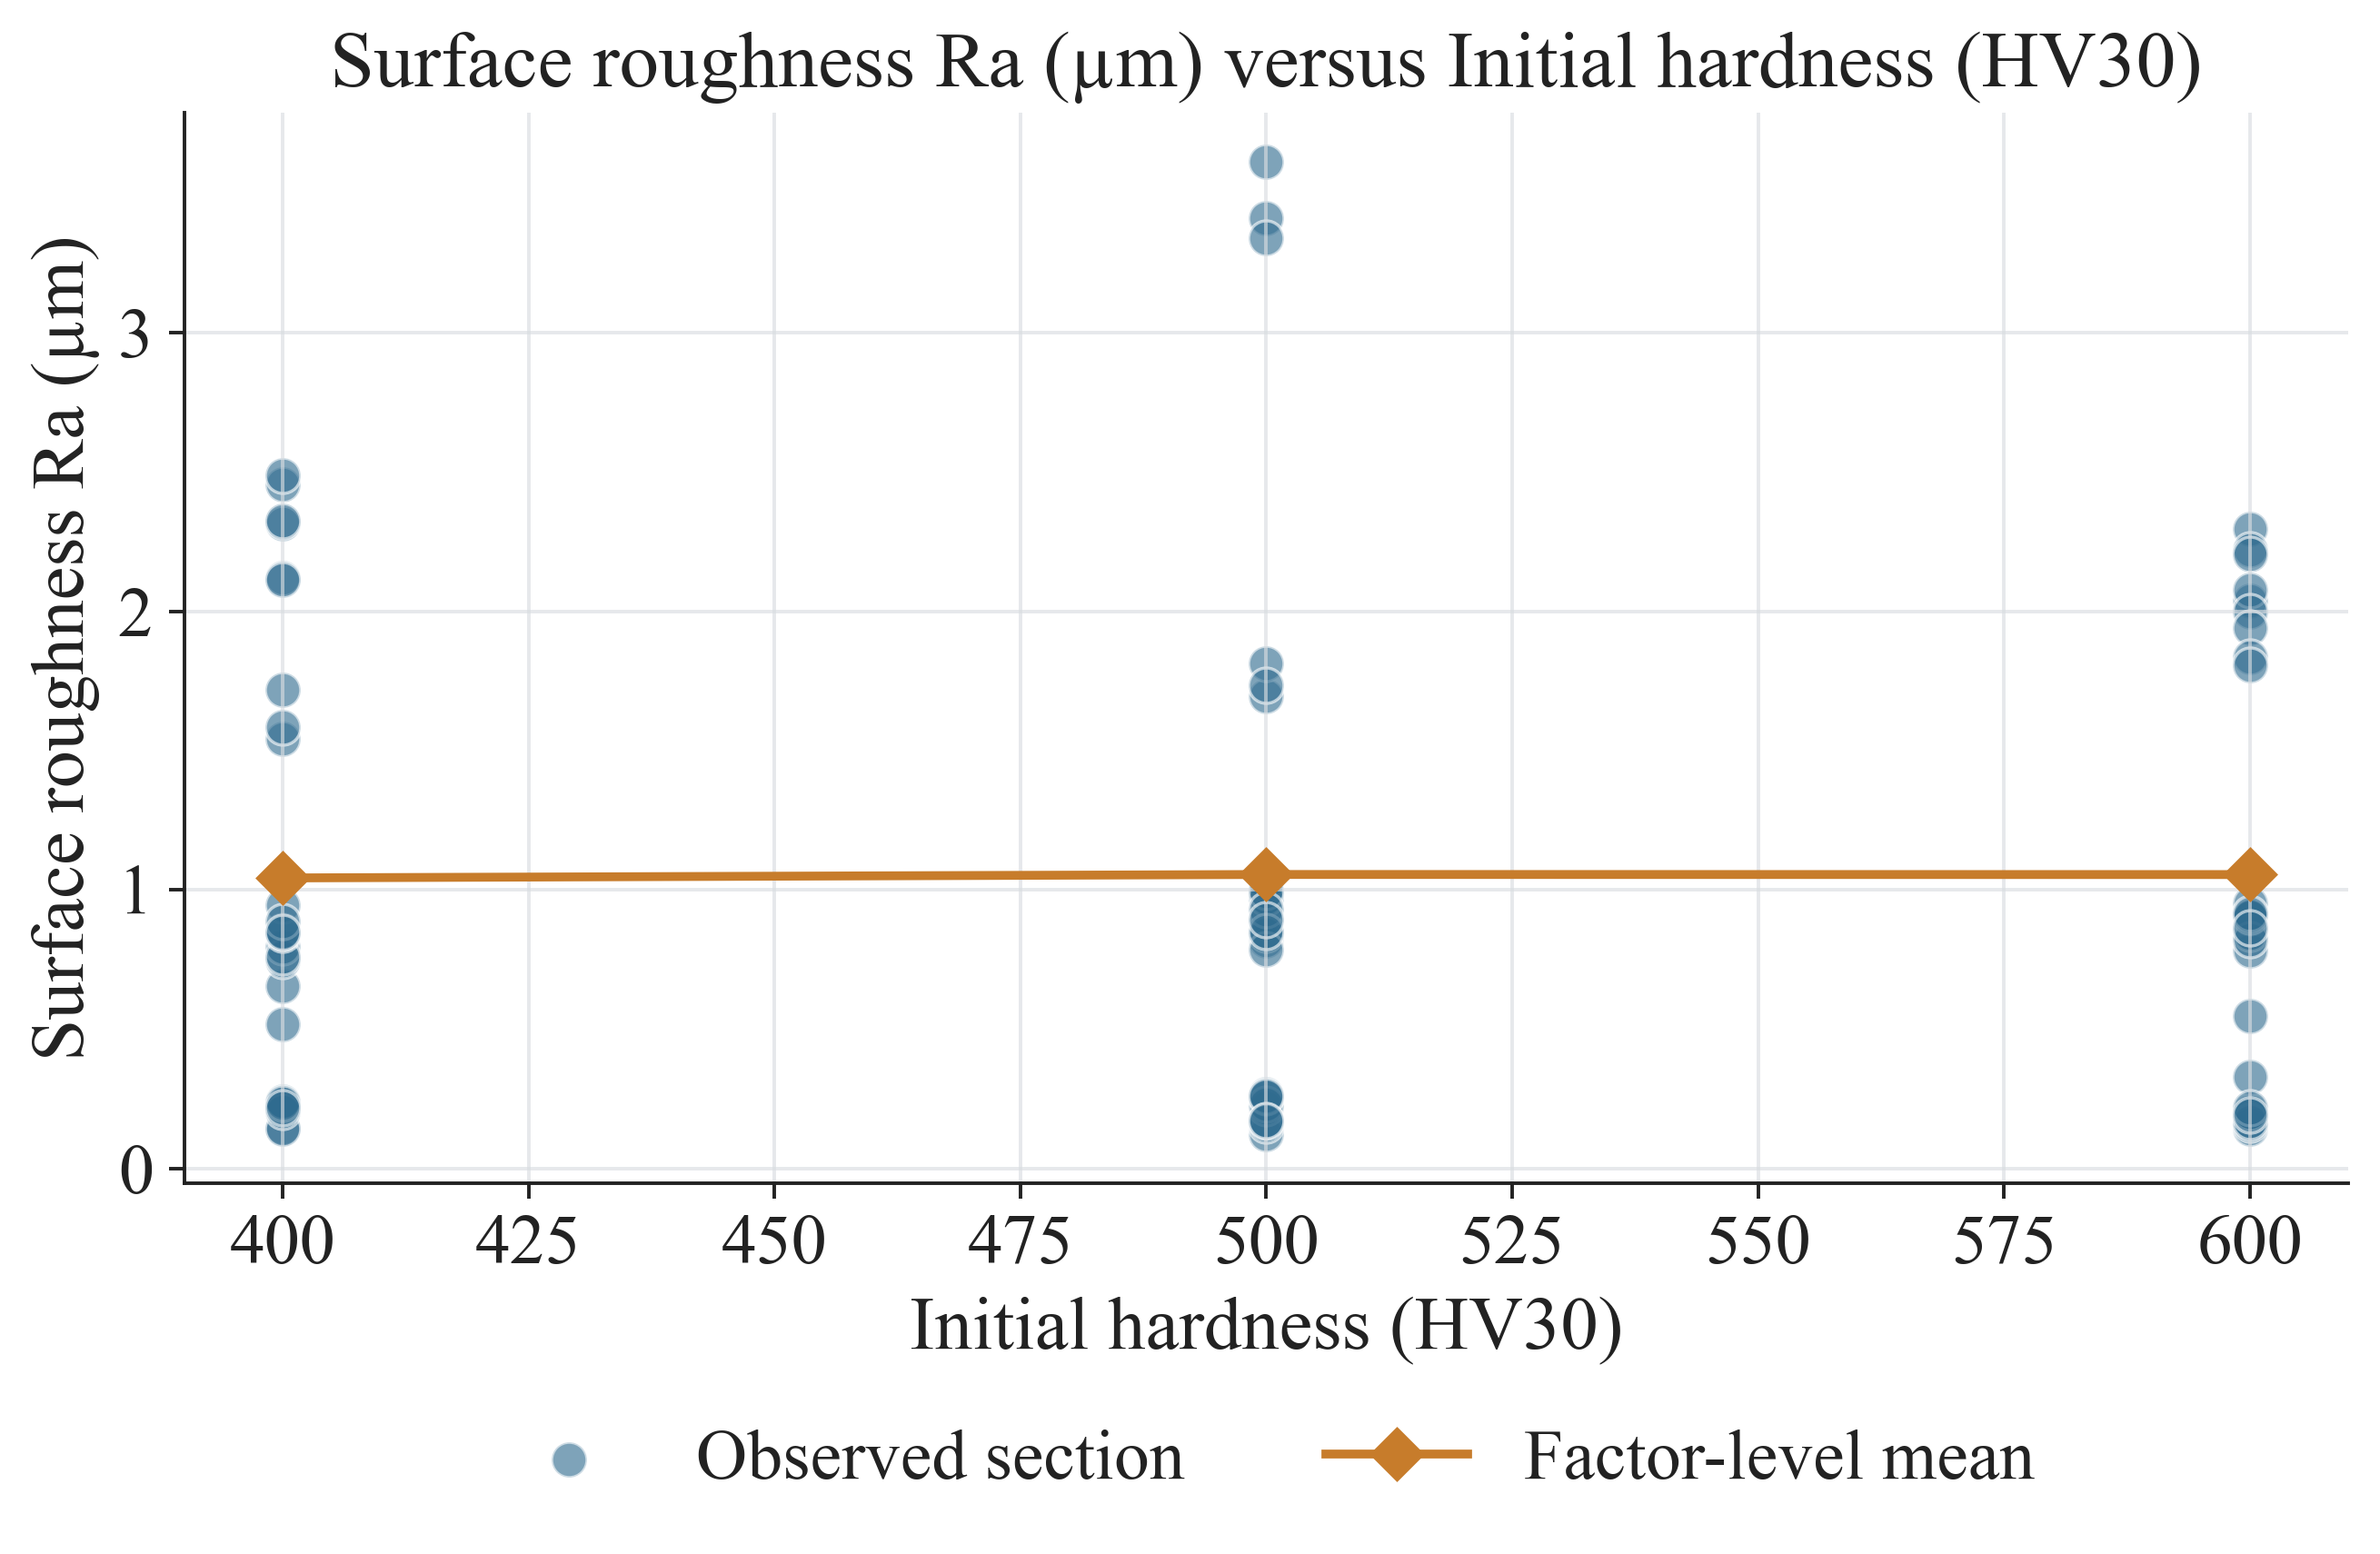

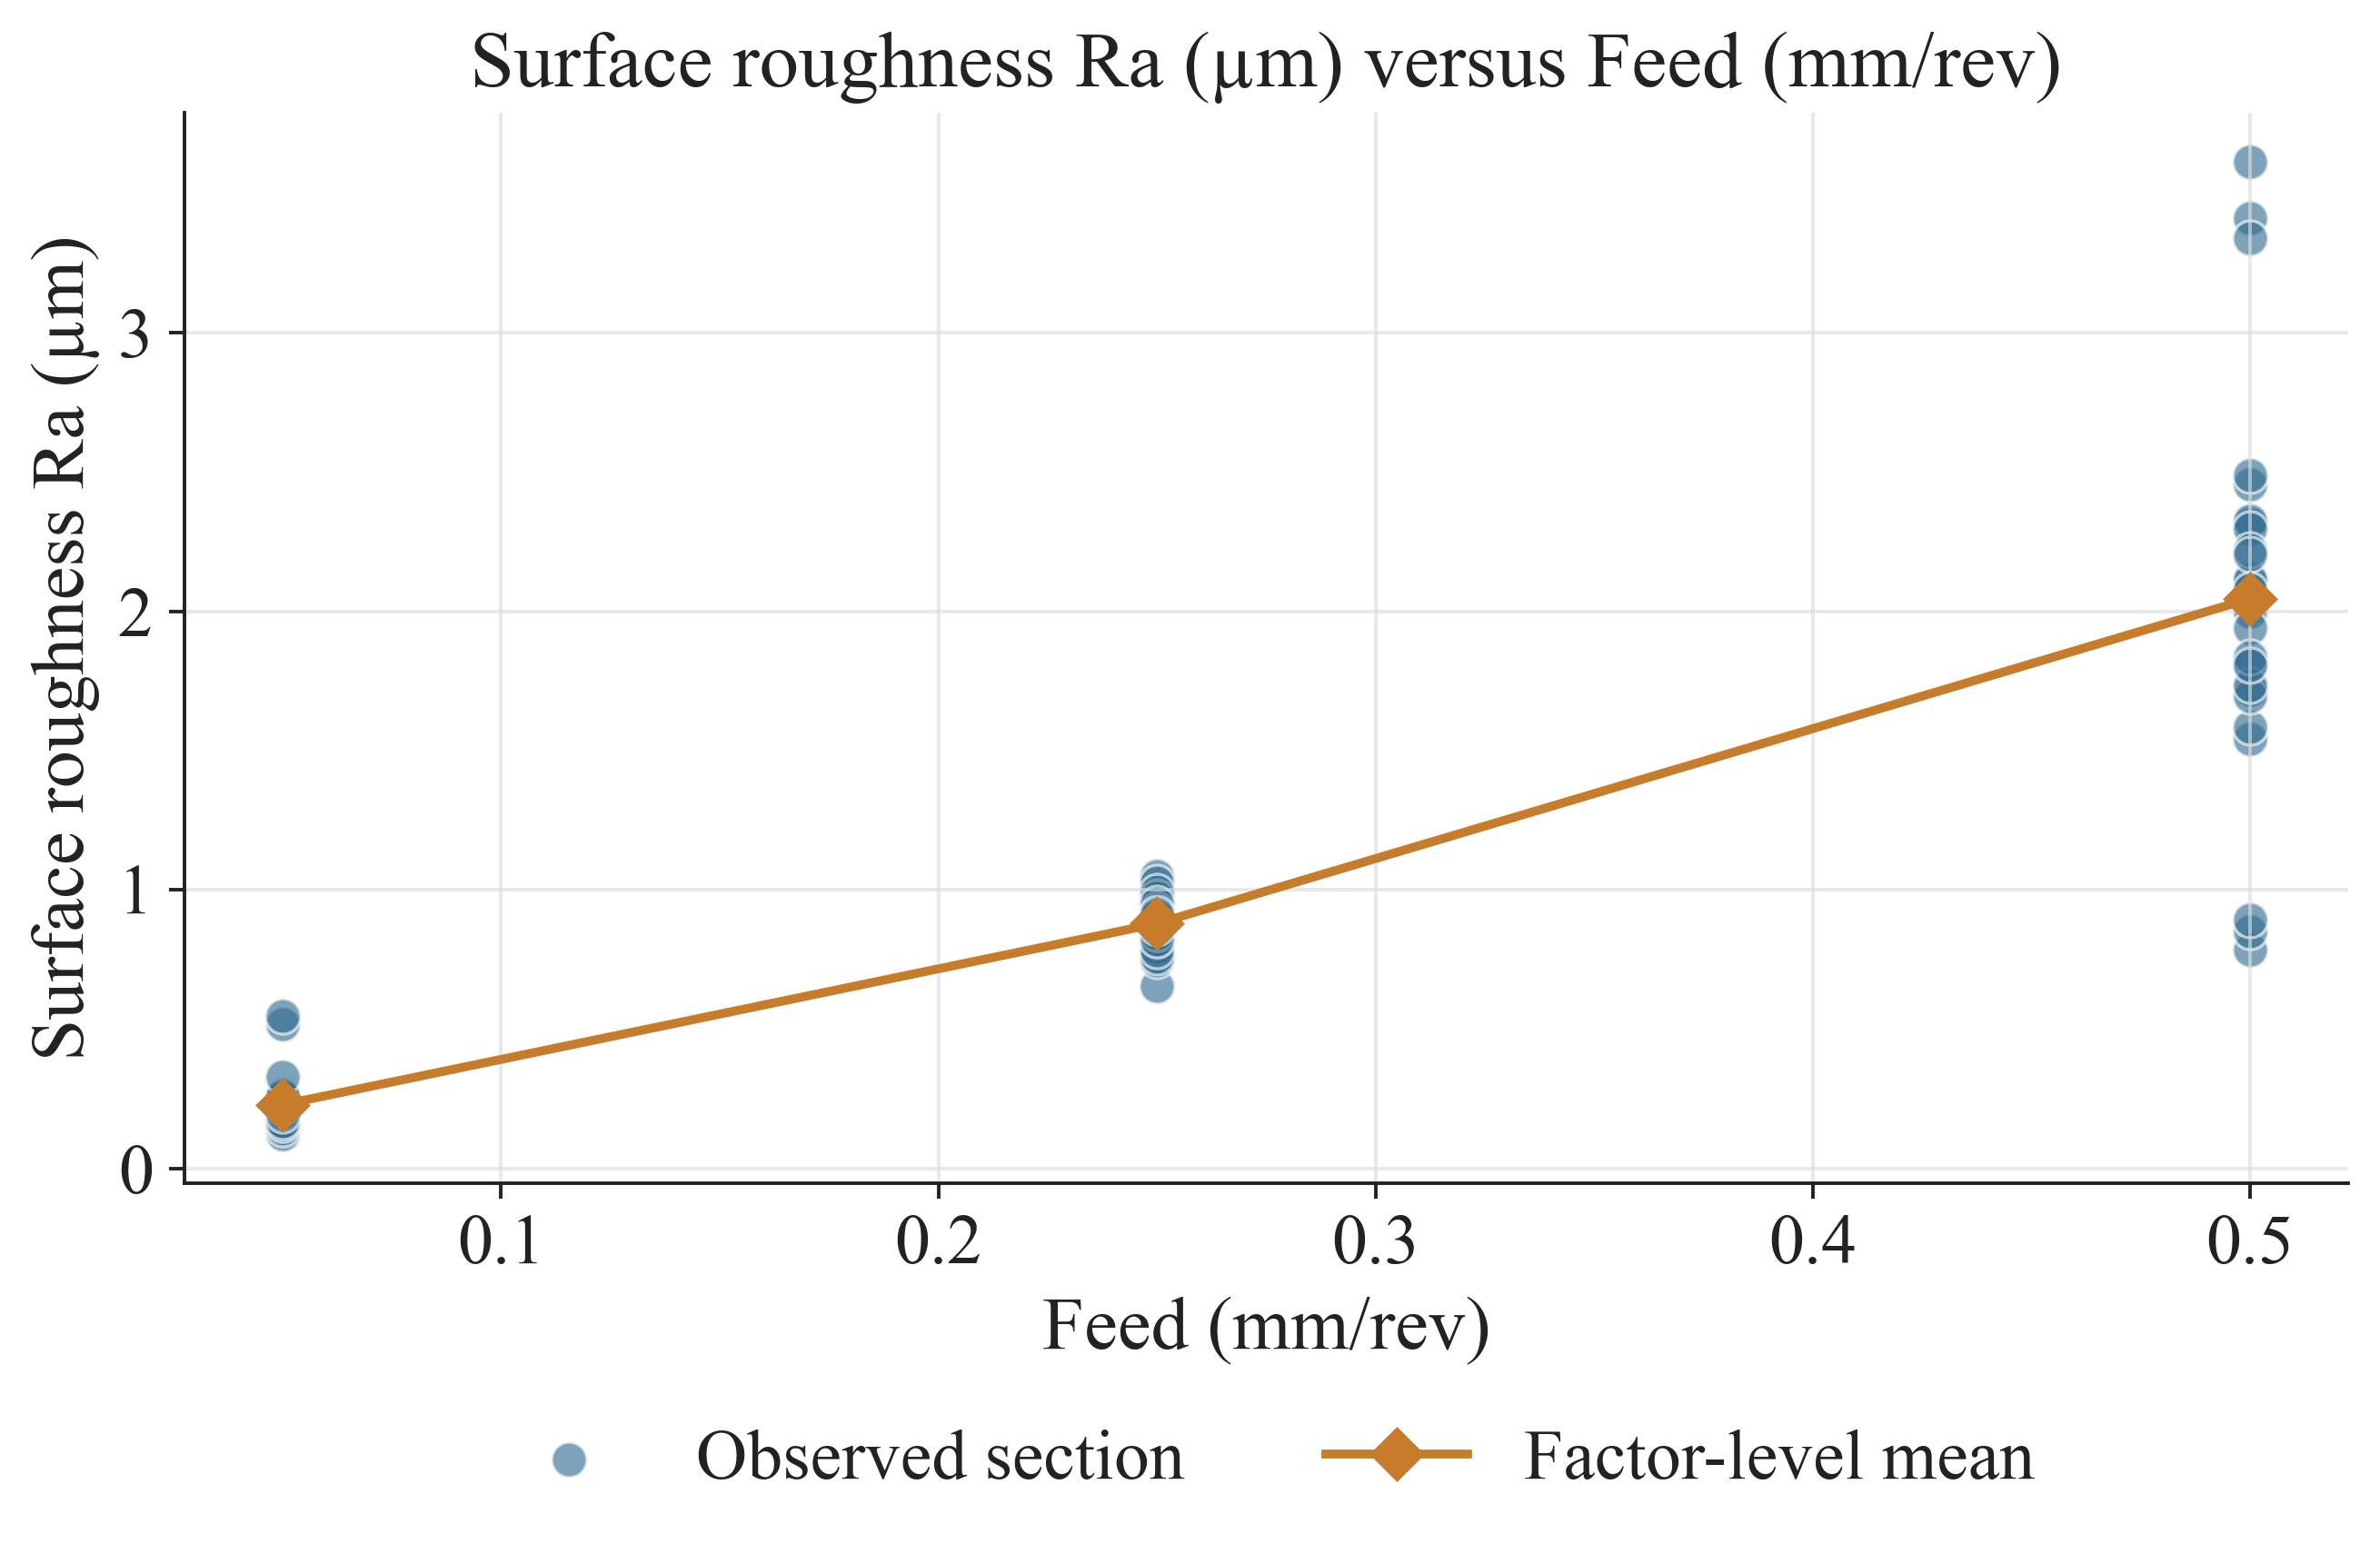

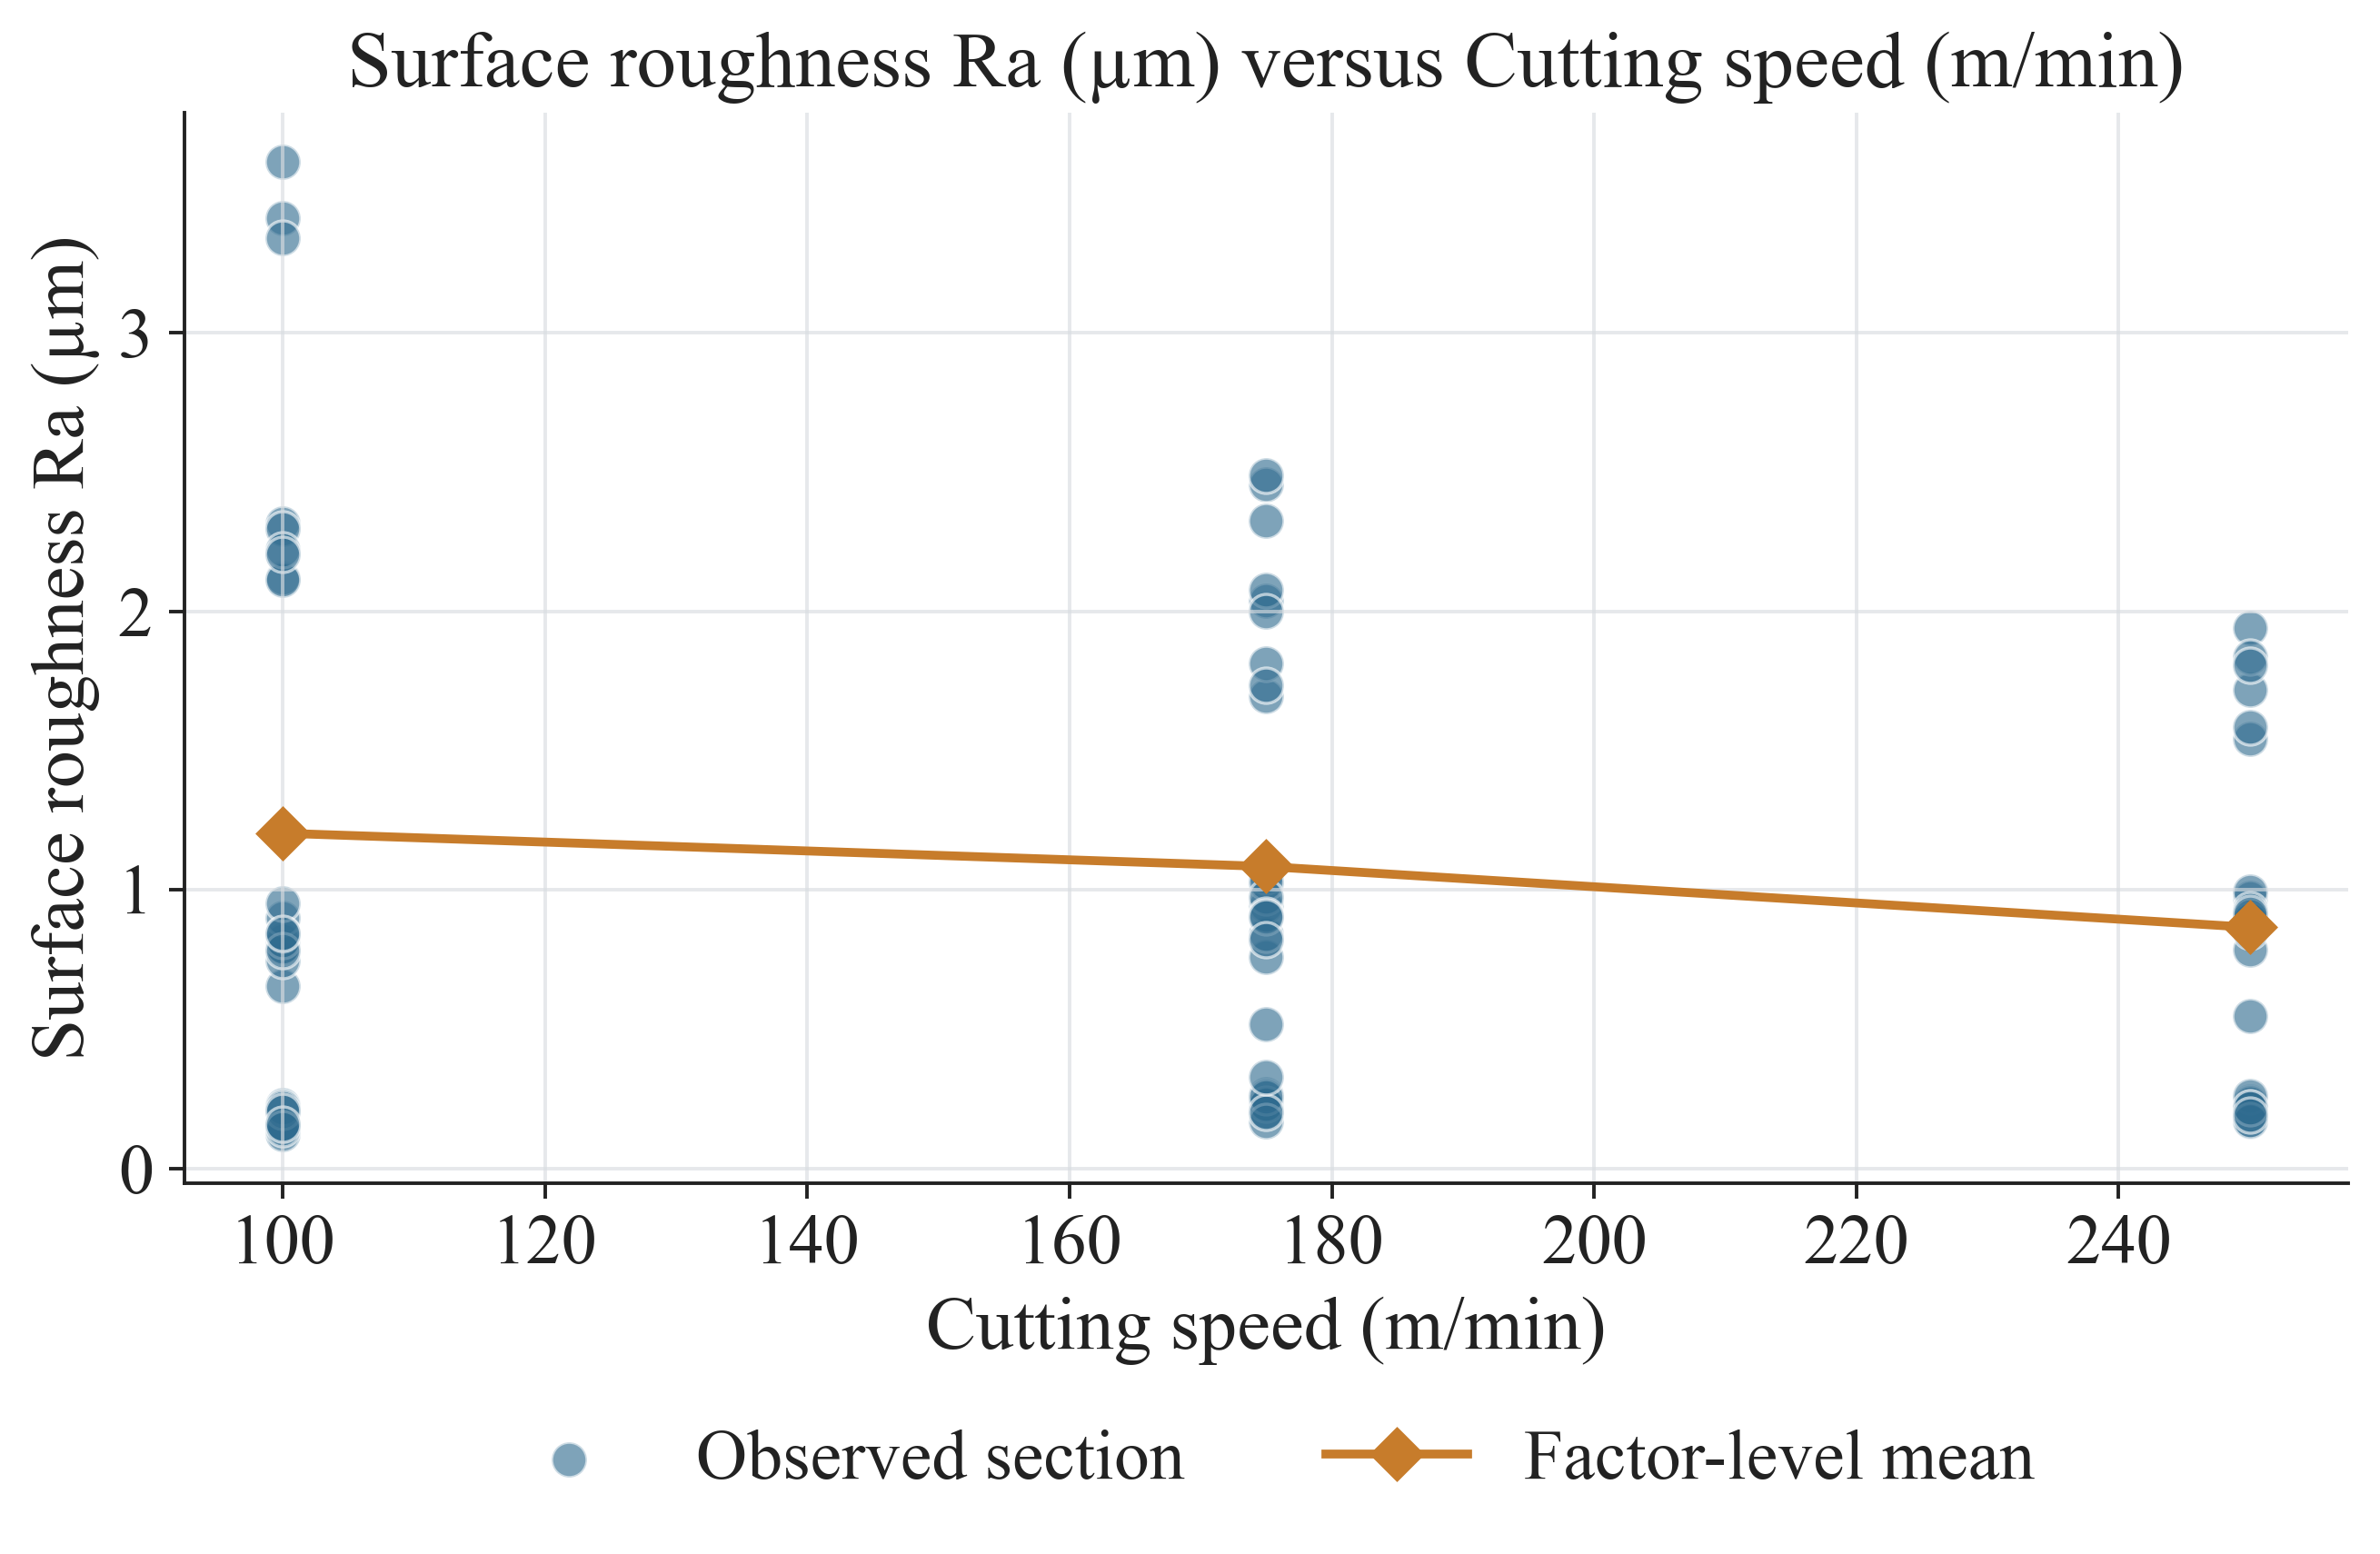

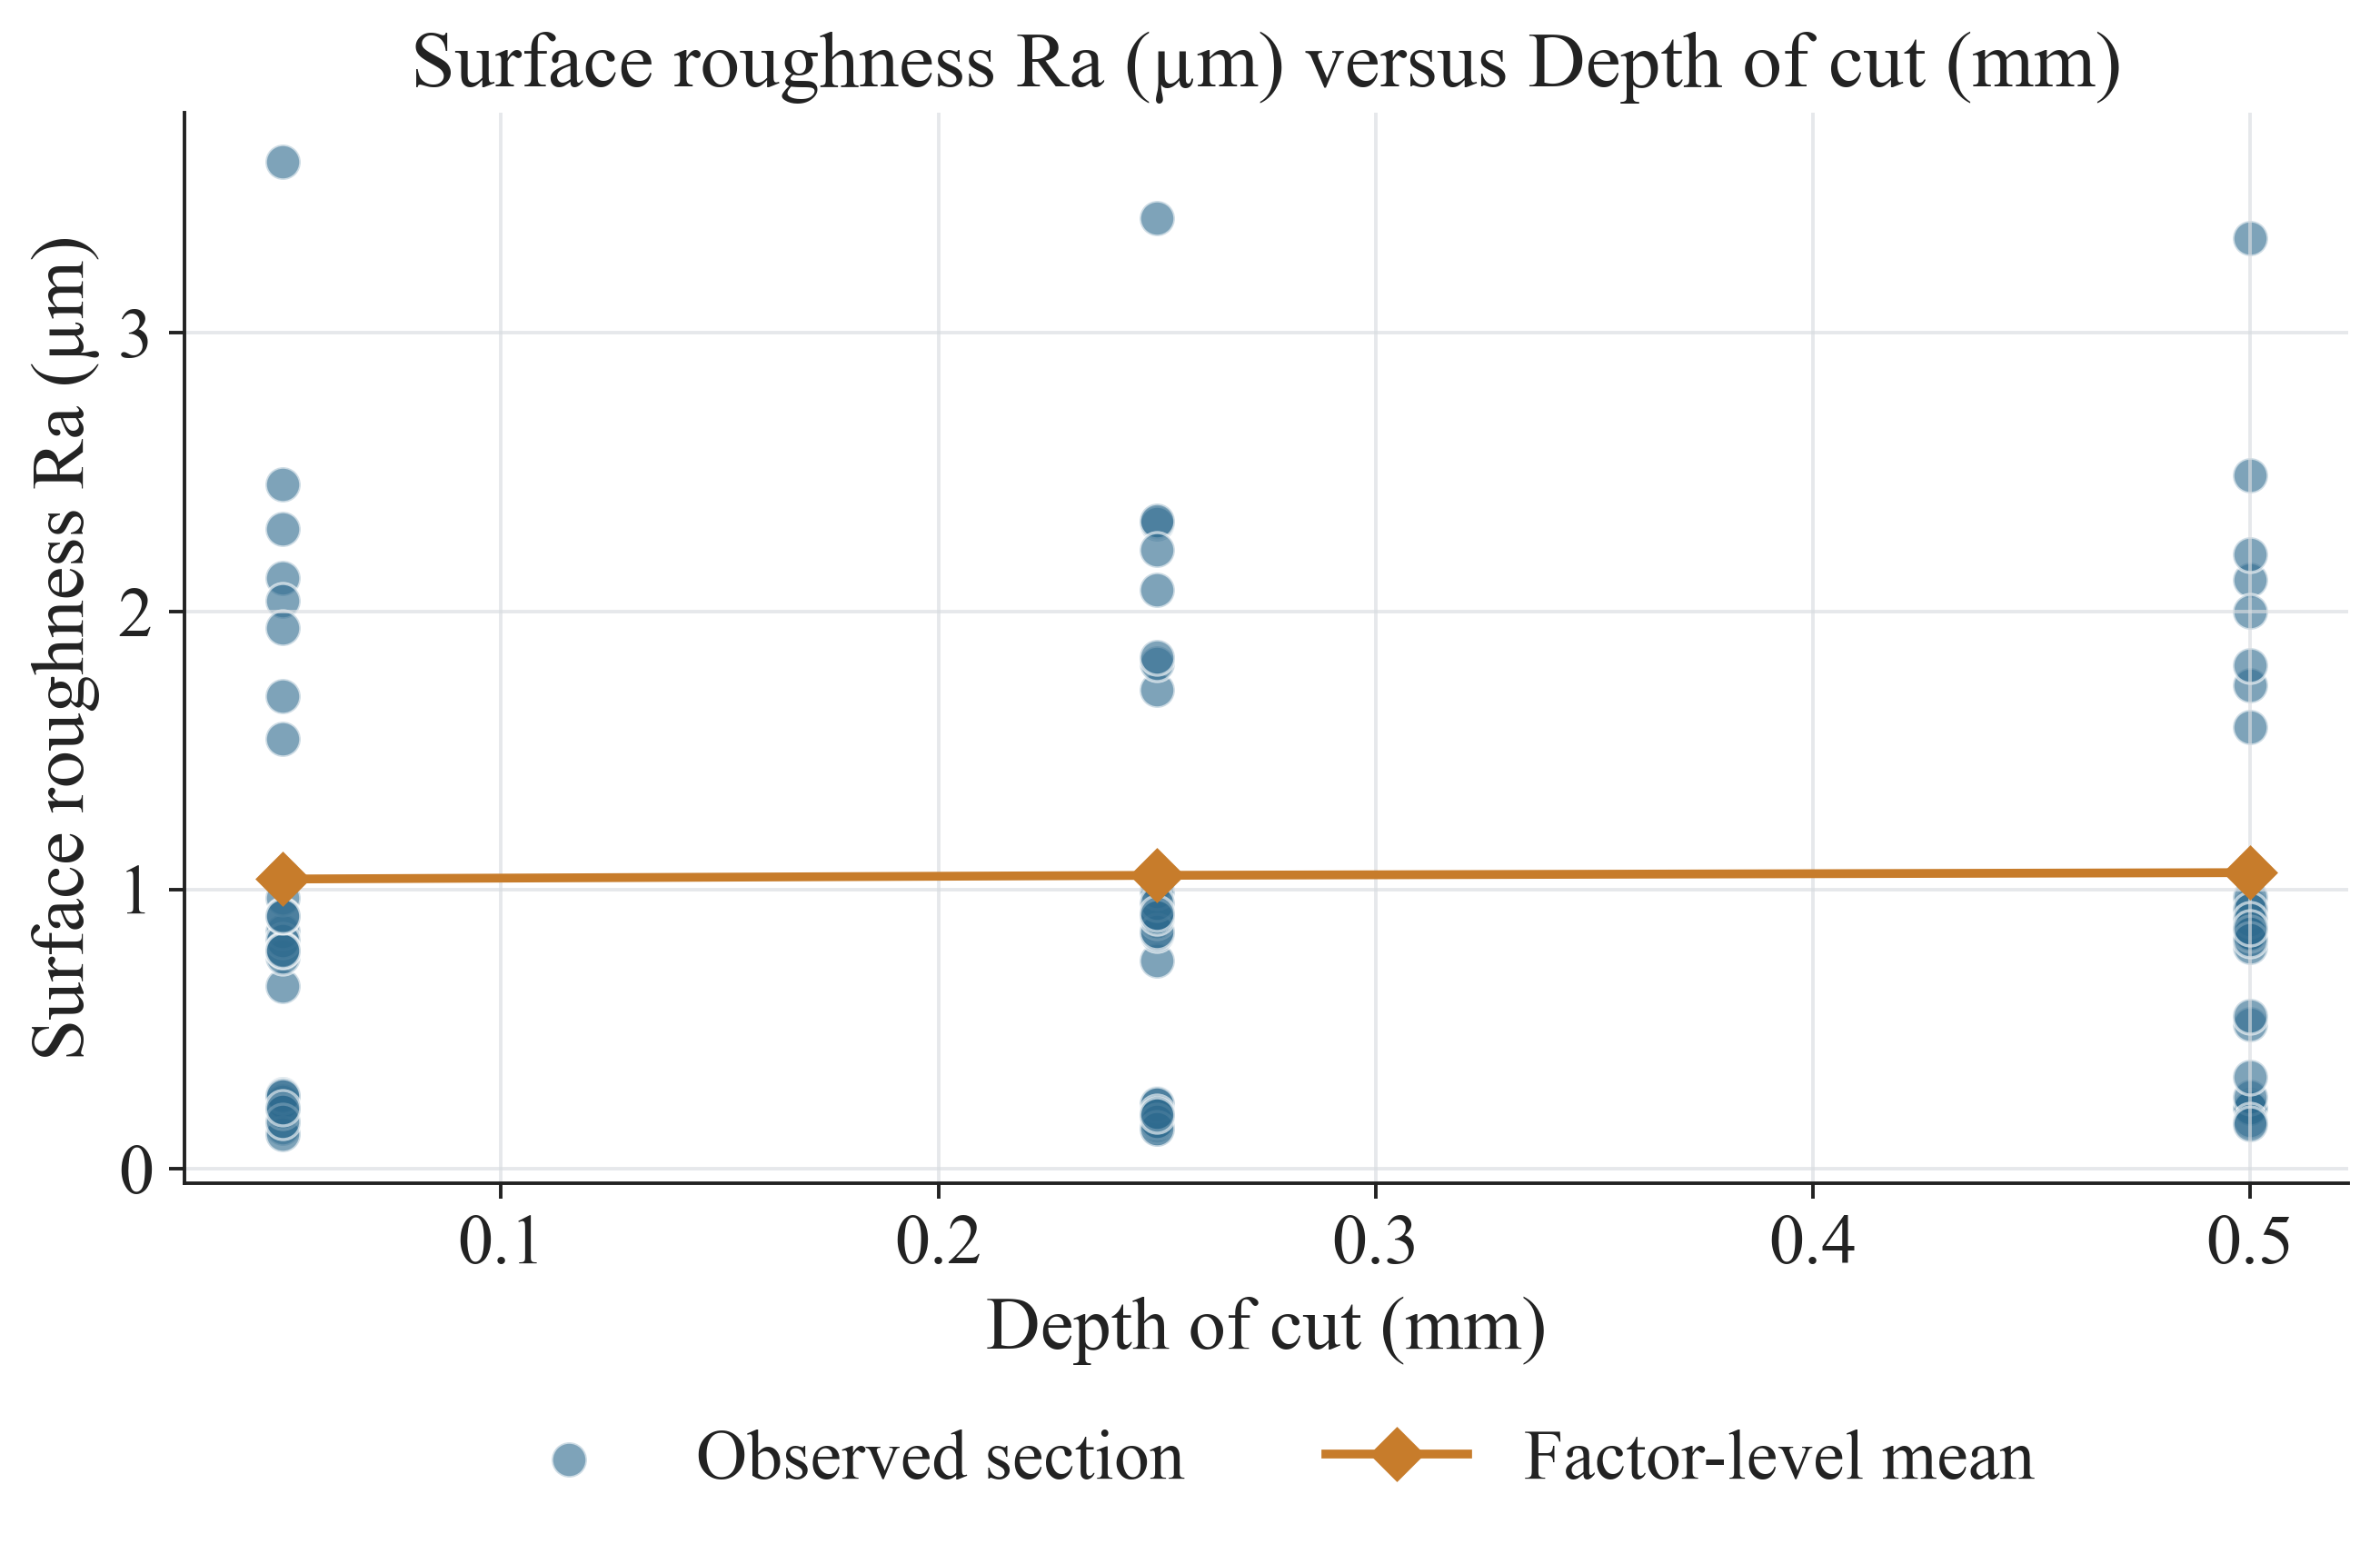

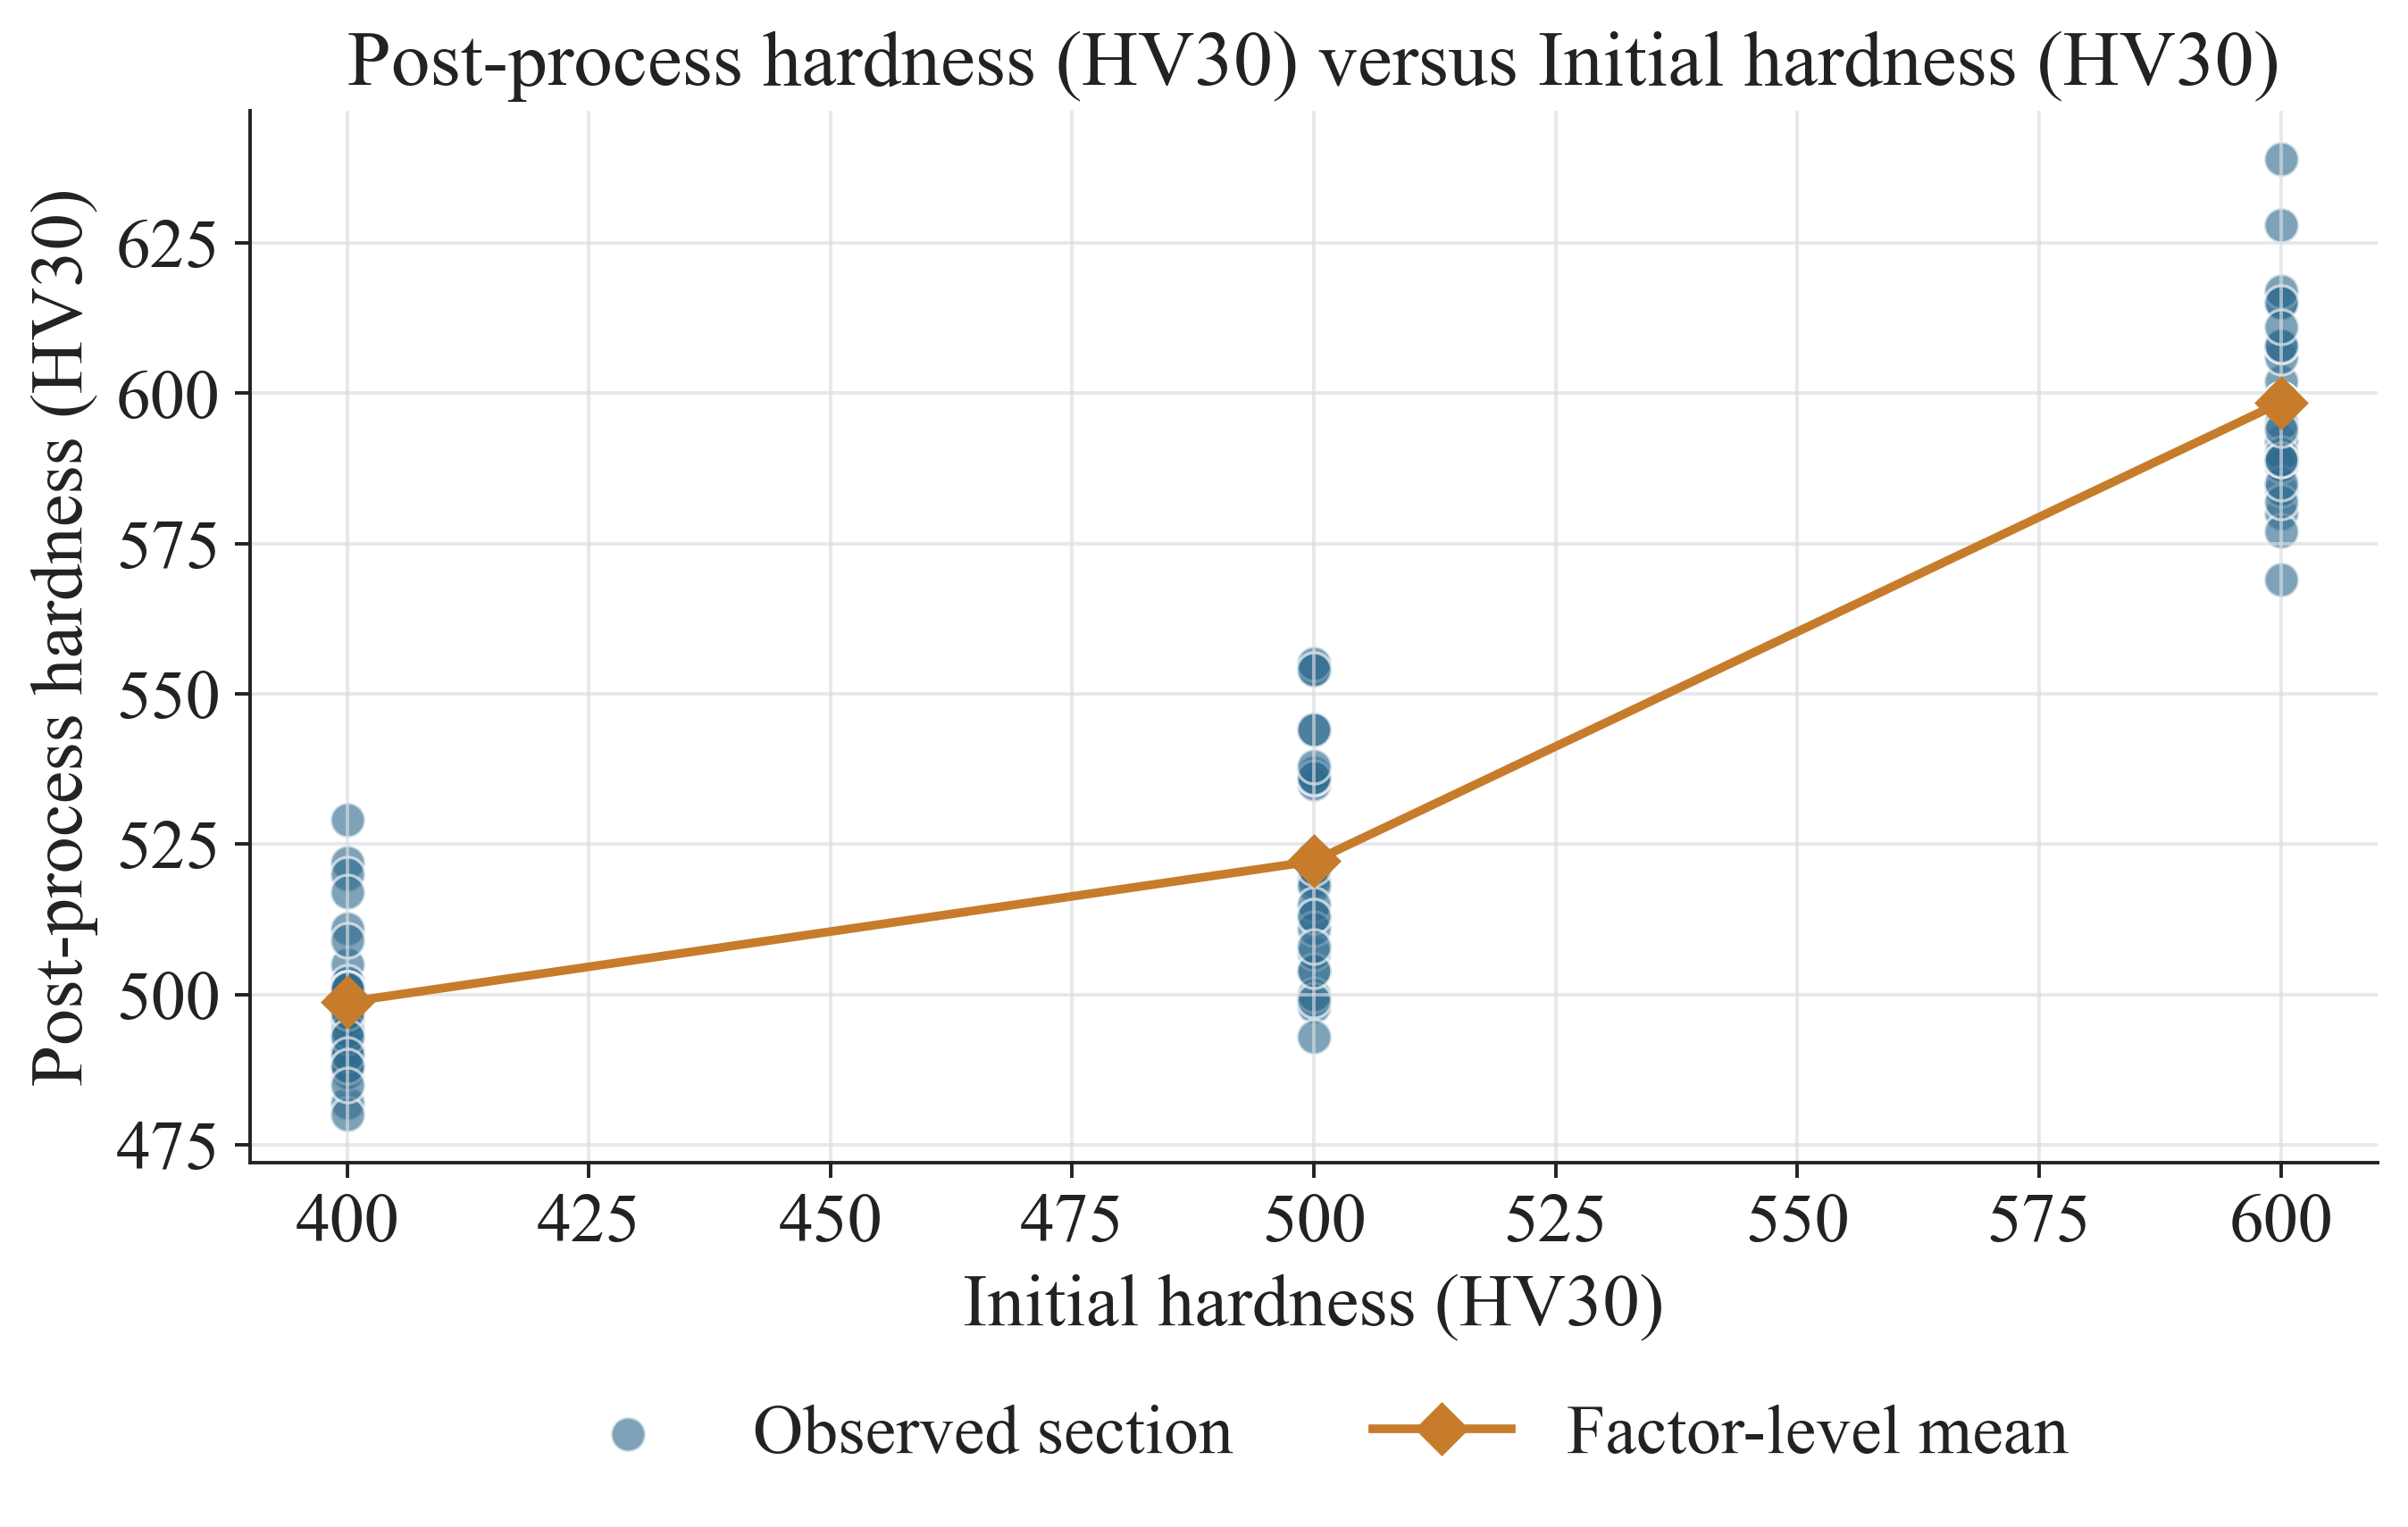

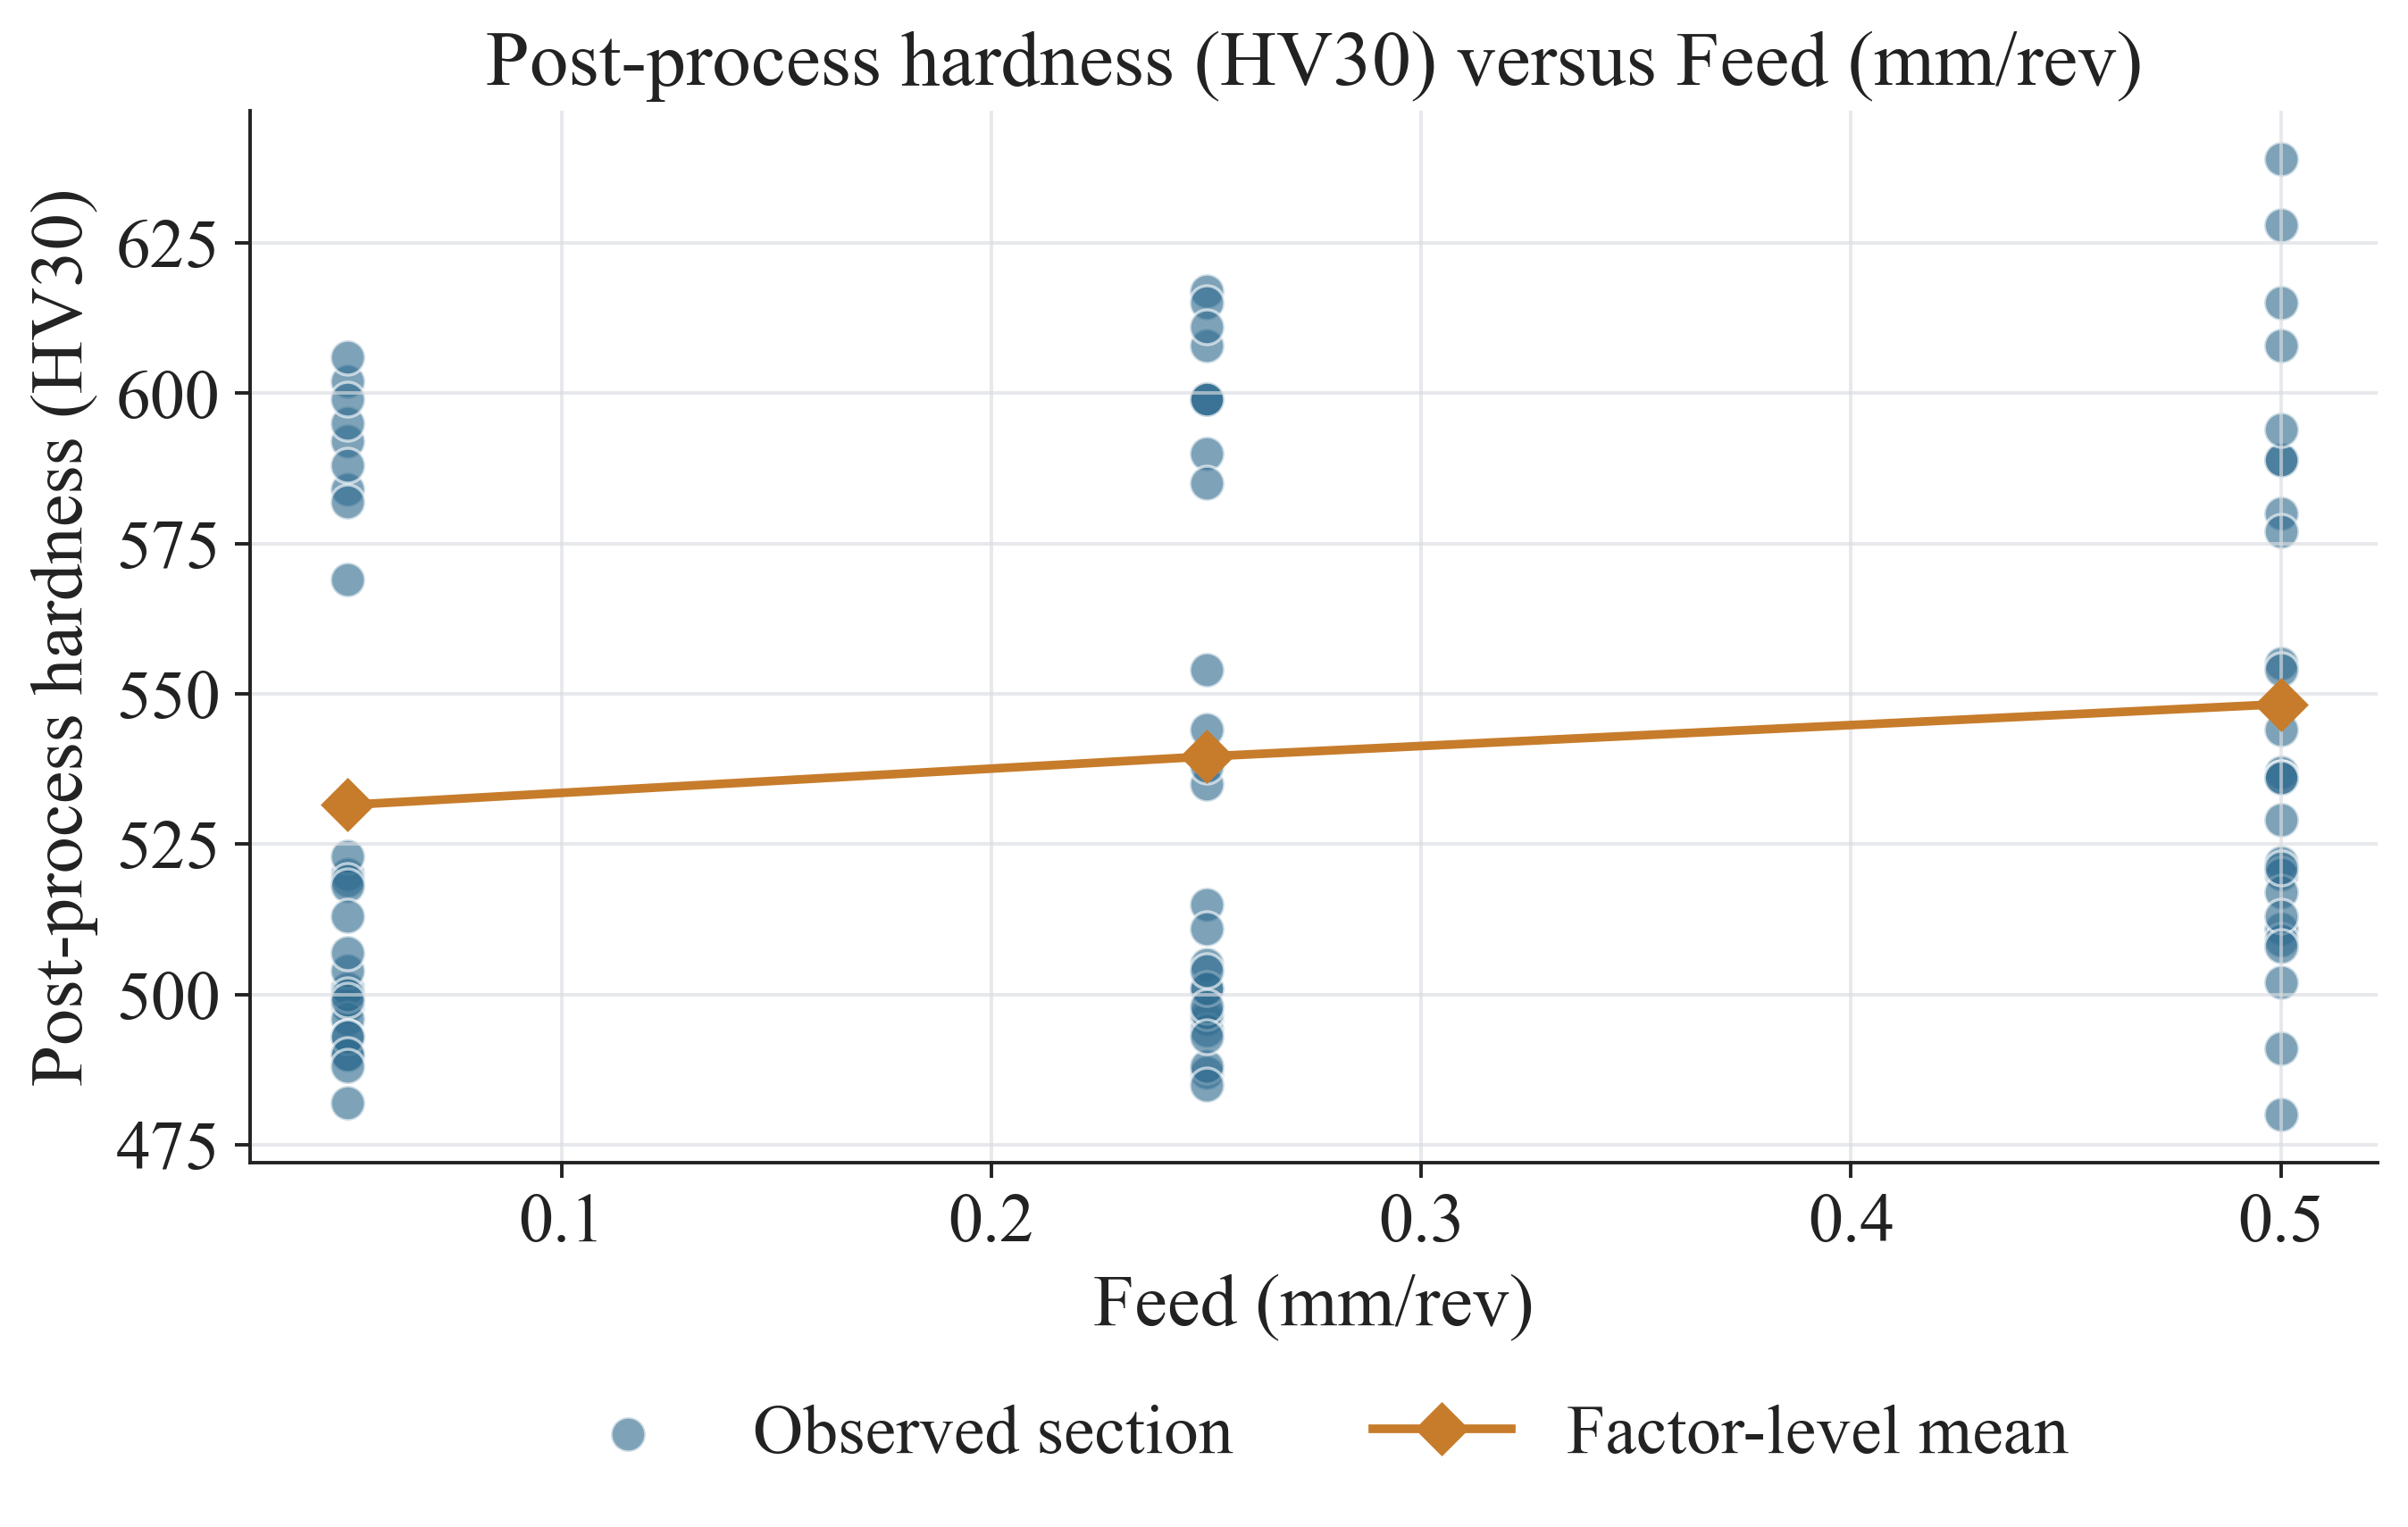

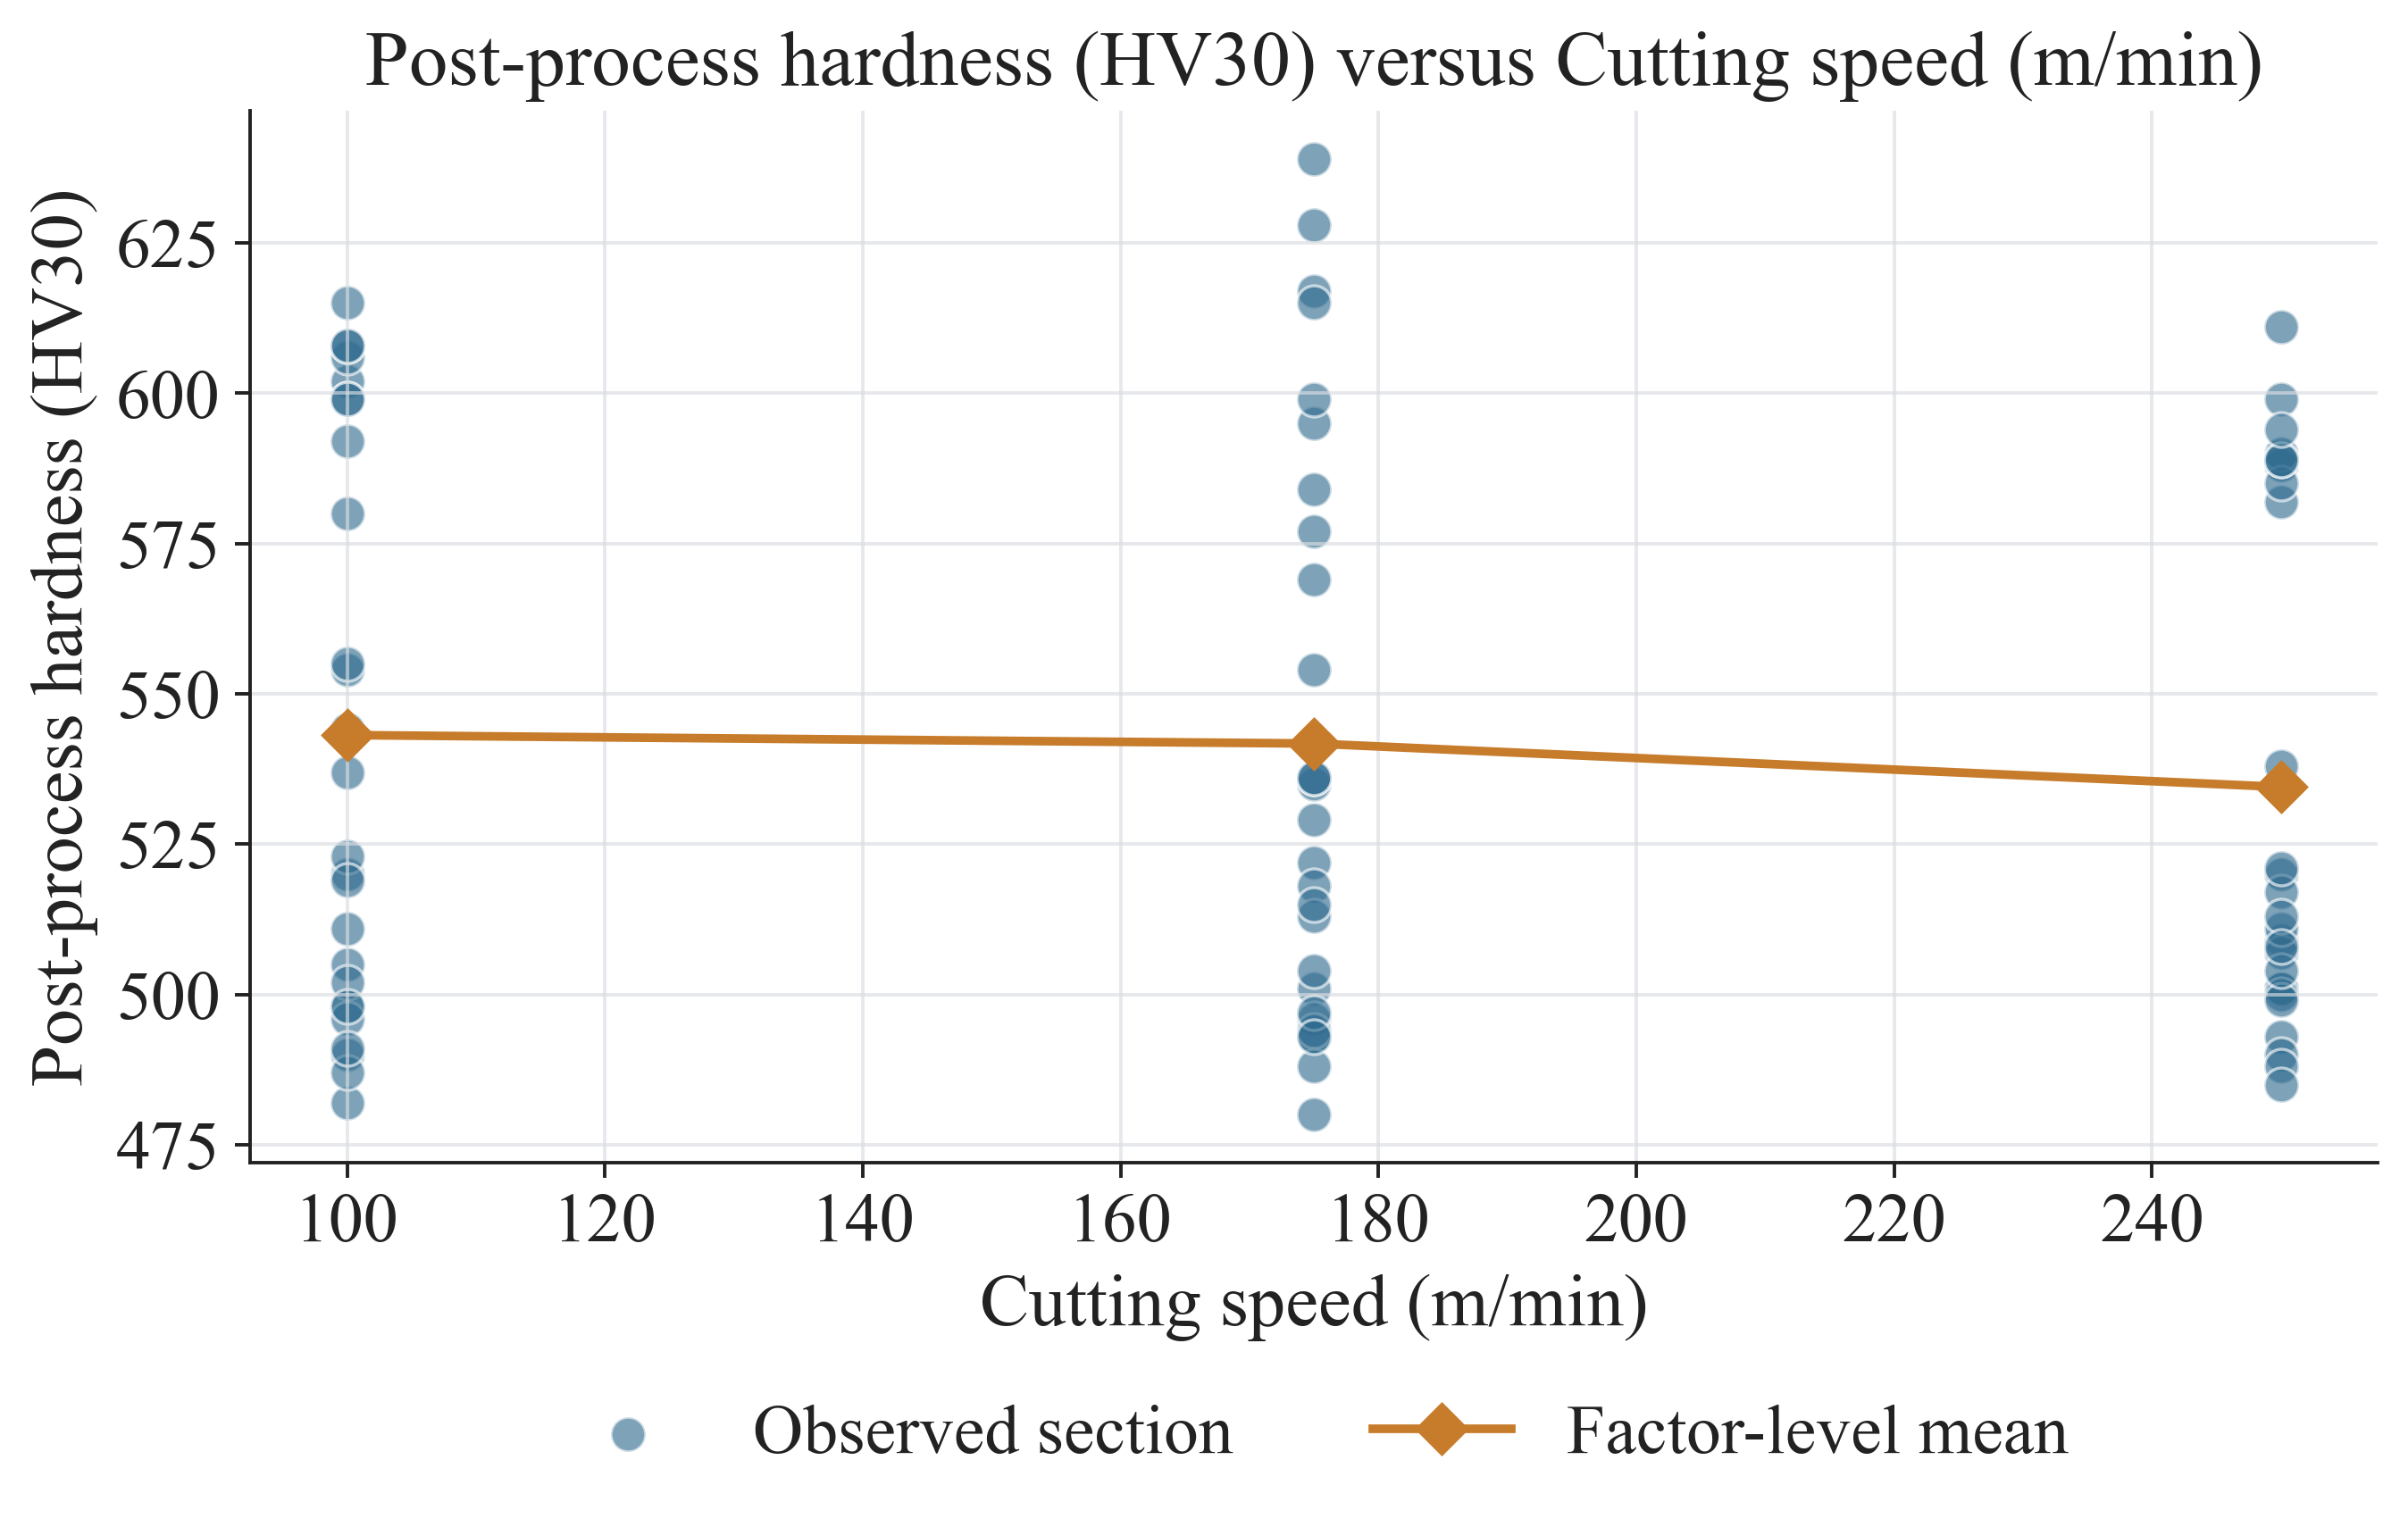

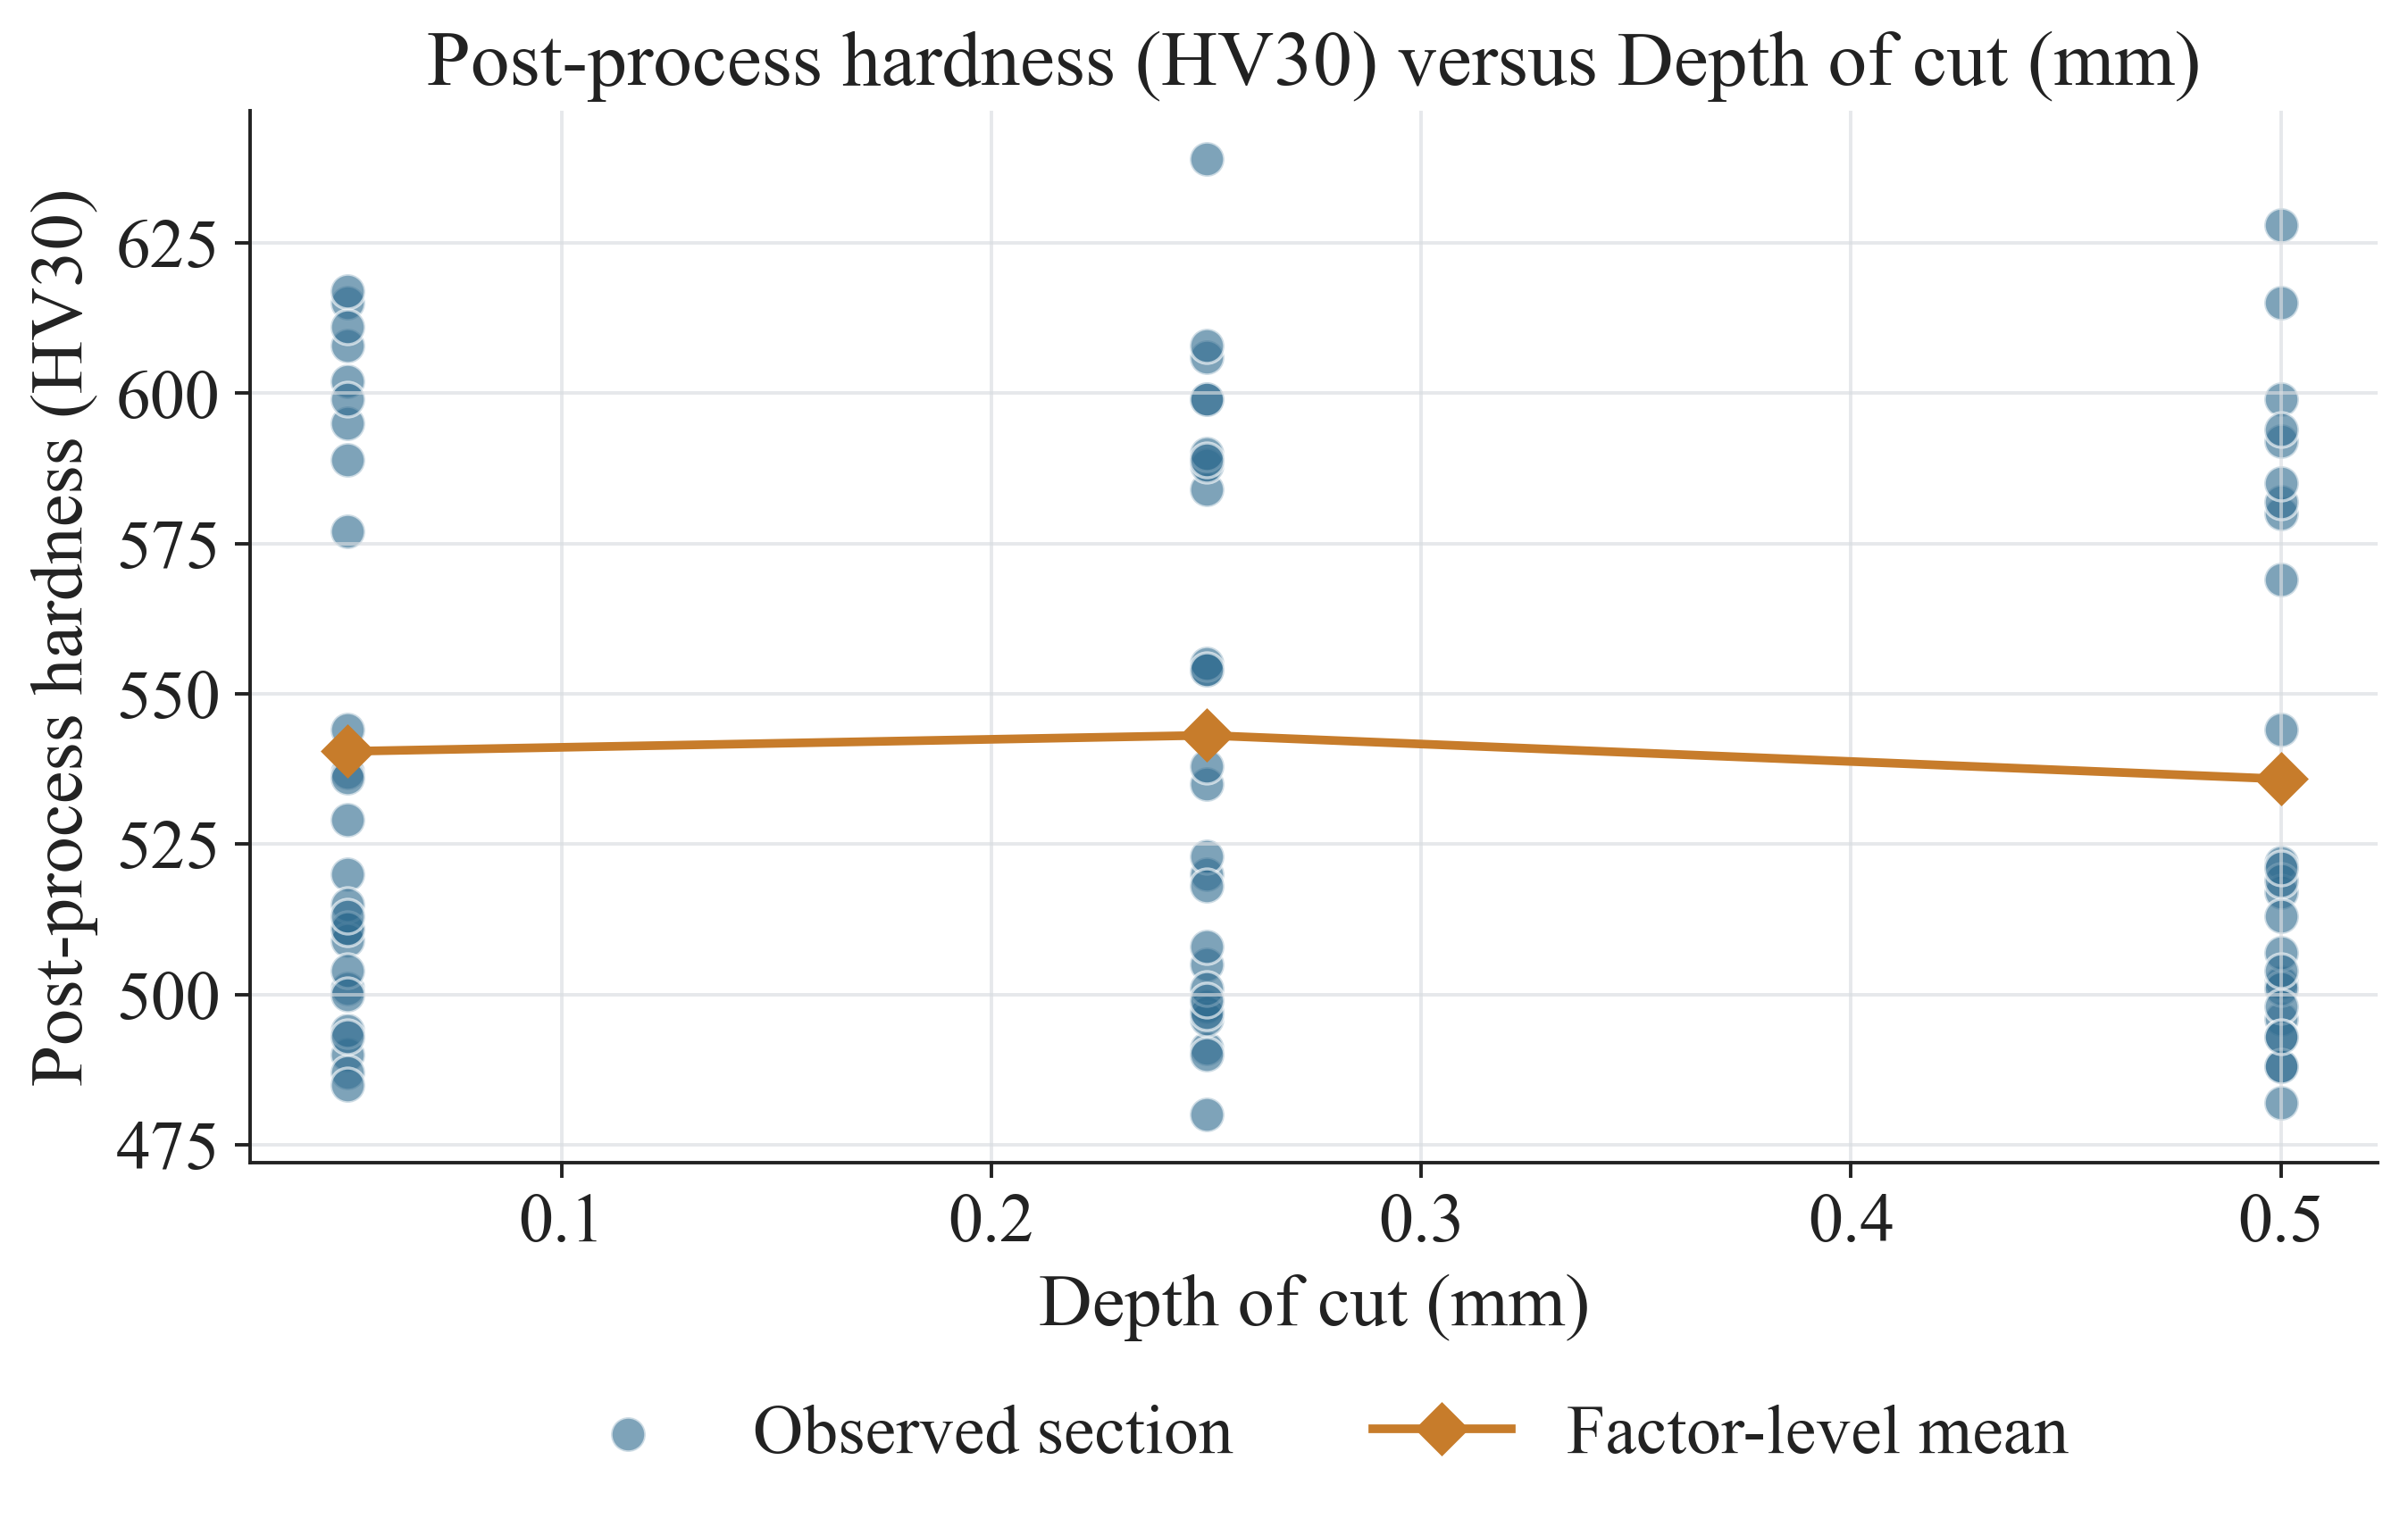

In [12]:
x_labels = {
    "HV_init_HV30": "Initial hardness (HV30)", "feed_mm_rev": "Feed (mm/rev)",
    "cutting_speed_m_min": "Cutting speed (m/min)", "depth_of_cut_mm": "Depth of cut (mm)",
}
feature_slugs = {
    "HV_init_HV30": "initial_hardness", "feed_mm_rev": "feed",
    "cutting_speed_m_min": "cutting_speed", "depth_of_cut_mm": "depth_of_cut",
}
target_specs = {
    TARGETS[0]: ("Surface roughness Ra (µm)", "ra"),
    TARGETS[1]: ("Post-process hardness (HV30)", "hv30"),
}
relationship_source = data[PREDICTORS + TARGETS].copy()
for target in TARGETS:
    target_label, target_slug = target_specs[target]
    for feature in PREDICTORS:
        means = data.groupby(feature, as_index=False)[target].mean()
        fig, axis = plt.subplots(figsize=(8.4, 5.8))
        axis.scatter(data[feature], data[target], color=PALETTE["blue"], alpha=0.62,
                     edgecolor="white", linewidth=0.7, label="Observed section")
        axis.plot(means[feature], means[target], color=PALETTE["orange"], marker="D",
                  label="Factor-level mean")
        axis.set_title(f"{target_label} versus {x_labels[feature]}")
        axis.set_xlabel(x_labels[feature])
        axis.set_ylabel(target_label)
        axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
        fig.subplots_adjust(left=0.17, right=0.98, top=0.88, bottom=0.30)
        stem = f"eda_relationship_{target_slug}_{feature_slugs[feature]}"
        save_scientific_figure(fig, stem, relationship_source[[feature, target]])
        display(fig)
        plt.close(fig)

Factor-level means show that the two outputs respond differently across the controlled settings, while within-level scatter indicates interactions among factors. These plots do not justify a causal single-factor interpretation because all settings belong to a multivariable factorial experiment. The modeling branch must compare smooth, kernel, tree, boosting, and compact neural inductive biases.


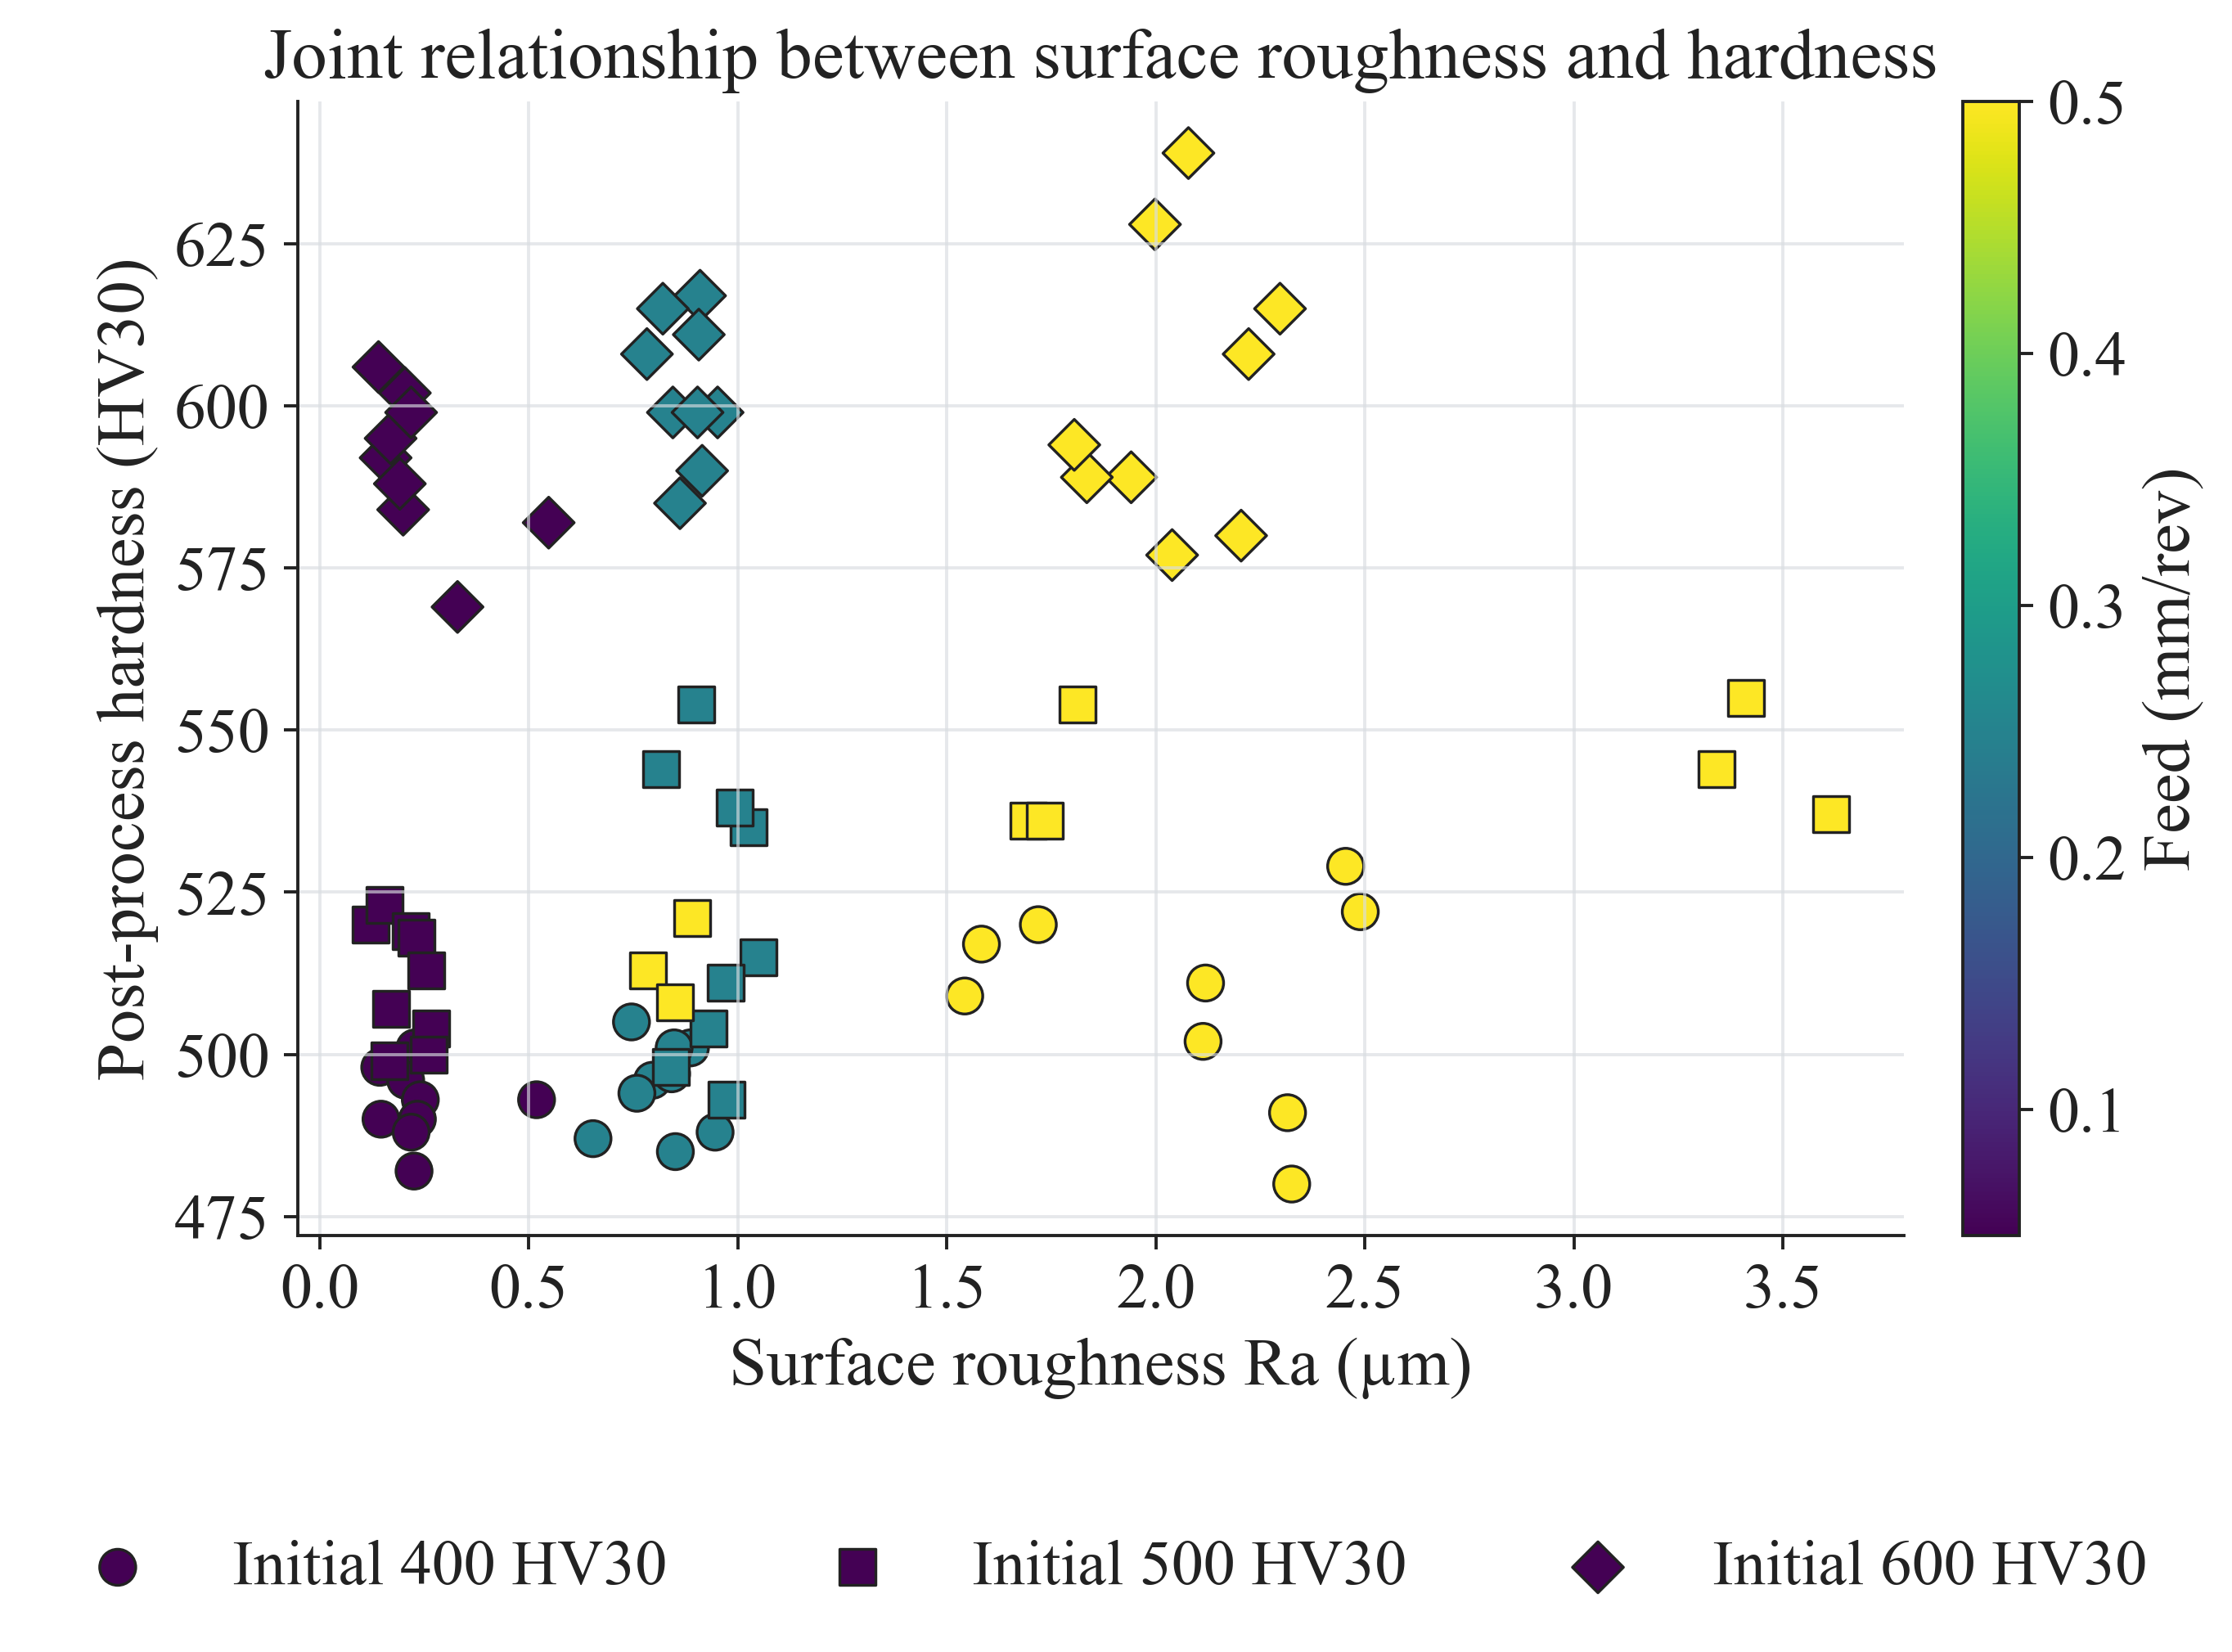

In [13]:
marker_map = {400: "o", 500: "s", 600: "D"}
fig, axis = plt.subplots(figsize=(9.0, 6.6))
for hardness, marker in marker_map.items():
    part = data[data.HV_init_HV30.eq(hardness)]
    scatter = axis.scatter(
        part.surface_roughness_Ra_um, part.post_process_hardness_HV30,
        c=part.feed_mm_rev, cmap="viridis", vmin=data.feed_mm_rev.min(),
        vmax=data.feed_mm_rev.max(), marker=marker, s=82,
        edgecolor=PALETTE["black"], linewidth=0.7, label=f"Initial {hardness} HV30",
    )
axis.set_title("Joint relationship between surface roughness and hardness")
axis.set_xlabel("Surface roughness Ra (µm)")
axis.set_ylabel("Post-process hardness (HV30)")
colorbar = fig.colorbar(scatter, ax=axis, pad=0.03)
colorbar.set_label("Feed (mm/rev)")
colorbar.ax.tick_params(labelsize=16)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.37), ncol=3, frameon=False)
fig.subplots_adjust(left=0.16, right=0.92, top=0.88, bottom=0.28)
joint_source = data[["surface_roughness_Ra_um", "post_process_hardness_HV30", "feed_mm_rev", "HV_init_HV30"]]
save_scientific_figure(fig, "eda_joint_target_relationship", joint_source)
display(fig)
plt.close(fig)

The joint target cloud is structured by initial hardness and feed but does not collapse to a single monotonic trade-off. This supports target-wise models and target-wise error reporting. Any later Pareto analysis must remain inside the observed 81 factorial settings and must not claim that maximum hardness is universally optimal.


## 6. Frozen scientific decisions for preprocessing and validation


In [14]:
scientific_contract = pd.DataFrame([
    {"Decision": "Allowed measured predictors", "Frozen rule": ", ".join(PREDICTORS)},
    {"Decision": "Targets", "Frozen rule": "Ra (µm) and post-process hardness (HV30), evaluated separately"},
    {"Decision": "Forbidden predictors", "Frozen rule": "Outcomes Ra, Rz, post-process HV30; specimen/section identifiers; unavailable variables"},
    {"Decision": "Design hierarchy", "Frozen rule": "Between-specimen HV_init, feed, and cutting speed; within-specimen depth section"},
    {"Decision": "Prediction / inferential unit", "Frozen rule": "Section-level predictions; specimen-level resampling and inference"},
    {"Decision": "Grouping", "Frozen rule": "All three sections of a specimen remain in one fold"},
    {"Decision": "Outer evaluation", "Frozen rule": "Nine balanced specimen-group folds; every row receives one OOF prediction"},
    {"Decision": "Inner selection", "Frozen rule": "Four specimen-group folds inside each outer-training partition"},
    {"Decision": "Preprocessing", "Frozen rule": "Fit scaling, selection, fusion, and uncertainty calibration on training partitions only"},
    {"Decision": "Independent validation", "Frozen rule": "Not performed; no methodologically compatible independent dataset with paired Ra/HV30 outcomes was identified"},
])
clean_columns = ["specimen_id", "section_id"] + PREDICTORS + TARGETS + ["surface_roughness_Rz_um"]
data[clean_columns].to_csv(UNIFIED_DIR / "unified_dataset.csv", index=False)
scientific_contract.to_csv(AUDIT_DIR / "research_scope_summary.csv", index=False)
display_grouped_table(scientific_contract, "Frozen research and leakage-control contract")


**Frozen research and leakage-control contract — Complete table**

Decision,Frozen rule
Allowed measured predictors,"HV_init_HV30, feed_mm_rev, cutting_speed_m_min, depth_of_cut_mm"
Targets,"Ra (µm) and post-process hardness (HV30), evaluated separately"
Forbidden predictors,"Outcomes Ra, Rz, post-process HV30; specimen/section identifiers; unavailable variables"
Design hierarchy,"Between-specimen HV_init, feed, and cutting speed; within-specimen depth section"
Prediction / inferential unit,Section-level predictions; specimen-level resampling and inference
Grouping,All three sections of a specimen remain in one fold
Outer evaluation,Nine balanced specimen-group folds; every row receives one OOF prediction
Inner selection,Four specimen-group folds inside each outer-training partition
Preprocessing,"Fit scaling, selection, fusion, and uncertainty calibration on training partitions only"
Independent validation,Not performed; no methodologically compatible independent dataset with paired Ra/HV30 outcomes was identified


## Limitations and hand-off

The primary study has 81 section rows but only 27 independent specimens, one steel grade, one fixed 0.8 mm tool radius, and three discrete levels per factor. No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain. Internal validation does not replace independent validation; confirmation on newly collected compatible specimens remains a prospective requirement. Notebook 02 therefore prepares only the primary factorial dataset and its immutable specimen-grouped validation contract.
